<h1 style="font-family:'Times New Roman';font-size:38px;"><font color='purple'><center>~ Computer Vision: Pneumonia_Detection Project ~</center></font></h1><br><br>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<h1 style="font-family:'Times New Roman';"><font color='navy'>Problem Definition and Statement</font></h1>

#### **Domain: Healthcare**
Medical imaging and artificial intelligence (AI) are increasingly being used to assist in disease diagnosis. Pneumonia is a serious lung infection that can be detected using chest X-rays. In this project, we aim to develop a **Deep Learning (DL)-based algorithm** to detect pneumonia from chest radiographs.

#### **Problem Statement**
The task is to build an AI model capable of detecting **lung opacities** (a key symptom of pneumonia) from **medical images**. The model should:
- **Identify pneumonia cases** based on chest X-ray images.
- **Locate lung opacities** by drawing bounding boxes on affected regions.
- **Classify images** into categories based on the presence of pneumonia.

#### **Context**
- **Medical images** are stored in **DICOM format (`*.dcm`)**, which contain metadata and pixel data.
- The dataset contains **annotated images** with bounding boxes that mark pneumonia regions.
- Some images may have **abnormalities** but **no pneumonia**, making classification more challenging.

#### **Dataset Information**
The dataset used in this project comes from the **RSNA Pneumonia Detection Challenge** and consists of:
- **Chest X-ray images** in **DICOM format**.
- **Labels for each image**, including:
  - **Pneumonia positive cases** (with bounding boxes).
  - **No pneumonia cases** (either normal or with other lung abnormalities).

<h1 style="font-family:'Times New Roman';"><font color='navy'>Objective</font></h1>

Design a **Deep Learning model** that:
1. **Classifies** chest X-rays as "Pneumonia" or "No Pneumonia".
2. **Detects and localizes** pneumonia-affected areas in the images.

In [ ]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

<h1 style="font-family:'Times New Roman';"><font color='navy'>✅ Milestone 1</font></h1>



<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 1: Import the Data</b></font></h3>

In [ ]:
import pandas as pd

# Load the CSV files
class_info_df = pd.read_csv("/content/drive/MyDrive/AIML/capstoneproject/stage_2_detailed_class_info.csv")
train_labels_df = pd.read_csv("/content/drive/MyDrive/AIML/capstoneproject/stage_2_train_labels.csv")
sample_submission_df = pd.read_csv("/content/drive/MyDrive/AIML/capstoneproject/stage_2_sample_submission.csv")

# Display basic information about the datasets
print("\n-- Class Info DataFrame First Five Records: --\n")
print(class_info_df.head())
print("\n\nInfo of Class Info DataFrame :\n")
print(class_info_df.info())
print("\n\nShape of Class Info DataFrame :", class_info_df.shape)

print("\n\n-- Train Labels DataFrame First Five Records: --\n")
print(train_labels_df.head())
print("\n\nInfo of Train Labels DataFrame :\n")
print(train_labels_df.info())
print("\n\nShape of Train Labels DataFrame:", train_labels_df.shape)

print("\n\n--  Sample Submission DataFrame First Five Record: --\n")
print(sample_submission_df.head())
print("\n\nInfo of  Sample Submission DataFrame :\n")
print(sample_submission_df.info())
print("\n\nShape of Sample Submission DataFrame:", sample_submission_df.shape)


-- Class Info DataFrame First Five Records: --

                              patientId                         class
0  0004cfab-14fd-4e49-80ba-63a80b6bddd6  No Lung Opacity / Not Normal
1  00313ee0-9eaa-42f4-b0ab-c148ed3241cd  No Lung Opacity / Not Normal
2  00322d4d-1c29-4943-afc9-b6754be640eb  No Lung Opacity / Not Normal
3  003d8fa0-6bf1-40ed-b54c-ac657f8495c5                        Normal
4  00436515-870c-4b36-a041-de91049b9ab4                  Lung Opacity


Info of Class Info DataFrame :

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30227 entries, 0 to 30226
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   patientId  30227 non-null  object
 1   class      30227 non-null  object
dtypes: object(2)
memory usage: 472.4+ KB
None


Shape of Class Info DataFrame : (30227, 2)


-- Train Labels DataFrame First Five Records: --

                              patientId      x      y  width  height  Target
0  0004cfab-

<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 1 Analysis: Understanding the Data</b></font></h3>
---

### **1. Class Info DataFrame (`stage_2_detailed_class_info.csv`)**
- **Shape**: (30,227 rows, 2 columns)
- **Columns**:
  - `patientId`: Unique identifier for each X-ray image.
  - `class`: Label indicating the **condition** of the lung.
- **Class Categories**:
  - **Normal** → Healthy lungs.
  - **Lung Opacity** → Pneumonia detected.
  - **No Lung Opacity / Not Normal** → Some abnormality, but not pneumonia.

#### **Key Observations:**
- This dataset **categorizes each patient’s X-ray image**.
- It helps us understand **which images belong to pneumonia-positive cases**.

---

### **2. Train Labels DataFrame (`stage_2_train_labels.csv`)**
- **Shape**: (30,227 rows, 6 columns)
- **Columns**:
  - `patientId`: Unique image identifier (matches the first dataset).
  - `x, y, width, height`: Bounding box coordinates for pneumonia-affected regions.
  - `Target`:
    - **1** → Pneumonia detected (bounding box available).
    - **0** → No pneumonia (bounding box is `NaN`).

#### **Key Observations:**
- If `Target = 1`, then **x, y, width, height** have values (bounding box coordinates).
- If `Target = 0`, then **bounding box values are NaN** (no pneumonia detected).
- This dataset is useful for **mapping images to their bounding boxes**.

---

### **3. Sample Submission DataFrame (`stage_2_sample_submission.csv`)**
- **Shape**: (3,000 rows, 2 columns)
- **Columns**:
  - `patientId`: Unique ID for test images.
  - `PredictionString`: Placeholder for predicted bounding boxes and confidence scores.

#### **Key Observations:**
- This dataset is a **template for submission**.
- Each row represents a **test image**, where we need to predict pneumonia presence and location.

---

### **Checking missing Data**

In [ ]:
# Check for missing values in each dataset
print("Missing Values in Class Info DataFrame:")
print(class_info_df.isnull().sum())

print("\nMissing Values in Train Labels DataFrame:")
print(train_labels_df.isnull().sum())

print("\nMissing Values in Sample Submission DataFrame:")
print(sample_submission_df.isnull().sum())

Missing Values in Class Info DataFrame:
patientId    0
class        0
dtype: int64

Missing Values in Train Labels DataFrame:
patientId        0
x            20672
y            20672
width        20672
height       20672
Target           0
dtype: int64

Missing Values in Sample Submission DataFrame:
patientId           0
PredictionString    0
dtype: int64


### **Analysis of Missing Data**

---

### **1. Class Info DataFrame (`stage_2_detailed_class_info.csv`)**
**No missing values**  
- Both `patientId` and `class` are complete.
- This dataset is **clean** and ready to use.

---

### **2. Train Labels DataFrame (`stage_2_train_labels.csv`)**
**Significant missing values in bounding box columns (`x, y, width, height`)**  
- **20,672 missing values** in `x, y, width, height`.
- **No missing values in `patientId` and `Target`.**

#### **Why are bounding boxes missing?**
- The **`Target` column = 0** indicates no pneumonia.
- For these cases, there is **no bounding box** because the X-ray does not contain pneumonia.

#### **How do we handle this?**
- The missing values are **not errors**; they simply indicate **"No Pneumonia"** cases.
- We will treat them as `NaN` during further processing.
- While mapping images to annotations (Step 3), we will ensure that:
  - `Target = 0` → No bounding box is drawn.
  - `Target = 1` → Bounding box is drawn.

---

### **3. Sample Submission DataFrame (`stage_2_sample_submission.csv`)**
**No missing values**  
- This dataset is **clean** and can be used as a reference for predictions.

---

### **Best Method to Handle Missing Data for This Dataset**

To keep both **interpretability and usability**, the best solution is:

1. **Keep `NaN` values in `x, y, width, height`** (for clarity).
2. **Add a new column `Has_Bounding_Box`** to make it explicit.

In [ ]:
# Create a new column to indicate whether an image has a bounding box
train_labels_df["Has_Bounding_Box"] = train_labels_df["Target"].apply(lambda x: 1 if x == 1 else 0)

# Verify missing values again
print("Missing Values After Adding Indicator Column:")
print(train_labels_df.isnull().sum())

Missing Values After Adding Indicator Column:
patientId               0
x                   20672
y                   20672
width               20672
height              20672
Target                  0
Has_Bounding_Box        0
dtype: int64


In [ ]:
train_labels_df.head()

,patientId,x,y,width,height,Target,Has_Bounding_Box
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,NaN,NaN,0,0
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,NaN,NaN,0,0
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,NaN,NaN,0,0
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,NaN,NaN,0,0
4,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,1,1


**Updated dataset now includes the new column Has_Bounding_Box, and the missing values in x, y, width, height remain unchanged. This is the best approach because:**

-- No unnecessary modifications → The missing values still indicate "No Pneumonia".

-- New column Has_Bounding_Box successfully added → Helps in filtering pneumonia cases easily.

-- Dataset remains interpretable and clean.

<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 2: Mapping Training & Testing Images to Their Classes</b></font></h3>

The goal here is to **match each `patientId` from the training labels dataset** (`train_labels_df`) to the **class labels** in `class_info_df`.

In [ ]:
# Merge train_labels_df with class_info_df using 'patientId' as the key
train_data_merged = train_labels_df.merge(class_info_df, on="patientId", how="left")

# Display the first few rows to verify
print("Mapped Training Data:")
train_data_merged.head()

Mapped Training Data:


,patientId,x,y,width,height,Target,Has_Bounding_Box,class
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,NaN,NaN,0,0,No Lung Opacity / Not Normal
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,NaN,NaN,0,0,No Lung Opacity / Not Normal
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,NaN,NaN,0,0,No Lung Opacity / Not Normal
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,NaN,NaN,0,0,Normal
4,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,1,1,Lung Opacity


In [ ]:
print("Duplicates in merged data:", train_data_merged.duplicated().sum())

Duplicates in merged data: 7402


In [ ]:
train_data_merged.drop_duplicates(inplace=True)

In [ ]:
print("Shape of merged data:", train_data_merged.shape)

Shape of merged data: (30227, 8)


<b>After removing the duplication, there are now 30227 rows.

In [ ]:
# Check the unique class distribution in the merged dataset
print("\nClass Distribution After Mapping:")
print(train_data_merged["class"].value_counts())


Class Distribution After Mapping:
class
No Lung Opacity / Not Normal    11821
Lung Opacity                     9555
Normal                           8851
Name: count, dtype: int64


<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 2 Analysis: Mapping Training Images to Classes</b></font></h3>

The output confirms that the **image IDs have been successfully mapped to their respective class labels**. Let’s analyze the results.

---

### **1. Merged Data Structure**
The `train_data_merged` dataset now includes:
- `patientId` → Unique identifier for each image.
- `x, y, width, height` → Bounding box details (NaN for non-pneumonia cases).
- `Target` → 1 (Pneumonia) or 0 (No Pneumonia).
- `Has_Bounding_Box` → 1 if `Target = 1`, otherwise 0.
- `class` → Label for the image (`Lung Opacity`, `Normal`, `No Lung Opacity / Not Normal`).

**Mapping is correct** → The `class` column has been successfully added to the training dataset.

---

### **2. Class Distribution Analysis**
- **Lung Opacity (Pneumonia Positive Cases):** `9,555`
- **No Lung Opacity / Not Normal (Other Abnormalities):** `11,821`
- **Normal (Healthy Lungs):** `8,851`
---


<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 3: Map Training & Testing Images to Annotations</b></font></h3>

Now, let's **map images to their bounding box annotations** to see how many images have pneumonia and how many do not.

In [ ]:
# Count pneumonia vs. non-pneumonia/not normal cases
pneumonia_distribution = train_labels_df["Target"].value_counts()

print("Pneumonia Presence in Training Data:")
print(pneumonia_distribution)

# Check images that have bounding boxes (Target = 1)
pneumonia_cases = train_labels_df[train_labels_df["Target"] == 1]
no_pneumonia_cases = train_labels_df[train_labels_df["Target"] == 0]

# Count unique patient IDs in both categories
print("\nUnique Number of Images with Pneumonia:", pneumonia_cases["patientId"].nunique())
print("\nUnique Number of Images without Pneumonia/ existing Abnormalities:", no_pneumonia_cases["patientId"].nunique())

# Display a sample of pneumonia images with bounding boxes
print("\nSample of Images with Pneumonia and Bounding Boxes:")
pneumonia_cases.head()

Pneumonia Presence in Training Data:
Target
0    20672
1     9555
Name: count, dtype: int64

Unique Number of Images with Pneumonia: 6012

Unique Number of Images without Pneumonia/ existing Abnormalities: 20672

Sample of Images with Pneumonia and Bounding Boxes:


,patientId,x,y,width,height,Target,Has_Bounding_Box
4,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,1,1
5,00436515-870c-4b36-a041-de91049b9ab4,562.0,152.0,256.0,453.0,1,1
8,00704310-78a8-4b38-8475-49f4573b2dbb,323.0,577.0,160.0,104.0,1,1
9,00704310-78a8-4b38-8475-49f4573b2dbb,695.0,575.0,162.0,137.0,1,1
14,00aecb01-a116-45a2-956c-08d2fa55433f,288.0,322.0,94.0,135.0,1,1


In [ ]:
# Display a sample of images without pneumonia (should have NaN bounding boxes)
print("\nSample of Images Without Pneumonia/existing Abnormalities (No Bounding Box):")
no_pneumonia_cases.head()


Sample of Images Without Pneumonia/existing Abnormalities (No Bounding Box):


,patientId,x,y,width,height,Target,Has_Bounding_Box
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,NaN,NaN,0,0
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,NaN,NaN,0,0
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,NaN,NaN,0,0
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,NaN,NaN,0,0
6,00569f44-917d-4c86-a842-81832af98c30,NaN,NaN,NaN,NaN,0,0


<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 3 Analysis: Mapping Images to Annotations</b></font></h3>

Output confirms that the **bounding box annotations have been correctly mapped to the images**.

---

### **1. Pneumonia Presence in the Dataset**
- **Total images in the dataset:** `30,227`
- **Images without pneumonia (`Target = 0`)**: `20,672` (~68.4%)
- **Images with pneumonia (`Target = 1`)**: `9,555` (~31.6%)

#### **Key Observations**
**Majority of the images (~68%) do not have pneumonia**  
**About 32% of the images have pneumonia**  
**This confirms that the dataset is imbalanced**, with more non-pneumonia cases than pneumonia cases.

---

### **2. Bounding Box Analysis**
- **Total pneumonia cases (Target = 1):** `9,555`
- **Unique patients with pneumonia:** `6,012`
- Some pneumonia-positive patients have **multiple bounding boxes**, indicating that some images contain **more than one affected lung region**.

#### **Bounding Box Sample (Pneumonia Cases)**
- Example patient IDs:  
  ```
  00436515-870c-4b36-a041-de91049b9ab4
  00704310-78a8-4b38-8475-49f4573b2dbb
  ```
- **Bounding box coordinates are correctly assigned** (`x, y, width, height` have values).
- These cases will be used for **object detection** (Step 5).

---

### **3. No-Pneumonia Cases (No Bounding Box)**
- Example patient IDs:  
  ```
  0004cfab-14fd-4e49-80ba-63a80b6bddd6
  00313ee0-9eaa-42f4-b0ab-c148ed3241cd
  ```
- **Bounding boxes are `NaN`, which is correct.**
- **No annotation errors detected.**

---

<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 4: Preprocessing and Visualisation of different classes</b></font></h3>

#### <b>Visualization of Different classes

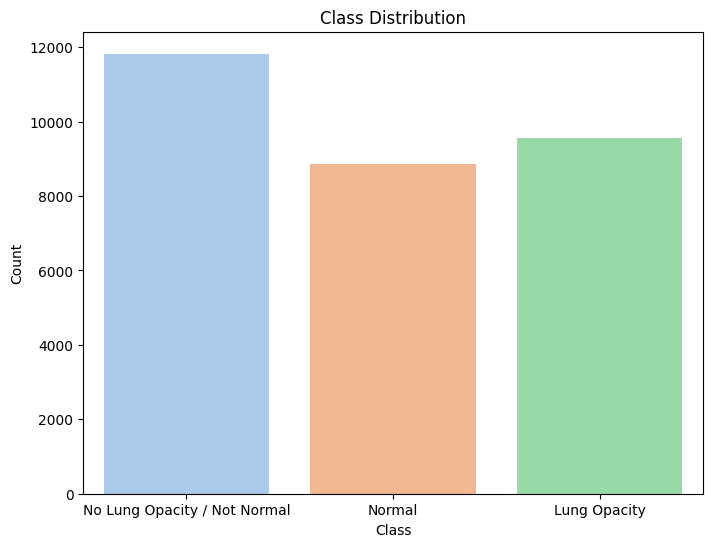

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot class distribution
plt.figure(figsize=(8, 6))
sns.countplot(x="class", data=train_data_merged, palette="pastel")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show();

<b>The dataset is imbalanced with significantly more "Normal" or "Not Normal"  cases compared to "Lung Opacity" cases.</b>

#### <b>Preprocessing of Classes</b>
#### <b>Changing 'No Lung Opacity / Not Normal' cases to 'Normal cases' due to the following reasons:</b>
1. <b>Pneumonia-Specific Detection:</b> The goal is to detect pneumonia, not general lung abnormalities. Since "No Lung Opacity / Not Normal" does not explicitly indicate pneumonia, treating it as non-pneumonia (Normal) might help the model focus only on pneumonia-specific features.

2. <b>Reducing False Positives:</b> If we classify "No Lung Opacity / Not Normal" as Pneumonia, the model might learn to misclassify other lung conditions (e.g., fibrosis, edema, or scarring) as pneumonia. This could lead to false positives, reducing the model's reliability for pneumonia detection.

3. <b>Clinically Interpretable Results:</b> In a real-world clinical setting, radiologists don't categorize non-pneumonia abnormalities as pneumonia.
By treating these cases as normal, we ensure that your model's predictions align with actual pneumonia diagnoses.

In [ ]:
# Renaming the class labels
train_data_merged["class"] = train_data_merged["class"].replace({
    "No Lung Opacity / Not Normal": "Normal"
})

In [ ]:
train_data_merged.head() #first 5 records

,patientId,x,y,width,height,Target,Has_Bounding_Box,class
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,NaN,NaN,0,0,Normal
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,NaN,NaN,0,0,Normal
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,NaN,NaN,0,0,Normal
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,NaN,NaN,0,0,Normal
4,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,1,1,Lung Opacity


In [ ]:
# Displaying updated class distribution
print("Updated Class Distribution:\n", train_data_merged["class"].value_counts())

Updated Class Distribution:
 class
Normal          20672
Lung Opacity     9555
Name: count, dtype: int64


#### <b>Changing Target = 0 for cases of "No Lung Opacity/Not Normal" that are now "Normal"

In [ ]:
train_data_merged.loc[train_data_merged["class"] == "Normal", "Target"] = 0  # Ensuring all are labeled Normal and Target as 0

#### <b> Creating dummy bounding box (nan values) for cases of "No Lung Opacity/Not Normal" that are now "Normal"

In [ ]:
import numpy as np

# Identifying rows where the class is 'Normal'
filter = train_data_merged["class"] == "Normal"

# Assigning NaN to bounding box coordinates for 'Normal' cases
train_data_merged.loc[filter, ["x", "y", "width", "height", "Has_Bounding_Box"]] = [np.nan, np.nan, np.nan, np.nan, 0]

# Ensuring values remain numeric
train_data_merged[["x", "y", "width", "height", "Has_Bounding_Box"]] = train_data_merged[["x", "y", "width", "height", "Has_Bounding_Box"]].apply(pd.to_numeric)

In [ ]:
train_data_merged.head() #first updated 5 records

,patientId,x,y,width,height,Target,Has_Bounding_Box,class
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,NaN,NaN,0,0,Normal
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,NaN,NaN,0,0,Normal
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,NaN,NaN,0,0,Normal
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,NaN,NaN,0,0,Normal
4,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,1,1,Lung Opacity


### <b>Updated Class Distribution Visualization

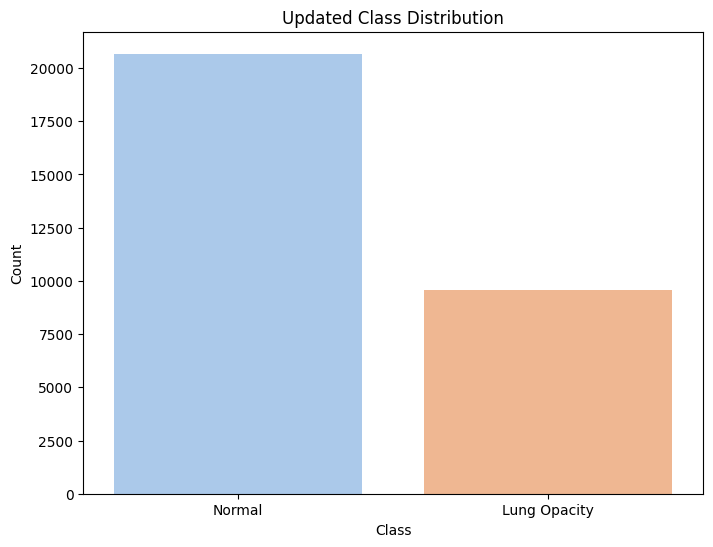

In [ ]:
# Plot class distribution
plt.figure(figsize=(8, 6))
sns.countplot(x="class", data=train_data_merged, palette="pastel")
plt.title("Updated Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show();

### <b>Upsampling the Data

In [ ]:
from sklearn.utils import resample

df_majority = train_data_merged[train_data_merged['class'] == 'Normal']
df_minority = train_data_merged[train_data_merged['class'] == 'Lung Opacity']

# Upsampling "Normal" class
df_minority_upsampled = resample(df_minority,
                                 replace=True,  # Sample with replacement
                                 n_samples=len(df_majority),  # Match the majority class
                                 random_state=42)

# Combining both classes
train_data_resampled = pd.concat([df_majority, df_minority_upsampled])

# Checking new class distribution
print("Resampled Class Distribution:\n", train_data_resampled["class"].value_counts())

Resampled Class Distribution:
 class
Normal          20672
Lung Opacity    20672
Name: count, dtype: int64


In [ ]:
train_data_resampled.sample(5) #sample records

,patientId,x,y,width,height,Target,Has_Bounding_Box,class
8672,4f067b69-3b06-417d-b950-99bd8223b27d,NaN,NaN,NaN,NaN,0,0,Normal
34534,f6cfde90-10de-4584-aed1-2a0ef8238b11,631.0,313.0,187.0,476.0,1,1,Lung Opacity
1828,1565fd6c-9432-454a-87e4-937fd5ad5b60,267.0,537.0,178.0,235.0,1,1,Lung Opacity
30588,da84b82e-e8a7-4dfe-ac3a-4e28cbcc9d8f,NaN,NaN,NaN,NaN,0,0,Normal
9252,52f18c9e-7262-4fcc-a6bc-78e707214886,NaN,NaN,NaN,NaN,0,0,Normal


<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 4 Analysis: Preprocessing and Visualisation of different classes.</b></font></h3>

1. <b>The dataset was highly imbalanced with significantly more "Normal" cases compared to "Lung Opacity" cases.</b>
"Normal" has close to 21,000 instances, while "Lung Opacity" has much fewer cases, around 9,500. <b>Thus, performed Upsampling</b>.
2. <b>Handling the Imbalance Further:</b><br>
  <b>Data Augmentation (For "Lung Opacity" Cases)</b>.
Increasing the number of "Lung Opacity" cases using augmentation techniques like
Flipping, Rotation, Scaling, and Brightness adjustments should be incorporated for generalization.
3. Now, <b>Cases of "Not Normal/No Lung Opacity" and "Normal" are combined. The Target was changed to 0 for these cases and a dummy bounding box of nan values was created.</b>

<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 5: Display images with bounding box</b></font></h3>


In [ ]:
pip install pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 79.0 MB/s eta 0:00:00


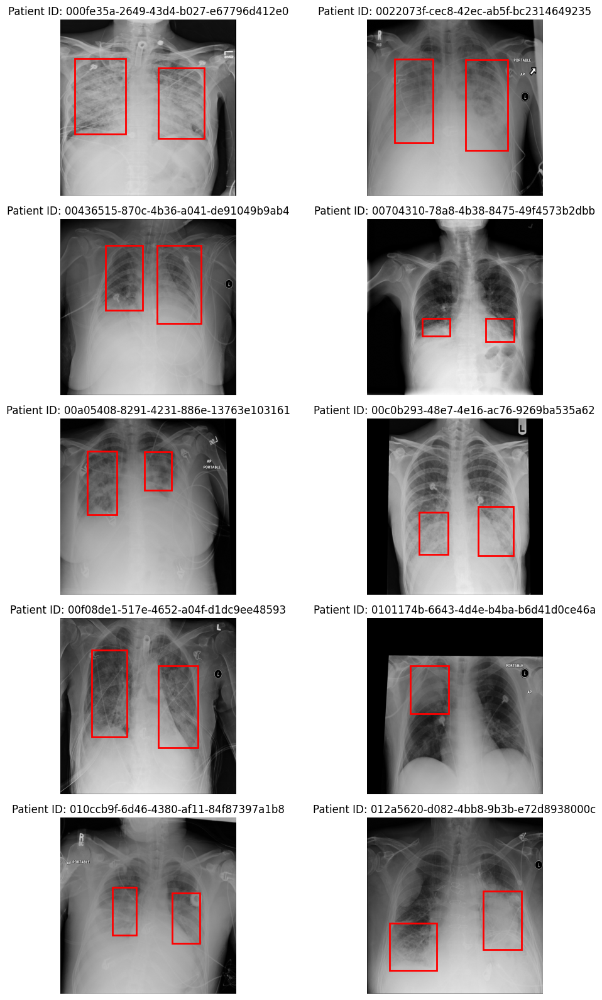

In [ ]:
import os
import pydicom
from matplotlib.patches import Rectangle

df = train_data_merged

# Filtering only Lung Opacity cases (Target == 1)
df_opacity = df[(df["Target"] == 1) & (df["Has_Bounding_Box"] == 1)]

# Grouping by patientId to merge multiple bounding boxes per image
grouped_opacity = df_opacity.groupby("patientId").agg({
    "x": list, "y": list, "width": list, "height": list
}).reset_index()

# Directory where DICOM images are stored
dicom_directory = "/content/drive/MyDrive/AIML/capstoneproject/stage_2_train_images"

# Function to read DICOM and return image
def read_dicom(dicom_path):
    try:
        dicom_data = pydicom.dcmread(dicom_path)
        image = dicom_data.pixel_array

        # Normalizing image
        if np.max(image) > 255:
            image = (image / np.max(image)) * 255
        return image.astype(np.uint8)

    except Exception as e:
        print(f"Skipping {dicom_path} (Error: {e})")
        return None

# Displaying 10 unique patient images
count = 0
fig, axes = plt.subplots(5, 2, figsize=(12, 16))  # 4 rows, 2 columns
axes = axes.flatten()

for idx, row in grouped_opacity.iterrows():
    if count >= 10:
        break  # Stop after displaying 10 images

    dicom_path = os.path.join(dicom_directory, f"{row['patientId']}.dcm")

    if os.path.exists(dicom_path):
        image = read_dicom(dicom_path)

        if image is not None:
            ax = axes[count]
            ax.imshow(image, cmap="gray")

            # Drawing all bounding boxes for this patient
            for x, y, w, h in zip(row["x"], row["y"], row["width"], row["height"]):
                rect = Rectangle((x, y), w, h, linewidth=2, edgecolor='r', facecolor='none')
                ax.add_patch(rect)

            ax.set_title(f"Patient ID: {row['patientId']}")
            ax.axis("off")

            count += 1  # Incrementing valid image count

plt.tight_layout()
plt.show()

<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 6: Design, train and test basic CNN models for classification</b></font></h3>


In [ ]:
import tensorflow as tf
import numpy as np
import random
import os

# Set seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# Ensure deterministic behavior in TensorFlow
tf.config.experimental.enable_op_determinism()

#### <b>Importing necessary packages

In [ ]:
!pip install opencv-python

In [ ]:
!pip install tensorflow

In [ ]:
import cv2 # this is an important module to get imported which may even cause issues while reading the data if not used
import tensorflow as tf
import keras
import re
from tensorflow.keras.models import Sequential #sequential api for sequential model
from tensorflow.keras.layers import Dense, Dropout, Flatten #importing different layers
from tensorflow.keras.layers import Conv2D, MaxPooling2D, BatchNormalization, Activation, Input, LeakyReLU,Activation
from tensorflow.keras import backend
from tensorflow.keras.utils import to_categorical #to perform one-hot encoding
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D
from tensorflow.keras.optimizers import RMSprop,Adam,SGD #optimiers for optimizing the model
from tensorflow.keras.callbacks import EarlyStopping  #regularization method to prevent the overfitting
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras import losses, optimizers

In [ ]:
import pydicom
import os
import numpy as np
import cv2  # OpenCV for resizing
from tqdm import tqdm
import re

# Path to DICOM directory
dicom_dir = '/content/drive/MyDrive/AIML/capstoneproject/stage_2_train_images'
save_path = '/content/drive/MyDrive/AIML/capstoneproject/training_data.npy'  # Save file

training_data = []
new_size = (256, 256)  # Resized image dimensions

# Load and process DICOM images
for filename in tqdm(os.listdir(dicom_dir), desc="Loading Images"):
    if filename.endswith(".dcm"):
        try:
            filepath = os.path.join(dicom_dir, filename)
            ds = pydicom.dcmread(filepath)
            pixel_data = ds.pixel_array

            # Resize image
            resized_img = cv2.resize(pixel_data, new_size, interpolation=cv2.INTER_AREA)

            # Extract patient ID
            match = re.search(r'([0-9a-f\-]+)\.dcm', filename)
            if match:
                patient_id = match.group(1)
            else:
                print(f"Warning: Could not extract patient ID from filename: {filename}")
                continue

            # Append to dataset
            training_data.append((patient_id, resized_img))

        except Exception as e:
            print(f"Error processing file {filename}: {e}")

# Convert list to NumPy array and save
training_data = np.array(training_data, dtype=object)
np.save(save_path, training_data)

print(f"Dataset Saved: {training_data.shape}")
print(f"File saved at: {save_path}")

In [ ]:
import pydicom
import os
import numpy as np
import cv2  # OpenCV for resizing
from tqdm import tqdm
import re

# Path to DICOM directory
dicom_dir = '/content/drive/MyDrive/AIML/capstoneproject/stage_2_test_images'
save_path = '/content/drive/MyDrive/AIML/capstoneproject/test_data.npy'  # Save file

test_data = []
new_size = (256, 256)  # Resized image dimensions

# Load and process DICOM images
for filename in tqdm(os.listdir(dicom_dir), desc="Loading Test Images"):
    if filename.endswith(".dcm"):
        try:
            filepath = os.path.join(dicom_dir, filename)
            ds = pydicom.dcmread(filepath)
            pixel_data = ds.pixel_array

            # Resize image
            resized_img = cv2.resize(pixel_data, new_size, interpolation=cv2.INTER_AREA)

            # Extract patient ID
            match = re.search(r'([0-9a-f\-]+)\.dcm', filename)
            if match:
                patient_id = match.group(1)
            else:
                print(f"Warning: Could not extract patient ID from filename: {filename}")
                continue

            # Append to dataset
            test_data.append((patient_id, resized_img))

        except Exception as e:
            print(f"Error processing file {filename}: {e}")

# Convert list to NumPy array and save
test_data = np.array(test_data, dtype=object)
np.save(save_path, test_data)

print(f"Test Dataset Saved: {test_data.shape}")
print(f"File saved at: {save_path}")

#### <b>NOTE: Training images and testing images were loaded and saved in the training_data.npy and test_data.npy file. This was done to gain easy access to the data while training the model.

#### <b>Loading training data from .npy file

In [ ]:
import numpy as np

# Load the training data from the .npy file
training_data = np.load('/content/drive/MyDrive/AIML/capstoneproject/training_data.npy', allow_pickle=True)


In [ ]:
training_data.shape

(13122, 2)

#### <b>Training data has "13122" records

#### <b>Loading testing data from .npy file

In [ ]:
# Load the testing data from the .npy file
test_data = np.load('/content/drive/MyDrive/AIML/capstoneproject/test_data.npy', allow_pickle=True)

In [ ]:
test_data.shape

(3000, 2)

#### <b>Testing data has "3000" records. We will use our model to predict the labels for these new unknown images.

#### <b>Extracting the data for training and testing respectively.

In [ ]:
training_data_T = training_data.T

In [ ]:
test_data_T = test_data.T

In [ ]:
paitient_id_tr= training_data_T[0]# Extracting the first row (now acting as a column) from transposed training data i.e. patient IDs

In [ ]:
paitient_id_test= test_data_T[0] # Extracting the first row (now acting as a column) from transposed test data i.e. patient IDs

In [ ]:
paitient_xray= training_data_T[1]# Extracting the second row (now acting as a column) from transposed training data i.e. X-ray image data pixels

In [ ]:
paitient_xray_test= test_data_T[1] # Extracting the second row (now acting as a column) from transposed test data i.e. X-ray image data pixels

#### <b>Merging the dataframe of patient data with IDs and image informaiton like bounding box details, class information etc.

In [ ]:
import pandas as pd
# Create a DataFrame from the train data: paitient id and xray pixels - separate dataframe with patient id and category-wise data :merge these two databases with patient id as key

patient_data = pd.DataFrame({'patientId': paitient_id_tr, 'pixel_data': paitient_xray})

# Merge the two DataFrames using 'patientId' as the key
merged_df = pd.merge(patient_data, train_data_resampled, on='patientId', how='inner')

merged_df.head()

,patientId,pixel_data,x,y,width,height,Target,Has_Bounding_Box,class
0,eeadce35-d9c1-417b-aeee-6c4151c08b18,"[[35, 34, 35, 35, 35, 35, 35, 35, 35, 35, 36, ...",NaN,NaN,NaN,NaN,0,0,Normal
1,eda49900-8110-4529-b1ed-abb154c92396,"[[5, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,...",629.0,251.0,236.0,541.0,1,1,Lung Opacity
2,eda49900-8110-4529-b1ed-abb154c92396,"[[5, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,...",629.0,251.0,236.0,541.0,1,1,Lung Opacity
3,eda49900-8110-4529-b1ed-abb154c92396,"[[5, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,...",269.0,276.0,209.0,478.0,1,1,Lung Opacity
4,eda49900-8110-4529-b1ed-abb154c92396,"[[5, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,...",269.0,276.0,209.0,478.0,1,1,Lung Opacity


#### <b>Checking if the data has the two classes of importance, 'Normal' and 'Lung Opacity'. This also clears if there are any lingering NaN values in the final dataset. Next step will be to prepare the data in a way to efficiently create the split.

In [ ]:
merged_df['class'].unique() #unique classes

array(['Normal', 'Lung Opacity'], dtype=object)

In [ ]:
merged_df.shape

(20470, 9)

#### <b>The final dataset has shape of 20470 by 9. There are total 13122 images but here in the final dataset there are 20k entries. This is owing to the multiple bounding boxes in a single image i.e. cases where a Patient ID has multiple bounding boxes.

#### <b>Splitting the dataset in 80:20 ratio for training and validation set.<br>Note: The shape of X dataset is as needed for EfficientNet model too.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

# Assuming 'pixel_data' contains image arrays and 'Target' contains labels
X = np.stack(merged_df['pixel_data'].values)  # Shape: (total_samples, 256, 256)
y = merged_df['Target'].values                # Shape: (total_samples,)

# Ensure images have a channel dimension (for grayscale images)
X = X[..., np.newaxis]  # Shape: (total_samples, 256, 256, 1) Needed for efficientnet

# Split the dataset
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train shape:", X_train.shape, y_train.shape)
print("Val shape:", X_val.shape, y_val.shape)

Train shape: (16376, 256, 256, 1) (16376,)
Val shape: (4094, 256, 256, 1) (4094,)


#### <b>Normalizing the pixel values and converting the datatype to float32 against to float64 so as to reduce the memory requirement to store such a huge data by half. Thereby improving the training time and reducing resource requirement.

In [ ]:
# Normalizing the data
X_train = np.array(X_train, dtype=np.float32) / 255.0
X_val = np.array(X_val, dtype=np.float32) / 255.0

In [ ]:
X_train[0] #Normalized data

array([[[0.01960784],
        [0.01960784],
        [0.01568628],
        ...,
        [0.03529412],
        [0.03921569],
        [0.03921569]],

       [[0.01960784],
        [0.01960784],
        [0.01960784],
        ...,
        [0.02352941],
        [0.02745098],
        [0.02745098]],

       [[0.01960784],
        [0.01960784],
        [0.01960784],
        ...,
        [0.01960784],
        [0.01960784],
        [0.01960784]],

       ...,

       [[0.01176471],
        [0.01176471],
        [0.00784314],
        ...,
        [0.21960784],
        [0.22745098],
        [0.21960784]],

       [[0.01176471],
        [0.01176471],
        [0.00784314],
        ...,
        [0.21960784],
        [0.22745098],
        [0.21960784]],

       [[0.01176471],
        [0.01176471],
        [0.00784314],
        ...,
        [0.18431373],
        [0.19607843],
        [0.19215687]]], dtype=float32)

In [ ]:
print(np.unique(y_train)) #Checking the unique label values

[0 1]


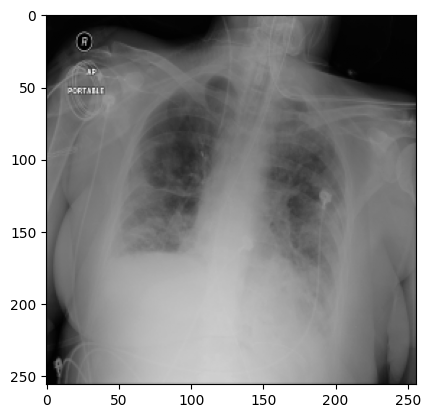

In [ ]:
plt.imshow(X_train[0],cmap='gray') #Displaying the first training record
plt.show()

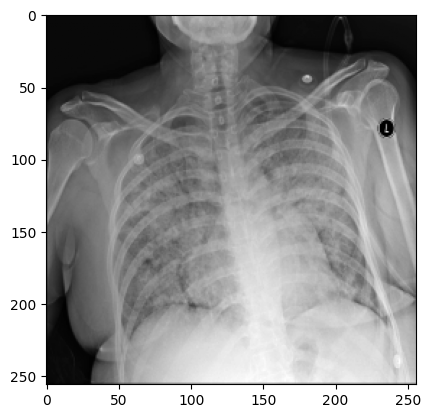

In [ ]:
plt.imshow(X_val[0],cmap='gray') #Displaying the first validation record
plt.show()

#### <b>Designing the Model

In [ ]:
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.metrics import Recall

# Intializing a sequential model
model = Sequential()

# Adding first conv layer with 64 filters and kernel size 3x3 , padding 'same' provides the output size same as the input size

model.add(Conv2D(64, (3, 3), activation='relu', padding="same", input_shape=(256,256,1)))

# Adding max pooling to reduce the size of output of first conv layer
model.add(MaxPooling2D((2, 2), padding = 'same'))

model.add(Conv2D(32, (3, 3), activation='relu', padding="same"))
model.add(MaxPooling2D((2, 2), padding = 'same'))
model.add(Conv2D(32, (3, 3), activation='relu', padding="same"))
model.add(MaxPooling2D((2, 2), padding = 'same'))

# flattening the output of the conv layer after max pooling to make it ready for creating dense connections
model.add(Flatten())

# Adding a fully connected dense layer with 100 neurons
model.add(Dense(100, activation='relu'))

# Adding the output layer with 1 neurons and activation functions as sigmoid since this is a 2-class classification problem and prob. output is enough
model.add(Dense(1, activation='sigmoid'))

# Using SGD Optimizer
opt = SGD(learning_rate=0.01, momentum=0.9)


model.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy', Recall()])

# Generating the summary of the model
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 256, 256, 64)        │             640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 128, 128, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 128, 128, 32)        │          18,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 64, 64, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 32768)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 100)                 │       3,276,900 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │             101 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,353 (12.61 MB)

 Trainable params: 3,305,353 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

#### <b>Training the the Model

In [ ]:
history_cnn = model.fit(X_train, y_train,
                            validation_data=(X_val, y_val),
                            epochs=10,
                            batch_size=32,
                            verbose=1)

Epoch 1/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 16s 21ms/step - accuracy: 0.6489 - loss: 0.6223 - recall_1: 0.7429 - val_accuracy: 0.7362 - val_loss: 0.5470 - val_recall_1: 0.8101
Epoch 2/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.7311 - loss: 0.5480 - recall_1: 0.7638 - val_accuracy: 0.7404 - val_loss: 0.5333 - val_recall_1: 0.8010
Epoch 3/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.7512 - loss: 0.5229 - recall_1: 0.7762 - val_accuracy: 0.7467 - val_loss: 0.5205 - val_recall_1: 0.7717
Epoch 4/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.7663 - loss: 0.4968 - recall_1: 0.7950 - val_accuracy: 0.7653 - val_loss: 0.4975 - val_recall_1: 0.8082
Epoch 5/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.7827 - loss: 0.4654 - recall_1: 0.8081 - val_accuracy: 0.7829 - val_loss: 0.4738 - val_recall_1: 0.8077
Epoch 6/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.8111 - loss: 0.4152 - recall_1: 0.8406 - val_accuracy: 0.7990 - val_loss: 0.4

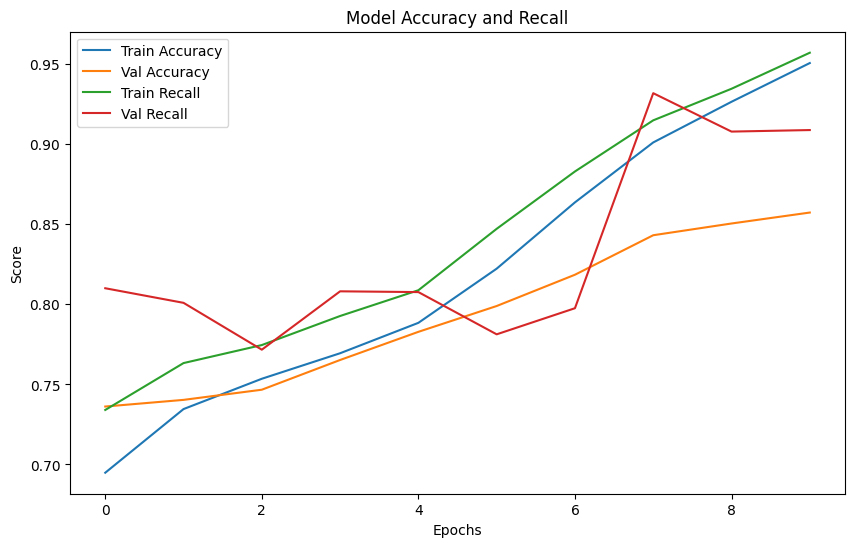

In [ ]:
# Plotting training accuracy and recall
plt.figure(figsize=(10, 6))

# Accuracy
plt.plot(history_cnn.history['accuracy'], label='Train Accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='Val Accuracy')

# Recall
recall_key = [key for key in history_cnn.history.keys() if 'recall' in key][0]
plt.plot(history_cnn.history[recall_key], label='Train Recall')
plt.plot(history_cnn.history[f"val_{recall_key}"], label='Val Recall')

plt.title('Model Accuracy and Recall')
plt.xlabel('Epochs')
plt.ylabel('Score')
plt.legend()
plt.show()

In [ ]:
results = model.evaluate(X_val, y_val)
print("Evaluation Results:", results)

128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8635 - loss: 0.5304 - recall_1: 0.9057
Evaluation Results: [0.5176161527633667, 0.8573521971702576, 0.9088729023933411]


#### <b>Evaluation of validation results has 'Loss', 'Accuracy', and 'Recall'.

<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Observations:</b></font></h3>

1. <b>Increasing Accuracy:</b> Both train and validation accuracy are steadily increasing, indicating that the model is learning well over epochs.
The validation accuracy is slightly lower than the training accuracy, suggesting overfitting.

2. <b>High Recall:</b> Recall is significantly higher than accuracy, especially in early epochs. This is good for pneumonia detection because high recall means fewer false negatives (i.e., fewer missed pneumonia cases).
The validation recall is slightly below training recall but follows a similar trend.

3. <b>Generalization is Fine:</b> The validation accuracy and recall do not drop sharply, meaning the model is generalizing well.
However, the gap between train and val recall widens in later epochs, hinting at slight overfitting.

#### <b>Plotting the Metrics

<b>Training data

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Get model predictions (for binary classification)
y_pred = model.predict(X_train)
y_pred_classes = (y_pred > 0.5).astype("int32")  # Convert probabilities to binary (0 or 1)

# Display the classification report
print(classification_report(y_train, y_pred_classes, target_names=['Normal', 'Pneumonia']))

512/512 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step
              precision    recall  f1-score   support

      Normal       0.95      0.95      0.95      8111
   Pneumonia       0.95      0.95      0.95      8265

    accuracy                           0.95     16376
   macro avg       0.95      0.95      0.95     16376
weighted avg       0.95      0.95      0.95     16376



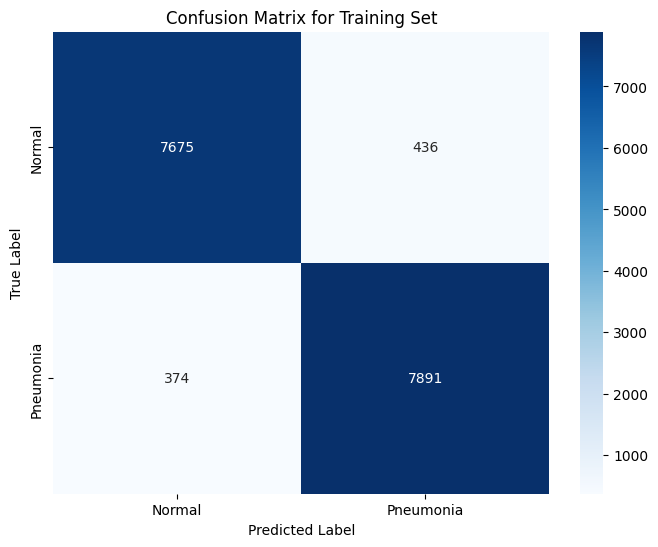

In [ ]:
# Create confusion matrix
cm = confusion_matrix(y_train, y_pred_classes)

# Define class labels
class_names = ['Normal', 'Pneumonia']

# Plot confusion matrix using Seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix for Training Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

<b>Validation data

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Get model predictions (for binary classification)
y_predv = model.predict(X_val)
y_pred_classesv = (y_predv > 0.5).astype("int32")  # Convert probabilities to binary (0 or 1)

# Display the classification report
print(classification_report(y_val, y_pred_classesv, target_names=['Normal', 'Pneumonia']))

128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
              precision    recall  f1-score   support

      Normal       0.89      0.80      0.85      2009
   Pneumonia       0.83      0.91      0.87      2085

    accuracy                           0.86      4094
   macro avg       0.86      0.86      0.86      4094
weighted avg       0.86      0.86      0.86      4094



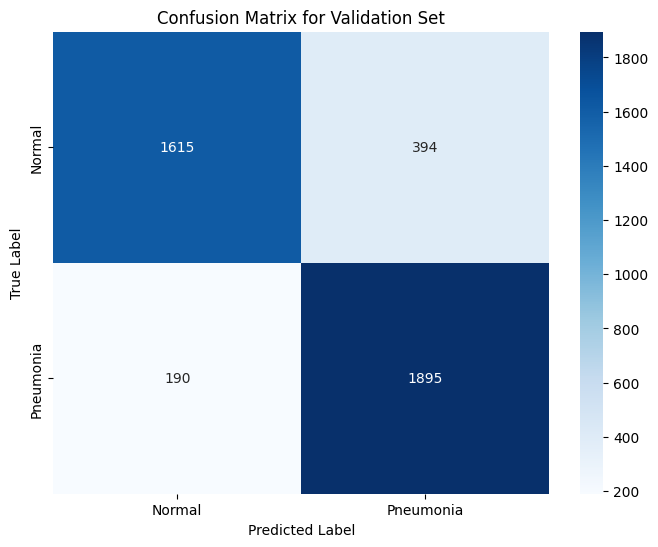

In [ ]:
# Create confusion matrix
cm = confusion_matrix(y_val, y_pred_classesv)

# Define class labels
class_names = ['Normal', 'Pneumonia']

# Plot confusion matrix using Seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix for Validation Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Observations:</b></font></h3>

This is classic case of overfitting. The training is having 0.95 accuracy metric values whereas in the validation data itself we can see that the metrics drop to a minimum of 0.83 for precision in case of Pneumonia class.

1. <b>Training Performance</b><br>
Pneumonia Precision & Recall: 0.95 <br>
Normal Precision & Recall: 0.95<br>
The model is performing great on training data.
2. <b>Validation Performance</b><br>
Accuracy: 0.86<br>
Pneumonia Recall: 0.91
<br>High recall means the model successfully identifies most pneumonia cases, minimizing false negatives (which is crucial in medical diagnosis).
However, recall has dropped compared to training (from 0.95 to 0.91), showing some generalization gap.<br>
Pneumonia Precision: 0.83<br>This means that 17% of predicted pneumonia cases are actually normal, leading to false positives.
In clinical settings, false positives could lead to unnecessary treatments.
3. <b>Accuracy vs. Recall Balance</b><br>
Validation accuracy: 0.86, but recall is more important in medical applications.
The high recall for pneumonia (0.91) suggests that the model is good at detecting pneumonia, but it still needs improvement in precision and specificity. Also, it is overfitting.

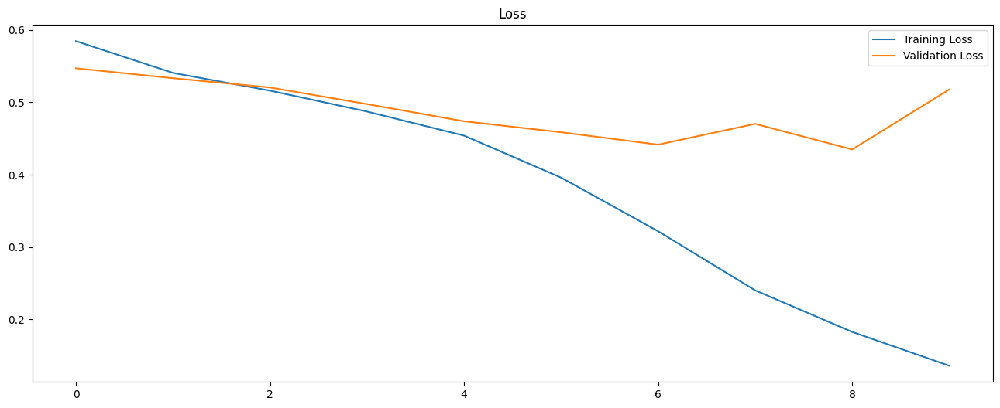

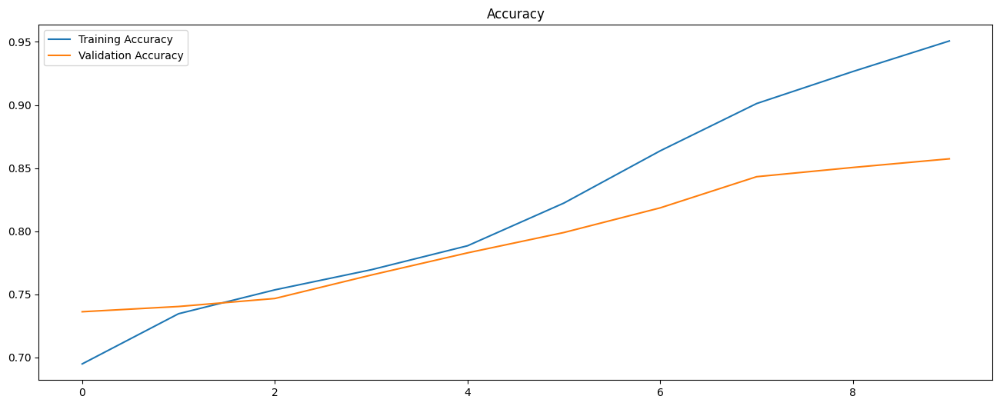

In [ ]:
plt. figure(figsize=(16, 6))
plt.plot(history_cnn.history['loss'], label='Training Loss')
plt. plot(history_cnn.history['val_loss'], label='Validation Loss')
plt.title( 'Loss')
plt. legend ()

plt. figure(figsize=(16, 6))
plt.plot(history_cnn.history['accuracy'], label='Training Accuracy')
plt. plot(history_cnn.history['val_accuracy'], label='Validation Accuracy')
plt.title( 'Accuracy')
plt. legend ()

#### <b> We can see that the model is overfitting. Thus, some other models along with Data Augmentation could be an option to explore for us in the next steps.

### <b>We will be using EfficientNet as an advancement to our Basic CNN model due to the following reasons:</b>

1. <b>Efficient Architecture:</b>EfficientNetB0 is a highly optimized CNN architecture that balances width, depth, and resolution, improving feature extraction for small datasets like medical images.
It captures more detailed pneumonia-related features than a standard CNN, reducing false positives and false negatives.
2. <b>Lower Computational Cost:</b> It requires fewer parameters compared to traditional CNN architectures, reducing memory usage and training time.
3. <b>Improved Feature Extraction:</b> Even without pre-trained weights, EfficientNetB0's architecture allows for better hierarchical feature learning, which is crucial for detecting pneumonia patterns in chest X-rays.
4. <b>Better Generalization:</b> The model is designed to prevent overfitting, making it more robust when applied to unseen test data.

In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam

# Loading EfficientNetB0 model from tf.keras
base_model = EfficientNetB0(
    input_shape=(256, 256, 1),  # Grayscale image shape
    include_top=False,
    weights=None
)

# Building the model
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')  # Binary classification for pneumonia
])

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)          │ (None, 8, 8, 1280)          │       4,048,991 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_2           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 1)                   │           1,281 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,050,272 (15.45 MB)

 Trainable params: 4,008,253 (15.29 MB)

 Non-trainable params: 42,019 (164.14 KB)

#### <b> Idea is to use pretrained efficientnet model. The input shape required for EfficientNet is 256, 256, 1. No pretrained weights are used. Used 'sigmoid' as activation function for final layer, since binary classfication, and a dropout of 50% to prevent overfitting. As far as optimiser is concerned, Adam with learning rate of 0.001 is used. Summary of such a model is present above.

#### <b> Exhaustive data augmentation in terms of rotation, widht shift, height shift, shear, zoom and flip is used to create on the fly augmentation. Meaning no new dataset images are added, instead at each epoch the model goes through not same 16k images, rather augmented versions in each epoch.

In [ ]:
#Data Augmentation
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Create augmented data generators
train_datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

# Flow from arrays
train_generator = train_datagen.flow(X_train, y_train, batch_size=32, shuffle=True)

#### <b> Fitting the model. Validation dataset is used to understand overfitting if present.


In [ ]:
history = model.fit(
    train_generator,  # Augmented images
    epochs=10,
    validation_data=(X_val, y_val),  # Evaluate on test set
    verbose=1, batch_size=32
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 170s 245ms/step - accuracy: 0.6533 - loss: 0.6663 - val_accuracy: 0.5095 - val_loss: 1.0696
Epoch 2/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 120s 235ms/step - accuracy: 0.7386 - loss: 0.5445 - val_accuracy: 0.6566 - val_loss: 0.6845
Epoch 3/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 120s 234ms/step - accuracy: 0.7574 - loss: 0.5143 - val_accuracy: 0.6001 - val_loss: 1.3594
Epoch 4/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 121s 236ms/step - accuracy: 0.7683 - loss: 0.4972 - val_accuracy: 0.7745 - val_loss: 0.4891
Epoch 5/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 120s 235ms/step - accuracy: 0.7762 - loss: 0.4863 - val_accuracy: 0.7460 - val_loss: 0.5743
Epoch 6/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 121s 235ms/step - accuracy: 0.7841 - loss: 0.4745 - val_accuracy: 0.7714 - val_loss: 0.4891
Epoch 7/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 121s 236ms/step - accuracy: 0.7828 - loss: 0.4691 - val_accuracy: 0.7787 - val_loss: 0.4536
Epoch 8/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 121s 236ms/step - accuracy: 0.7920 -

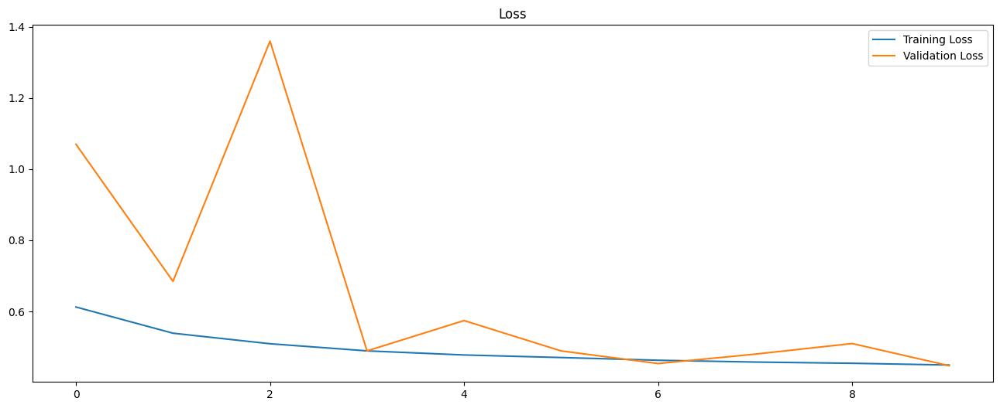

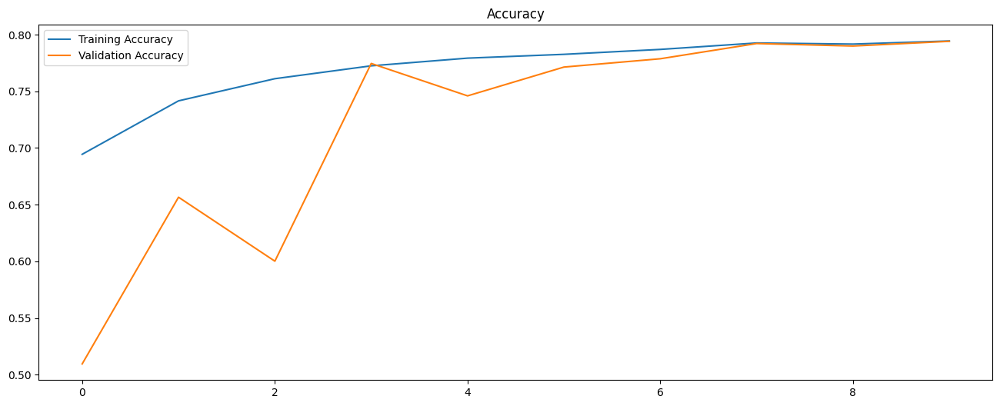

In [ ]:
plt.figure(figsize=(16, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt. plot(history.history['val_loss'], label='Validation Loss')
plt.title( 'Loss')
plt.legend ()

plt.figure(figsize=(16, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt. plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title( 'Accuracy')
plt.legend ()

#### <b> It is clear that we get really good accuracy of 0.79 in training and around same in validation for the final epoch.

#### <b> The model ran relatively quick with only 14 minutes of run time.

#### <b> The above plots of loss and accuracy clearly suggest no sign of overfitting, rather the model performing as required.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Get model predictions (for binary classification)
y_pred = model.predict(X_train)
y_pred_classes = (y_pred > 0.5).astype("int32")  # Convert probabilities to binary (0 or 1)

# Display the classification report
print(classification_report(y_train, y_pred_classes, target_names=['Normal', 'Pneumonia']))

512/512 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step
              precision    recall  f1-score   support

      Normal       0.80      0.81      0.80      8111
   Pneumonia       0.81      0.80      0.80      8265

    accuracy                           0.80     16376
   macro avg       0.80      0.80      0.80     16376
weighted avg       0.80      0.80      0.80     16376



#### <b> Printing the classification report, this suggests that an overall recall of 0.80 for pneumonia is achieved with this model. It can also be seen that the overall accuracy of around 80% is achieved.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Get model predictions (for binary classification)
y_predv = model.predict(X_val)
y_pred_classesv = (y_predv > 0.5).astype("int32")  # Convert probabilities to binary (0 or 1)

# Display the classification report
print(classification_report(y_val, y_pred_classesv, target_names=['Normal', 'Pneumonia']))

128/128 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step
              precision    recall  f1-score   support

      Normal       0.80      0.77      0.79      2009
   Pneumonia       0.79      0.81      0.80      2085

    accuracy                           0.79      4094
   macro avg       0.79      0.79      0.79      4094
weighted avg       0.79      0.79      0.79      4094



####<b> For validationd dataset, the recall achieved for pneumonia is 0.81 which is really good. An overall accuracy of 0.79 is achieved with this model. The model does not overfit which is important.

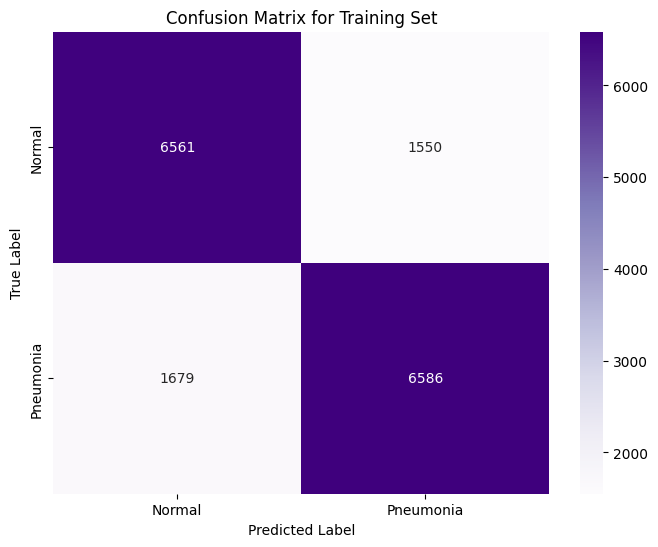

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create confusion matrix
cm = confusion_matrix(y_train, y_pred_classes)

# Define class labels
class_names = ['Normal', 'Pneumonia']

# Plot confusion matrix using Seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix for Training Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

#### The confusion matrix for training data is shown above.

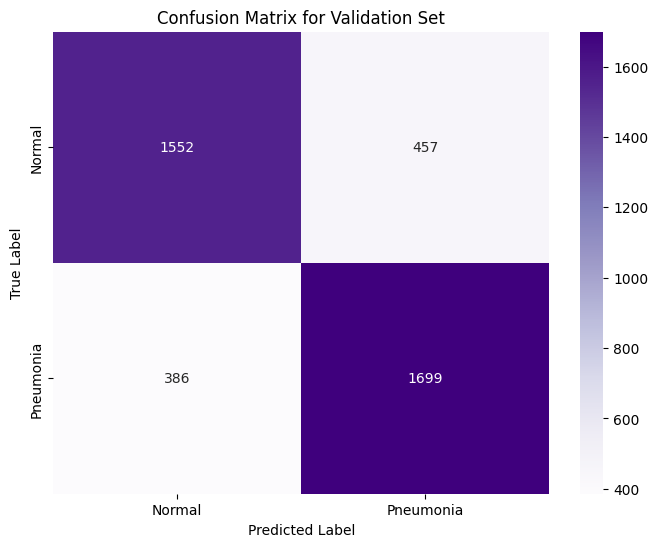

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create confusion matrix
cm = confusion_matrix(y_val, y_pred_classesv)

# Define class labels
class_names = ['Normal', 'Pneumonia']

# Plot confusion matrix using Seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix for Validation Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

#### The confusion matrix for validation set is shown above.

<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Observations:</b></font></h3>

1. The model achieves almost ~80% accuracy on both training and validation sets, indicating no severe overfitting.
2. Precision for pneumonia is ~81%, meaning most pneumonia predictions are correct.
3. Recall for pneumonia is ~81%.
4. Recall improvement is needed to reduce missed pneumonia cases.

Possible improvements: Changes in Data augmentation, class weighting, and fine-tuning deeper EfficientNet versions.

#### <b> Overall the EfficientNet model provides better and generalised results as compared to CNN model. Despite good accuracy in training, the CNN model fails to generalise well and is overfitting.

### <b>Running the EfficientNetB0 on Test images

In [ ]:
# Converting test images list to numpy array
X_test = np.stack(paitient_xray_test)  # Ensuring correct shape (3000, 256, 256)
X_test = X_test[..., np.newaxis]  # Adding channel dimension (3000, 256, 256, 1)

In [ ]:
# Normalizing test images
X_test = np.array(X_test, dtype=np.float32) / 255.0

In [ ]:
#Predicting
y_pred_test = model.predict(X_test)

# Converting probabilities to class labels
y_pred_labels = (y_pred_test > 0.5).astype(int)

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step


In [ ]:
# 'paitient_id_test' contains the patient IDs and 'y_pred_labels' contains the predictions
df_predictions = pd.DataFrame({
    "Patient_ID": paitient_id_test,
    "Predicted_Label": y_pred_labels.flatten()
})

# Displaying the first few rows
df_predictions.head()

,Patient_ID,Predicted_Label
0,25172e23-94bb-4f9d-853e-a4a1d934491b,0
1,25d2e423-40f3-4c47-becd-e05908e3ced4,1
2,265ef9f1-3a21-4c9e-a8fe-740d8fae99f5,0
3,26c07956-e243-4d83-82ea-b8da718b0e53,0
4,26b59bc8-dd04-4093-876f-fb0667d3b43a,1


####<b> The above dataframe shows that the Predictions are done on test cases / new unseen data. Each patient id has a predicted label as either "0" (Normal) or "1"(Pneumonia). Thus, our model is able to predict the presence of Pneumonia.

<h1 style="font-family:'Times New Roman';"><font color='navy'>✅ Milestone 2</font></h1>



<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 1: Fine tune the trained basic CNN models for classification.</b></font></h3>

#### <b> As seen before, the EfficientNet model provided better and generalised results as compared to CNN model. <br>Despite good accuracy in training, the CNN model failed to generalise well and is overfitting. <br>Thus, we will be fine tuning the EfficientNet model in this step.

In [ ]:
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D, BatchNormalization
from tensorflow.keras.regularizers import l2

# Fine-Tuned Model
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),

    # Batch Normalization for stable learning
    BatchNormalization(),

    # First Dense Layer with L2 Regularization & LeakyReLU
    Dense(256, kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    tf.keras.layers.LeakyReLU(alpha=0.1),
    Dropout(0.5),  # Increased dropout

    # Second Dense Layer
    Dense(128, kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    tf.keras.layers.LeakyReLU(alpha=0.1),
    Dropout(0.3),

    # Final Output Layer (Binary Classification)
    Dense(1, activation='sigmoid')
])

/usr/local/lib/python3.11/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


In [ ]:
# Compiling the Model
model.compile(optimizer=Adam(),
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)          │ (None, 8, 8, 1280)          │       4,048,991 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_3           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 1280)                │           5,120 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 256)                 │         327,936 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_2 (LeakyReLU)            │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_3 (LeakyReLU)            │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_5 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,416,608 (16.85 MB)

 Trainable params: 4,371,261 (16.68 MB)

 Non-trainable params: 45,347 (177.14 KB)

In [ ]:
# Adding Callbacks
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

callbacks = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6),
    ModelCheckpoint('efficientnet_pneumonia.h5', monitor='val_loss', save_best_only=True)
]

In [ ]:
# Training the Model
history = model.fit(
    train_generator,
    epochs=15,  # Increasing epochs
    validation_data=(X_val, y_val),
    callbacks=callbacks,
    verbose=1,
    batch_size=32
)

Epoch 1/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.7799 - loss: 0.9248

512/512 ━━━━━━━━━━━━━━━━━━━━ 170s 248ms/step - accuracy: 0.7799 - loss: 0.9245 - val_accuracy: 0.7851 - val_loss: 0.6031 - learning_rate: 0.0010
Epoch 2/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.7892 - loss: 0.5675

512/512 ━━━━━━━━━━━━━━━━━━━━ 122s 239ms/step - accuracy: 0.7892 - loss: 0.5675 - val_accuracy: 0.7863 - val_loss: 0.5462 - learning_rate: 0.0010
Epoch 3/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.7935 - loss: 0.5217

512/512 ━━━━━━━━━━━━━━━━━━━━ 122s 238ms/step - accuracy: 0.7935 - loss: 0.5217 - val_accuracy: 0.7699 - val_loss: 0.5160 - learning_rate: 0.0010
Epoch 4/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.8032 - loss: 0.4790

512/512 ━━━━━━━━━━━━━━━━━━━━ 122s 239ms/step - accuracy: 0.8032 - loss: 0.4790 - val_accuracy: 0.7851 - val_loss: 0.4973 - learning_rate: 0.0010
Epoch 5/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.8020 - loss: 0.4692

512/512 ━━━━━━━━━━━━━━━━━━━━ 122s 239ms/step - accuracy: 0.8019 - loss: 0.4692 - val_accuracy: 0.7956 - val_loss: 0.4557 - learning_rate: 0.0010
Epoch 6/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 121s 236ms/step - accuracy: 0.7986 - loss: 0.4655 - val_accuracy: 0.8019 - val_loss: 0.4632 - learning_rate: 0.0010
Epoch 7/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.8028 - loss: 0.4487

512/512 ━━━━━━━━━━━━━━━━━━━━ 122s 239ms/step - accuracy: 0.8028 - loss: 0.4487 - val_accuracy: 0.8026 - val_loss: 0.4435 - learning_rate: 0.0010
Epoch 8/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 121s 237ms/step - accuracy: 0.8040 - loss: 0.4508 - val_accuracy: 0.7902 - val_loss: 0.4976 - learning_rate: 0.0010
Epoch 9/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 121s 237ms/step - accuracy: 0.7956 - loss: 0.4643 - val_accuracy: 0.8105 - val_loss: 0.4558 - learning_rate: 0.0010
Epoch 10/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.8080 - loss: 0.4403

512/512 ━━━━━━━━━━━━━━━━━━━━ 123s 239ms/step - accuracy: 0.8080 - loss: 0.4403 - val_accuracy: 0.8095 - val_loss: 0.4295 - learning_rate: 5.0000e-04
Epoch 11/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.8067 - loss: 0.4345

512/512 ━━━━━━━━━━━━━━━━━━━━ 122s 238ms/step - accuracy: 0.8067 - loss: 0.4345 - val_accuracy: 0.8124 - val_loss: 0.4286 - learning_rate: 5.0000e-04
Epoch 12/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 121s 237ms/step - accuracy: 0.8117 - loss: 0.4292 - val_accuracy: 0.8053 - val_loss: 0.4366 - learning_rate: 5.0000e-04
Epoch 13/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 122s 237ms/step - accuracy: 0.8149 - loss: 0.4267 - val_accuracy: 0.8124 - val_loss: 0.4347 - learning_rate: 5.0000e-04
Epoch 14/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.8155 - loss: 0.4138

512/512 ━━━━━━━━━━━━━━━━━━━━ 122s 238ms/step - accuracy: 0.8156 - loss: 0.4138 - val_accuracy: 0.8085 - val_loss: 0.4171 - learning_rate: 2.5000e-04
Epoch 15/15
512/512 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.8197 - loss: 0.4085

512/512 ━━━━━━━━━━━━━━━━━━━━ 122s 238ms/step - accuracy: 0.8198 - loss: 0.4085 - val_accuracy: 0.8136 - val_loss: 0.4132 - learning_rate: 2.5000e-04


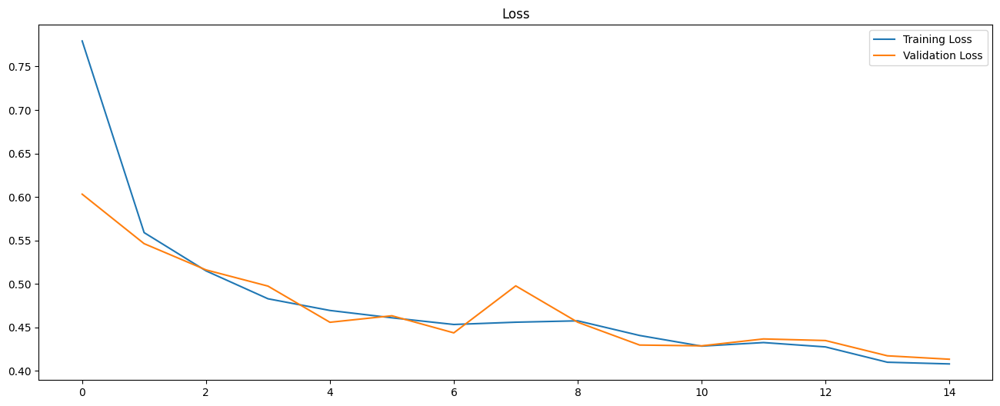

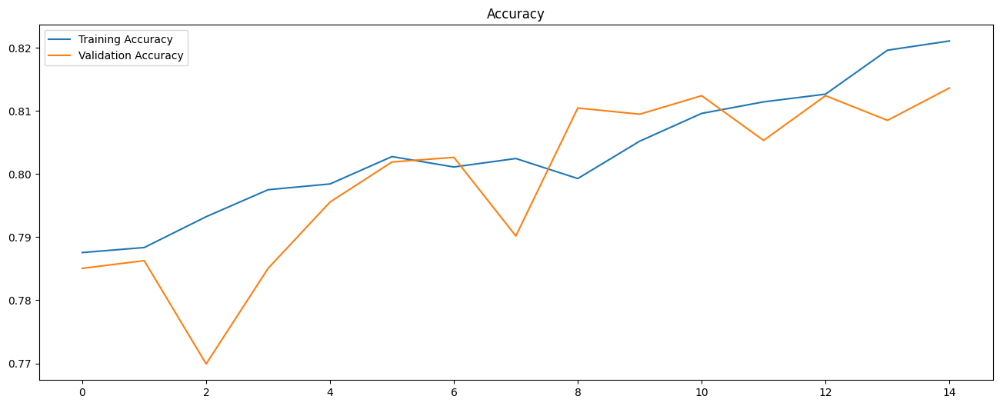

In [ ]:
plt.figure(figsize=(16, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt. plot(history.history['val_loss'], label='Validation Loss')
plt.title( 'Loss')
plt.legend ()

plt.figure(figsize=(16, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt. plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title( 'Accuracy')
plt.legend ()

#### <b> It is clear that the accuracy has increased to 0.83 in training and around same in validation for the final epoch in comparison the the base model.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Get model predictions (for binary classification)
y_pred = model.predict(X_train)
y_pred_classes = (y_pred > 0.5).astype("int32")  # Convert probabilities to binary (0 or 1)

# Display the classification report
print(classification_report(y_train, y_pred_classes, target_names=['Normal', 'Pneumonia']))

512/512 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step
              precision    recall  f1-score   support

      Normal       0.85      0.81      0.83      8111
   Pneumonia       0.82      0.85      0.84      8265

    accuracy                           0.83     16376
   macro avg       0.83      0.83      0.83     16376
weighted avg       0.83      0.83      0.83     16376



In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Get model predictions (for binary classification)
y_predv = model.predict(X_val)
y_pred_classesv = (y_predv > 0.5).astype("int32")  # Convert probabilities to binary (0 or 1)

# Display the classification report
print(classification_report(y_val, y_pred_classesv, target_names=['Normal', 'Pneumonia']))

128/128 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step
              precision    recall  f1-score   support

      Normal       0.83      0.78      0.80      2009
   Pneumonia       0.80      0.85      0.82      2085

    accuracy                           0.81      4094
   macro avg       0.82      0.81      0.81      4094
weighted avg       0.81      0.81      0.81      4094



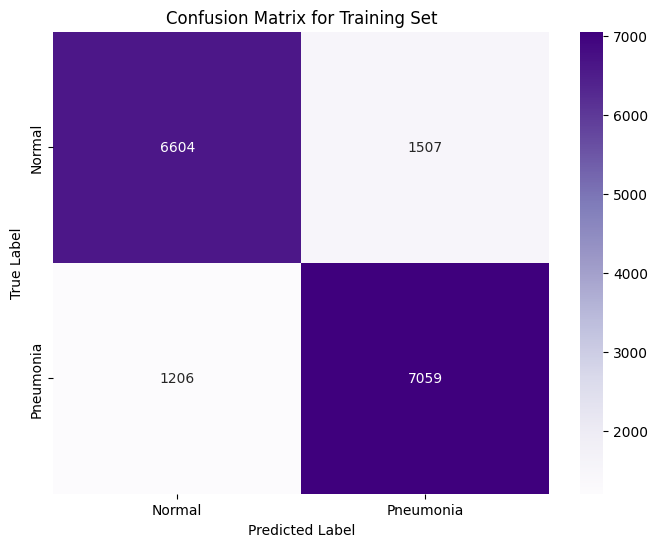

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create confusion matrix
cm = confusion_matrix(y_train, y_pred_classes)

# Define class labels
class_names = ['Normal', 'Pneumonia']

# Plot confusion matrix using Seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix for Training Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

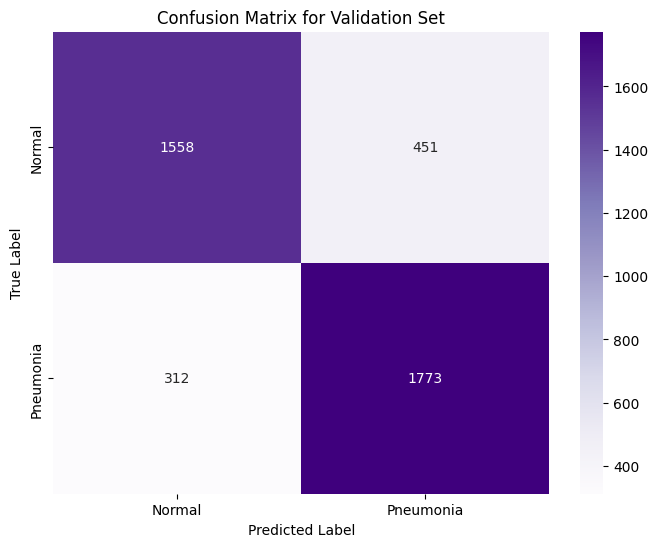

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create confusion matrix
cm = confusion_matrix(y_val, y_pred_classesv)

# Define class labels
class_names = ['Normal', 'Pneumonia']

# Plot confusion matrix using Seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix for Validation Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [ ]:
#Predicting
y_pred_test_tuned = model.predict(X_test)

# Converting probabilities to class labels
y_pred_labels_tuned = (y_pred_test_tuned > 0.5).astype(int)

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step


In [ ]:
# 'paitient_id_test' contains the patient IDs and 'y_pred_labels_tuned' contains the tuned model predictions
df_predictions_tuned = pd.DataFrame({
    "Patient_ID": paitient_id_test,
    "Predicted_Label": y_pred_labels_tuned.flatten()
})

# Displaying the first few rows
df_predictions_tuned.head()

,Patient_ID,Predicted_Label
0,25172e23-94bb-4f9d-853e-a4a1d934491b,0
1,25d2e423-40f3-4c47-becd-e05908e3ced4,1
2,265ef9f1-3a21-4c9e-a8fe-740d8fae99f5,0
3,26c07956-e243-4d83-82ea-b8da718b0e53,0
4,26b59bc8-dd04-4093-876f-fb0667d3b43a,1


<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Observations:</b></font></h3>

<b>1. Model Performance Overview</b><br>


*   Training Accuracy: 83%
*   Validation Accuracy: 81%

Training Loss & Validation Loss: Both are decreasing but with minor fluctuations in validation loss.

F1-Scores:

* Normal Class: 0.80 (Validation)

* Pneumonia Class: 0.82 (Validation)

Overall Model: Balanced performance across both classes.<br>

<b>2. Observations Based on Classification Report</b><br>
Training Set: <br>
* Good Recall for Pneumonia (0.85): The model detects pneumonia cases well.
* Balanced Precision and Recall (~0.83): No major bias toward one class.
* High Accuracy (83%): Indicates the model generalizes well in training.

Validation Set:<br>
*  Slight Drop in Recall for 'Normal' Class (0.78 vs 0.81 in training) - Some normal cases are misclassified as pneumonia.
* Minor Overfitting: Training accuracy is 83%, but validation accuracy is 81%, suggesting a slight overfitting trend.<br>

<b>3. Fine Tuning Results:</b><br>

1. The base model achieved almost ~80% accuracy on both training and validation sets. <br>The Fine Tuned model achieves ~83% accuracy on Training data and ~81% on validation data.
2. The base model had Precision for pneumonia as ~79% and Recall as ~81% for pneumonia class. <br> The Fine Tuned model has achieved ~80% Precision and ~85% Recall for pneumonia class.
3. F1 scores have also improved by 4% for Pneumonia class during training and 2% during testing.

<B>CONCLUSION: Even though the fine tuned model shows very slight overfitting, it gives overall better results and has proven to be the better one across all metrics.

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 2: Apply Transfer Learning model for classification.</b></font></h3>

#### <b>Instead of training a CNN model from scratch, we will use a pre-trained model (Transfer Learning) to classify pneumonia cases.

### <b>We will be using ResNet50 as an advancement to our Basic CNN model using Transfer Learning due to the following reasons:</b>

1. Handles Complex Features – Extracts patterns from chest X-rays efficiently
2. Deep Architecture (50 Layers) – Captures both low-level and high-level features
3. Residual Connections – Prevents vanishing gradient issues in deep networks
4. Pretrained on ImageNet – Can transfer knowledge to medical image classification
5. Works with Grayscale X-rays – Needs conversion to 3-channel (RGB)

Thus, it is a great Great baseline model for Transfer Learning

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import GlobalAveragePooling2D

# Loading ResNet50 Pretrained Model
IMG_SIZE = 224
BATCH_SIZE = 32

# Loading ResNet50 without top layers
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))

# Freezing base model layers
for layer in base_model.layers:
    layer.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x) # Prevents overfitting
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
x = Dense(1, activation='sigmoid')(x)  # 1 output neuron for binary classification

# Creating model
model = Model(inputs=base_model.input, outputs=x)

In [ ]:
# Compiling the Model
model.compile(optimizer=Adam(),
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1             │ (None, 224, 224, 3)    │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_pad (ZeroPadding2D) │ (None, 230, 230, 3)    │              0 │ input_layer_1[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_conv (Conv2D)       │ (None, 112, 112, 64)   │          9,472 │ conv1_pad[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_bn                  │ (None, 112, 112, 64)   │            256 │ conv1_conv[0][0]       │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv1_relu (Activation)   │ (None, 112, 112, 64)   │              0 │ conv1_bn[0][0]         │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ pool1_pad (ZeroPadding2D) │ (None, 114, 114, 64)   │              0 │ conv1_relu[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ pool1_pool (MaxPooling2D) │ (None, 56, 56, 64)     │              0 │ pool1_pad[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_conv       │ (None, 56, 56, 64)     │          4,160 │ pool1_pool[0][0]       │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_bn         │ (None, 56, 56, 64)     │            256 │ conv2_block1_1_conv[0… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_1_relu       │ (None, 56, 56, 64)     │              0 │ conv2_block1_1_bn[0][… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_conv       │ (None, 56, 56, 64)     │         36,928 │ conv2_block1_1_relu[0… │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_bn         │ (None, 56, 56, 64)     │            256 │ conv2_block1_2_conv[0… │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_2_relu       │ (None, 56, 56, 64)     │              0 │ conv2_block1_2_bn[0][… │
│ (Activation)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_0_conv       │ (None, 56, 56, 256)    │         16,640 │ pool1_pool[0][0]       │
│ (Conv2D)                  │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2_block1_3_conv       │ (None, 56, 56, 256)    │         16,640 │ conv2_block1_2_relu[0… │
│ (Conv2D)             

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
tf.keras.backend.clear_session() #to clear TensorFlow memory

In [ ]:
# Function to preprocess data in batches
def preprocess_data_in_batches(data, batch_size, target_size=(224, 224)):
    num_batches = int(np.ceil(len(data) / batch_size))
    processed_data = []

    for i in range(num_batches):
        batch = data[i * batch_size : (i + 1) * batch_size]

        # Converting batch to Tensor
        batch_tensor = tf.convert_to_tensor(batch, dtype=tf.float32)

        # Converting grayscale to RGB (Needed for ResNet50)
        batch_rgb = tf.image.grayscale_to_rgb(batch_tensor)

        # Resizing images to target size (224, 224)
        batch_resized = tf.image.resize(batch_rgb, target_size)

        # Normalizing pixel values (0-1)
        processed_batch = batch_resized / 255.0

        processed_data.extend(processed_batch.numpy())  # Converting back to NumPy

    return np.array(processed_data)

In [ ]:
# Normalizing Data & Converting Grayscale to RGB in batches
X_train_rgb = preprocess_data_in_batches(X_train, BATCH_SIZE)
X_val_rgb = preprocess_data_in_batches(X_val, BATCH_SIZE)

In [ ]:
# Data Augmentation on RGB channel
train_generator_rgb = train_datagen.flow(X_train_rgb, y_train, batch_size=32, shuffle=True)

In [ ]:
# Training the Model
history = model.fit(
    train_generator_rgb,
    validation_data=(X_val_rgb, y_val),
    batch_size=BATCH_SIZE,
    epochs=10,
    verbose=1
)

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 194s 361ms/step - accuracy: 0.5010 - loss: 0.7362 - val_accuracy: 0.4907 - val_loss: 0.6946
Epoch 2/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 175s 343ms/step - accuracy: 0.5081 - loss: 0.6944 - val_accuracy: 0.4907 - val_loss: 0.6933
Epoch 3/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 175s 342ms/step - accuracy: 0.4931 - loss: 0.6939 - val_accuracy: 0.5093 - val_loss: 0.6930
Epoch 4/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 175s 343ms/step - accuracy: 0.5076 - loss: 0.6930 - val_accuracy: 0.5093 - val_loss: 0.6931
Epoch 5/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 175s 342ms/step - accuracy: 0.5006 - loss: 0.6936 - val_accuracy: 0.5093 - val_loss: 0.6931
Epoch 6/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 174s 340ms/step - accuracy: 0.5015 - loss: 0.6934 - val_accuracy: 0.5093 - val_loss: 0.6930
Epoch 7/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 175s 342ms/step - accuracy: 0.5045 - loss: 0.6932 - val_accuracy: 0.5093 - val_loss: 0.6930
Epoch 8/10
512/512 ━━━━━━━━━━━━━━━━━━━━ 175s 342ms/step - accuracy: 0.5019 -

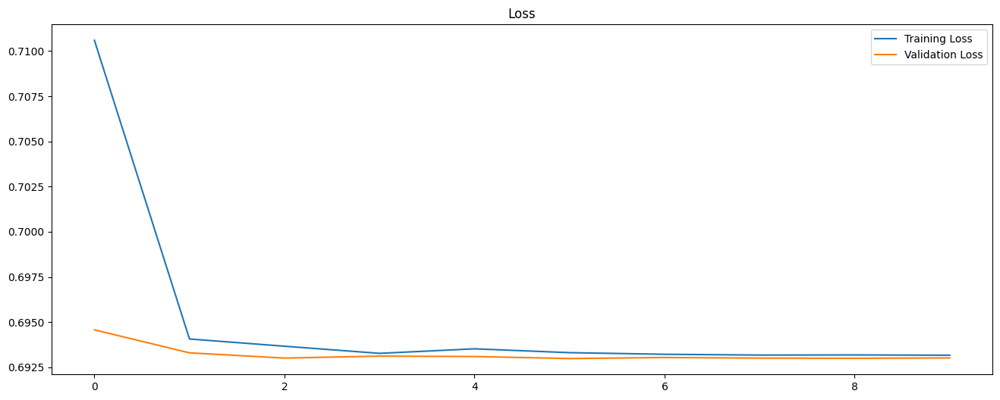

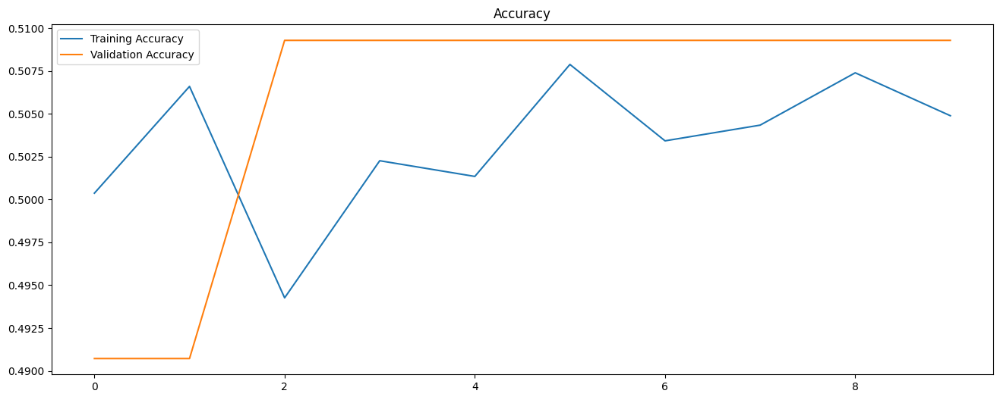

In [ ]:
#Evaluating - Graphs
plt.figure(figsize=(16, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt. plot(history.history['val_loss'], label='Validation Loss')
plt.title( 'Loss')
plt.legend ()

plt.figure(figsize=(16, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt. plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title( 'Accuracy')
plt.legend ()

In [ ]:
#Evaluating - Metrics
from sklearn.metrics import classification_report

# Get model predictions (for binary classification)
y_pred = model.predict(X_train_rgb)
y_pred_classes = (y_pred > 0.5).astype("int32")  # Convert probabilities to binary (0 or 1)

# Display the classification report
print(classification_report(y_train, y_pred_classes, target_names=['Normal', 'Pneumonia'], zero_division=1))

512/512 ━━━━━━━━━━━━━━━━━━━━ 23s 30ms/step
              precision    recall  f1-score   support

      Normal       1.00      0.00      0.00      8111
   Pneumonia       0.50      1.00      0.67      8265

    accuracy                           0.50     16376
   macro avg       0.75      0.50      0.34     16376
weighted avg       0.75      0.50      0.34     16376



In [ ]:
from sklearn.metrics import classification_report

# Get model predictions (for binary classification)
y_predv = model.predict(X_val_rgb)
y_pred_classesv = (y_predv > 0.5).astype("int32")  # Convert probabilities to binary (0 or 1)

# Display the classification report
print(classification_report(y_val, y_pred_classesv, target_names=['Normal', 'Pneumonia'], zero_division=1))

128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step
              precision    recall  f1-score   support

      Normal       1.00      0.00      0.00      2009
   Pneumonia       0.51      1.00      0.67      2085

    accuracy                           0.51      4094
   macro avg       0.75      0.50      0.34      4094
weighted avg       0.75      0.51      0.34      4094



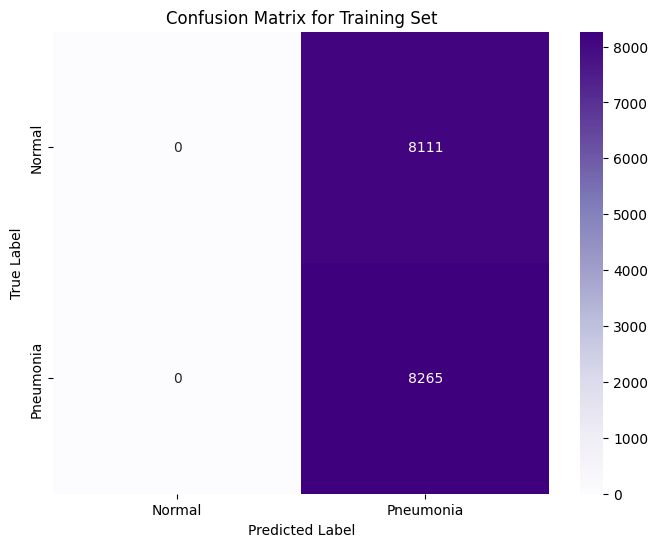

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Create confusion matrix
cm = confusion_matrix(y_train, y_pred_classes)

# Define class labels
class_names = ['Normal', 'Pneumonia']

# Plot confusion matrix using Seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix for Training Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

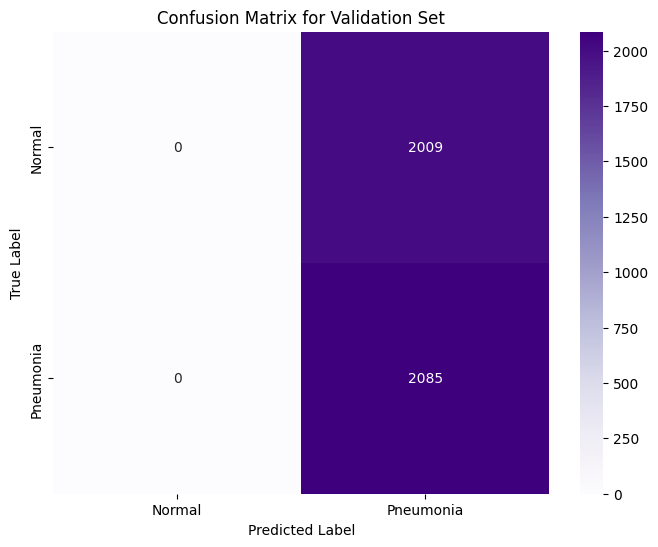

In [ ]:
# Create confusion matrix
cm = confusion_matrix(y_val, y_pred_classesv)

# Define class labels
class_names = ['Normal', 'Pneumonia']

# Plot confusion matrix using Seaborn heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix for Validation Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Observations:</b></font></h3>

<b>1. Training and Validation Loss/Accuracy Trends</b><br>

* The loss curve shows a rapid decrease in training loss initially but stabilizes early.

* Validation loss remains nearly constant, indicating that the model might not be learning effectively beyond a few epochs.

* Training accuracy fluctuates slightly, but validation accuracy remains flat at around 51%, suggesting poor generalization.


<b>2. Classification Report Analysis</b><br>

* Severe Class Imbalance in Predictions: The model predicts all "Pneumonia" cases correctly (100% recall) but completely fails to detect "Normal" cases (0% recall).

* Precision for "Normal" is artificially high (1.00) because the model hardly predicts this class.

* Accuracy of 51% suggests a biased classifier predicting "Pneumonia" for most inputs.

* A similar pattern is observed in training and validation classification reports.

<b>3. Key Issues Identified</b><br>


Overfitting or Mode Collapse: The model is learning only one dominant class ("Pneumonia") and ignoring "Normal" cases.



<b>CONCLUSION:
The ResNet-50 model fails to generalize and suffers from extreme class imbalance. Trying Different Architectures might help. EfficientNet or deeper ResNet variations may perform better with proper hyperparameter tuning. As we have already seen, Fine tuned EfficientNet performed the best.

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 3: Design, train and test RCNN & its hybrids based object detection models to impose the bounding box or mask over the area of interest.</b></font></h3>

In [ ]:
import numpy as np

# Loading training images
X_train = np.load("/content/drive/MyDrive/AIML/capstoneproject/training_data.npy", allow_pickle=True)
print(f"Shape of training images: {X_train.shape}")  # Verify shape

Shape of training images: (13122, 2)


In [ ]:
X_train[0:2]

array([['eeadce35-d9c1-417b-aeee-6c4151c08b18',
        array([[35, 34, 35, ..., 36, 33, 34],
               [34, 34, 34, ..., 31, 32, 33],
               [34, 33, 34, ..., 31, 36, 36],
               ...,
               [45, 35, 34, ..., 56, 69, 85],
               [39, 35, 35, ..., 50, 64, 80],
               [40, 38, 36, ..., 46, 59, 73]], dtype=uint8)],
       ['eda49900-8110-4529-b1ed-abb154c92396',
        array([[ 5,  7,  7, ...,  7,  7,  7],
               [ 5,  8,  8, ...,  8,  8,  8],
               [ 5,  8,  8, ...,  8,  8,  8],
               ...,
               [41, 66, 62, ..., 28, 68, 78],
               [42, 67, 64, ..., 38, 61, 77],
               [28, 45, 44, ..., 22, 37, 48]], dtype=uint8)]],
      dtype=object)

In [ ]:
X_train.shape

(13122, 2)

In [ ]:
import torch
import pandas as pd

# Loading annotations
df = pd.read_csv("/content/drive/MyDrive/AIML/capstoneproject/stage_2_train_labels.csv")

# Normalizing bounding boxes
df["x_max"] = df["x"] + df["width"]
df["y_max"] = df["y"] + df["height"]

# Create dictionary to store annotations
all_annotations = {}

for pid, img in X_train:  # Loop over all images
    # Fetch bounding boxes for the patient ID
    patient_boxes = df[df["patientId"] == pid][["x", "y", "x_max", "y_max"]].dropna().values

    if len(patient_boxes) > 0:  # If bounding boxes exist (Pneumonia case)
        bboxes = torch.tensor(patient_boxes, dtype=torch.float32)
        labels = torch.ones((bboxes.shape[0],), dtype=torch.int64)
    else:  # If no bounding box, assign [0, 0, 0, 0] (Normal case)
        bboxes = torch.tensor([[0, 0, 0, 0]], dtype=torch.float32)
        labels = torch.zeros((1,), dtype=torch.int64)  # Label 0 for 'Normal'

    # Store annotations in dictionary
    all_annotations[pid] = {"boxes": bboxes, "labels": labels}

# Debug: Printing example output
example_pid = list(all_annotations.keys())[0]  # Get first patient ID
print(f"Example Patient ID: {example_pid}")
print("Example Annotation:", all_annotations[example_pid])

Example Patient ID: eeadce35-d9c1-417b-aeee-6c4151c08b18
Example Annotation: {'boxes': tensor([[0., 0., 0., 0.]]), 'labels': tensor([0])}


#### <b> In the above code, the .csv file which has training annotations along with labels are read. <br>First step is to normalize the bounding box for easier computation of IOU and use in Faster RCNN models.<br> Next is creating dictionary where patient Id is 'keys' and relevant information is values. This will be used to map annotations, labels to actual images. <br>The code then diverges into 2 section, one with pneunomia cases and other with normal cases. For normal cases, a dummy bounding box of [0 0 0 0] is used, which will be manipulated further to be used by Faster RCNN model.

In [ ]:
X_train[0]

array(['eeadce35-d9c1-417b-aeee-6c4151c08b18',
       array([[35, 34, 35, ..., 36, 33, 34],
              [34, 34, 34, ..., 31, 32, 33],
              [34, 33, 34, ..., 31, 36, 36],
              ...,
              [45, 35, 34, ..., 56, 69, 85],
              [39, 35, 35, ..., 50, 64, 80],
              [40, 38, 36, ..., 46, 59, 73]], dtype=uint8)], dtype=object)

In [ ]:
impatient_ids = [entry[0] for entry in X_train]
print(impatient_ids)

['eeadce35-d9c1-417b-aeee-6c4151c08b18', 'eda49900-8110-4529-b1ed-abb154c92396', 'ed9d15d1-e0e0-4e90-ba5b-6d51b4861e04', 'ee85c2b0-35da-4177-8047-d15ae8bafe5e', 'ed8b97b1-98f6-4ccb-b665-5b7027b302b3', 'edfb87ef-944e-42df-a5f1-49b415d1741a', 'edddaa15-b11b-4123-a8fa-69dad5611450', 'eee35b66-1cde-4324-acfb-757b330a7b5b', 'ee227329-3b37-45c7-85fb-67136ec17511', 'edff33a8-b569-43a1-83a0-9d2a0bd97cdf', 'ee5ee553-5acf-4dcb-931a-5988fbb9a351', 'ef56756e-aaa2-4fcd-a153-dcecd1444a64', 'efca1796-561c-4131-9a5d-19efe15f7e85', 'f02ce786-bbba-4c93-a9ac-8e78716bf6da', 'eee71ceb-52d2-4d63-acaf-5eab6f8d8932', 'ef7badd9-6de6-436c-ac89-d77e4cced196', 'ef99cacf-fdaf-48c9-bc54-a7c36590f27e', 'eef92899-5dc5-4f31-8807-2391f0f88588', 'efd12382-2f22-4c1a-8a74-93c099b9c2f4', 'eee6e28d-766b-448d-8690-fa9c265fc6fd', 'eef8150d-d400-4712-9496-7b9f2da9518b', 'f008d8ba-adfc-4f35-aef6-fa0a94697ca1', 'ef8cb906-acdc-44ac-bb8d-05f17b86c3b3', 'ef40aa15-7730-42c0-a1fc-be52cb8c30ea', 'eff33651-3ef2-4acf-bbd9-c5d785640fc6',

#### <b> Confirming that the keys in the created dictionary has patient Ids. Here first patient Id is checked.

In [ ]:
patient_ids = list(all_annotations.keys())

# Display the list of patientIds
print(patient_ids)

['eeadce35-d9c1-417b-aeee-6c4151c08b18', 'eda49900-8110-4529-b1ed-abb154c92396', 'ed9d15d1-e0e0-4e90-ba5b-6d51b4861e04', 'ee85c2b0-35da-4177-8047-d15ae8bafe5e', 'ed8b97b1-98f6-4ccb-b665-5b7027b302b3', 'edfb87ef-944e-42df-a5f1-49b415d1741a', 'edddaa15-b11b-4123-a8fa-69dad5611450', 'eee35b66-1cde-4324-acfb-757b330a7b5b', 'ee227329-3b37-45c7-85fb-67136ec17511', 'edff33a8-b569-43a1-83a0-9d2a0bd97cdf', 'ee5ee553-5acf-4dcb-931a-5988fbb9a351', 'ef56756e-aaa2-4fcd-a153-dcecd1444a64', 'efca1796-561c-4131-9a5d-19efe15f7e85', 'f02ce786-bbba-4c93-a9ac-8e78716bf6da', 'eee71ceb-52d2-4d63-acaf-5eab6f8d8932', 'ef7badd9-6de6-436c-ac89-d77e4cced196', 'ef99cacf-fdaf-48c9-bc54-a7c36590f27e', 'eef92899-5dc5-4f31-8807-2391f0f88588', 'efd12382-2f22-4c1a-8a74-93c099b9c2f4', 'eee6e28d-766b-448d-8690-fa9c265fc6fd', 'eef8150d-d400-4712-9496-7b9f2da9518b', 'f008d8ba-adfc-4f35-aef6-fa0a94697ca1', 'ef8cb906-acdc-44ac-bb8d-05f17b86c3b3', 'ef40aa15-7730-42c0-a1fc-be52cb8c30ea', 'eff33651-3ef2-4acf-bbd9-c5d785640fc6',

In [ ]:
# Compare if patientIds in annotations and images are the same
if sorted(patient_ids) == sorted(impatient_ids):
    print("All patientIds match between annotations and images.")
else:
    print("There is a mismatch between patientIds in annotations and images.")

All patientIds match between annotations and images.


#### <b>Checking if all patientIds match between annotations and images.

In [ ]:
missing_in_images = set(patient_ids) - set(impatient_ids)
missing_in_annotations = set(impatient_ids) - set(patient_ids)

if missing_in_images:
    print(f"Patient IDs missing in images: {missing_in_images}")
else:
    print("No patient IDs are missing in images.")

if missing_in_annotations:
    print(f"Patient IDs missing in annotations: {missing_in_annotations}")
else:
    print("No patient IDs are missing in annotations.")

No patient IDs are missing in images.
No patient IDs are missing in annotations.


In [ ]:
isize = len(impatient_ids)
print(isize)

asize = len(patient_ids)
print(asize)

13122
13122


#### <b> Total 13122 images and their corresponding annotations.

In [ ]:
all_annotations[list(all_annotations.keys())[120]]

{'boxes': tensor([[667., 398., 841., 713.]]), 'labels': tensor([1])}

In [ ]:
from sklearn.model_selection import train_test_split

# Split patient IDs into train and validation sets
train_ids, val_ids = train_test_split(patient_ids[:500], test_size=0.25, random_state=42)

# Split annotations
annotations_train_split = {pid: all_annotations[pid] for pid in train_ids}
annotations_val_split = {pid: all_annotations[pid] for pid in val_ids}

# Split image file names based on patient IDs
train_images = [img for img in X_train if img[0] in train_ids]  # Assuming X_train contains (patient_id, image)
val_images = [img for img in X_train if img[0] in val_ids]

print(f"Training images: {len(train_images)}, Validation images: {len(val_images)}")
print(f"Training annotations: {len(annotations_train_split)}, Validation annotations: {len(annotations_val_split)}")

Training images: 375, Validation images: 125
Training annotations: 375, Validation annotations: 125


#### <b>In order to not run the training on entire dataset due to computation constraints, a subset of dataset can be used for training. To do so, instead of parsing entirely the "patient_ids", we can parse "patient_ids[:500]" for considering only 500 data points as the sample. This will help us to experiment on the model.

#### <b> Splitting the data into train and validation split, for both images and annotations on patient Id.

In [ ]:
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torch.utils.data import Dataset, DataLoader

In [ ]:
!pip install pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 24.6 MB/s eta 0:00:00


In [ ]:
import pydicom
import torchvision.transforms.functional as F
import cv2
import os

class PneumoniaDataset(Dataset):
    def __init__(self, images, annotations, transform=None, image_dir=None):
        # Ensure image IDs are extracted as strings and filter out None values.
        self.images = [str(img[0]) for img in images if img[0] is not None]
        self.annotations = annotations  # Dictionary mapping patient IDs to annotations
        self.transform = transform
        self.image_dir = image_dir  # Directory where images are stored

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        # Check that image_dir is provided
        if self.image_dir is None:
            raise ValueError("image_dir is None. Please provide a valid image directory path.")

        # Get the image ID (should be a valid string)
        image_id = self.images[idx]
        image_path = None
        extensions = [".png", ".jpg", ".jpeg", ".dcm"]
        for ext in extensions:
            potential_path = os.path.join(self.image_dir, image_id + ext)
            if os.path.exists(potential_path):
                image_path = potential_path
                break
        if image_path is None:
            raise ValueError(f"Error loading image: {image_id} (no file with expected extensions found)")

        # Load the image. Use pydicom for DICOM files, otherwise use OpenCV.
        if image_path.endswith(".dcm"):
            dicom_image = pydicom.dcmread(image_path)
            image = dicom_image.pixel_array
            image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
        else:
            image = cv2.imread(image_path)
            if image is None:
                raise ValueError(f"Error loading image: {image_path}")
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        image = F.to_tensor(image)

        # Look up the annotation using the image ID.
        annotation = self.annotations.get(
            image_id,
            {"boxes": torch.empty((0, 4), dtype=torch.float32),
             "labels": torch.empty((0,), dtype=torch.int64)}
        )

        # Validate bounding boxes: if invalid (zero area), treat as no object.
        if annotation["boxes"].numel() > 0:
            boxes = annotation["boxes"]
            valid = (boxes[:, 2] > boxes[:, 0]) & (boxes[:, 3] > boxes[:, 1])
            if not valid.all():
                annotation["boxes"] = torch.empty((0, 4), dtype=torch.float32)
                annotation["labels"] = torch.empty((0,), dtype=torch.int64)
        else:
            annotation["boxes"] = torch.empty((0, 4), dtype=torch.float32)
            annotation["labels"] = torch.empty((0,), dtype=torch.int64)

        if self.transform:
            image = self.transform(image)

        return image, annotation

#### <b>This is the dataset loader class which will be used to load the images, extract the bounding boxes and ensure that 'normal' cases are dealt with properly.

#### <b>Faster R-CNN (Region-based Convolutional Neural Network) is a two-stage object detection model that improves upon R-CNN and Fast R-CNN by introducing a Region Proposal Network (RPN) to generate region proposals efficiently. It is widely used in object detection tasks, including medical imaging.



In [ ]:
train_dataset = PneumoniaDataset(images = train_images, annotations = annotations_train_split, image_dir="/content/drive/MyDrive/AIML/capstoneproject/stage_2_train_images")
val_dataset = PneumoniaDataset(val_images,  annotations_val_split, image_dir="/content/drive/MyDrive/AIML/capstoneproject/stage_2_train_images")

# Create DataLoaders
train_loader = DataLoader(train_dataset, pin_memory=True, num_workers=4, batch_size=16, shuffle=True, collate_fn=lambda x: tuple(zip(*x)))
val_loader = DataLoader(val_dataset, pin_memory=True, num_workers=4, batch_size=16, shuffle=False, collate_fn=lambda x: tuple(zip(*x)))

#### <b> This is train and validation dataset loaders. Based on the compute power available, the batch size has been selected as 16, with 4 cores working parallely for data transfers.

#### <b>MODEL LOADING : ResNet50

<b>1. Faster R-CNN ResNet50 FPN: Uses a ResNet-50 backbone with a Feature Pyramid Network (FPN) for strong feature extraction

In [ ]:
# Loading pre-trained Faster R-CNN
model = fasterrcnn_resnet50_fpn(pretrained=True)

# Modify the classification head for pneumonia detection
num_classes = 2  # Background (0) + Pneumonia (1)
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(in_features, num_classes)

# Move to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

#### <b> This is where model is instantiated. The model is a region proposal network (RPN) with ResNet50 as backbone (feature extractor). This model inherently is tuned on COCO dataset for 91 classes, however in our case there are only 2 cases, pneumonia present and absent (background). Hence the classification head was tweaked accordingly.

Epoch [1/10] - Total Loss: 0.1212 | Cls Loss: 0.0775 | Box Reg Loss: 0.0239 | Obj Loss: 0.0184 | RPN Box Reg Loss: 0.0015
Epoch [2/10] - Total Loss: 0.0786 | Cls Loss: 0.0387 | Box Reg Loss: 0.0329 | Obj Loss: 0.0061 | RPN Box Reg Loss: 0.0009
Epoch [3/10] - Total Loss: 0.0772 | Cls Loss: 0.0374 | Box Reg Loss: 0.0350 | Obj Loss: 0.0040 | RPN Box Reg Loss: 0.0009
Epoch [4/10] - Total Loss: 0.0660 | Cls Loss: 0.0317 | Box Reg Loss: 0.0303 | Obj Loss: 0.0032 | RPN Box Reg Loss: 0.0008
Epoch [5/10] - Total Loss: 0.0680 | Cls Loss: 0.0303 | Box Reg Loss: 0.0346 | Obj Loss: 0.0023 | RPN Box Reg Loss: 0.0008
Epoch [6/10] - Total Loss: 0.0495 | Cls Loss: 0.0212 | Box Reg Loss: 0.0266 | Obj Loss: 0.0010 | RPN Box Reg Loss: 0.0008
Epoch [7/10] - Total Loss: 0.0451 | Cls Loss: 0.0187 | Box Reg Loss: 0.0249 | Obj Loss: 0.0009 | RPN Box Reg Loss: 0.0006
Epoch [8/10] - Total Loss: 0.0433 | Cls Loss: 0.0186 | Box Reg Loss: 0.0229 | Obj Loss: 0.0012 | RPN Box Reg Loss: 0.0006
Epoch [9/10] - Total Los

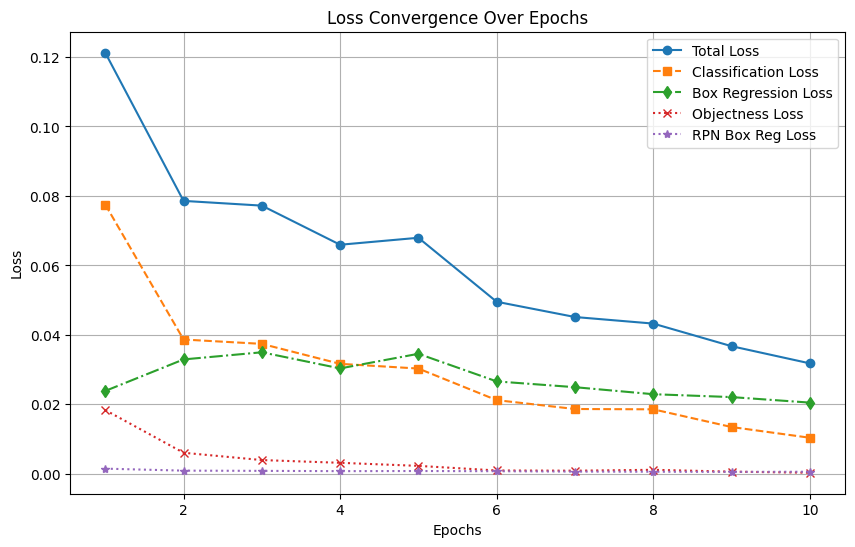

In [ ]:
# Define optimizer & learning rate scheduler
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(params, lr=0.0001)

# Lists to store loss values for visualization
total_losses = []
cls_losses = []
box_reg_losses = []
obj_losses = []
rpn_box_reg_losses = []

# Training Loop
num_epochs = 10  # Set number of epochs

for epoch in range(num_epochs):
    model.train()  # Set model to training mode
    total_loss = 0  # Initialize total loss for this epoch
    total_cls_loss = 0
    total_box_reg_loss = 0
    total_obj_loss = 0
    total_rpn_box_reg_loss = 0

    num_batches = len(train_loader)  # Track number of batches

    for images, targets in train_loader:
        # Move images and targets to the device (GPU/CPU)
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        optimizer.zero_grad()  # Zero the gradients before backpropagation

        # Forward pass through the model; it returns a dictionary of losses
        loss_dict = model(images, targets)

        # Extract individual losses
        loss_classifier = loss_dict.get("loss_classifier", torch.tensor(0.0))
        loss_box_reg = loss_dict.get("loss_box_reg", torch.tensor(0.0))
        loss_objectness = loss_dict.get("loss_objectness", torch.tensor(0.0))
        loss_rpn_box_reg = loss_dict.get("loss_rpn_box_reg", torch.tensor(0.0))

        # Sum all losses
        loss = loss_classifier + loss_box_reg + loss_objectness + loss_rpn_box_reg

        loss.backward()  # Backpropagate to compute gradients
        optimizer.step()  # Update the model's weights

        # Accumulate the losses for reporting
        total_loss += loss.item()
        total_cls_loss += loss_classifier.item()
        total_box_reg_loss += loss_box_reg.item()
        total_obj_loss += loss_objectness.item()
        total_rpn_box_reg_loss += loss_rpn_box_reg.item()

    # Store average losses for this epoch
    avg_total_loss = total_loss / num_batches
    avg_cls_loss = total_cls_loss / num_batches
    avg_box_reg_loss = total_box_reg_loss / num_batches
    avg_obj_loss = total_obj_loss / num_batches
    avg_rpn_box_reg_loss = total_rpn_box_reg_loss / num_batches

    total_losses.append(avg_total_loss)
    cls_losses.append(avg_cls_loss)
    box_reg_losses.append(avg_box_reg_loss)
    obj_losses.append(avg_obj_loss)
    rpn_box_reg_losses.append(avg_rpn_box_reg_loss)

    # Print the average losses for the epoch
    print(f"Epoch [{epoch+1}/{num_epochs}] - Total Loss: {avg_total_loss:.4f} | "
          f"Cls Loss: {avg_cls_loss:.4f} | "
          f"Box Reg Loss: {avg_box_reg_loss:.4f} | "
          f"Obj Loss: {avg_obj_loss:.4f} | "
          f"RPN Box Reg Loss: {avg_rpn_box_reg_loss:.4f}")

print("Training complete!")
import matplotlib.pyplot as plt
# ✅ Plot Loss Curves
plt.figure(figsize=(10, 6))
plt.plot(range(1, num_epochs+1), total_losses, label="Total Loss", marker="o", linestyle="-")
plt.plot(range(1, num_epochs+1), cls_losses, label="Classification Loss", marker="s", linestyle="--")
plt.plot(range(1, num_epochs+1), box_reg_losses, label="Box Regression Loss", marker="d", linestyle="-.")
plt.plot(range(1, num_epochs+1), obj_losses, label="Objectness Loss", marker="x", linestyle=":")
plt.plot(range(1, num_epochs+1), rpn_box_reg_losses, label="RPN Box Reg Loss", marker="*", linestyle=":")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Convergence Over Epochs")
plt.legend()
plt.grid(True)
plt.show()

#### <b> The above code trains the model for given number of epochs. Since this is object detection model, the losses are of various forms. Like classification loss (cross entropy loss), bounding box regression loss, objectness loss (Binary cross entropy), and total loss which is addition of all losses. It can be seen that with epochs the value decreases gradually.

In [ ]:
model.eval()  # Set model to evaluation mode
all_predictions = []  # To store predictions for all images

with torch.no_grad():
    for images, targets in val_loader:
        images = [img.to(device) for img in images]
        preds = model(images)  # In eval mode, model returns predictions per image
        all_predictions.extend(preds)

print(f"Obtained predictions for {len(all_predictions)} images.")

Obtained predictions for 125 images.


#### <b> Prediction done for validation dataset, which is generated using val_loader.

### Normal Cases (Label 0) ###


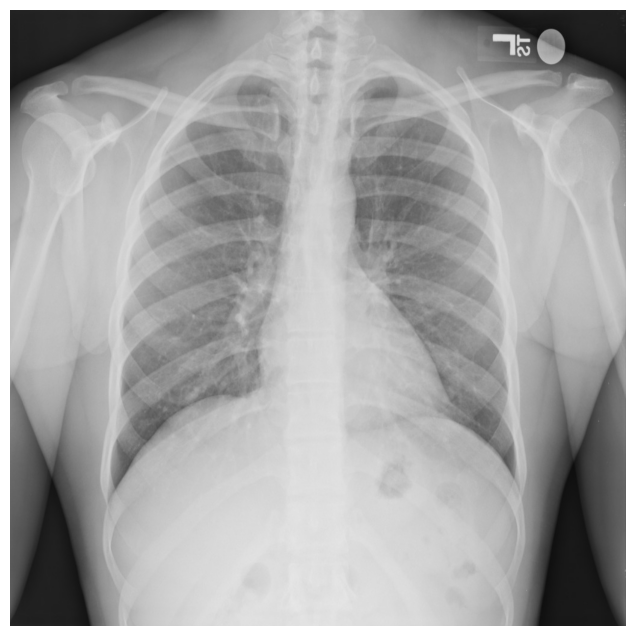

Total Predictions: 2
Scores: tensor([0.8658, 0.0984], device='cuda:0')


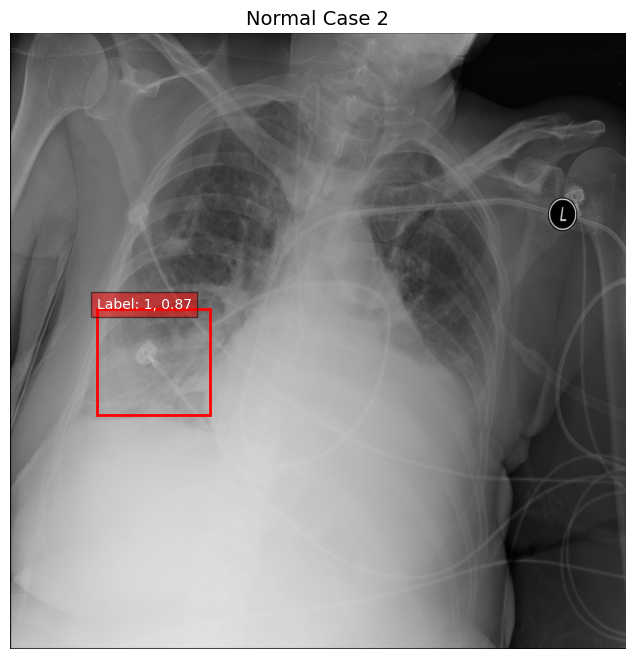

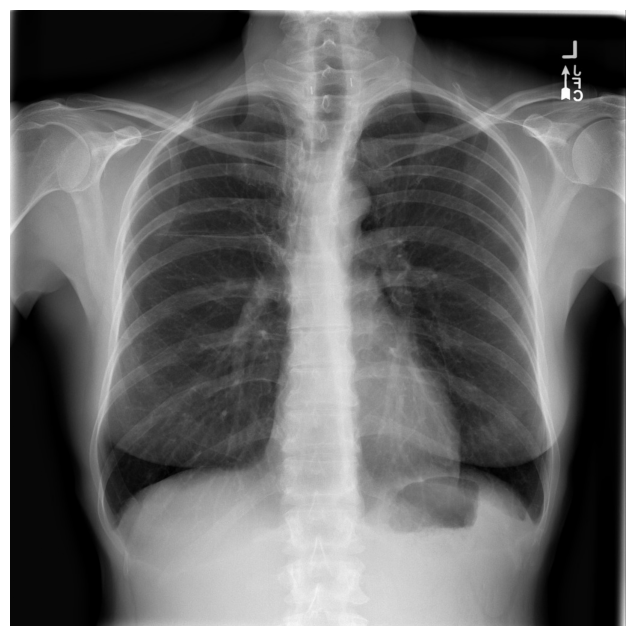

Total Predictions: 1
Scores: tensor([0.2260], device='cuda:0')
No bounding boxes meet the confidence threshold (0.5).


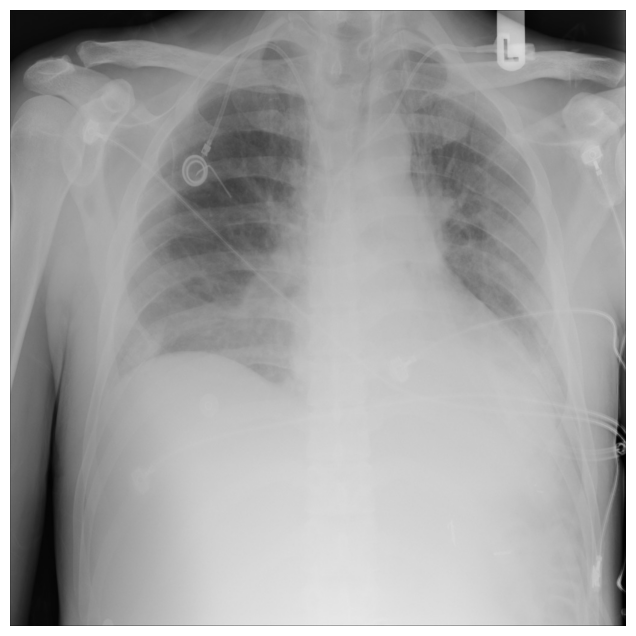

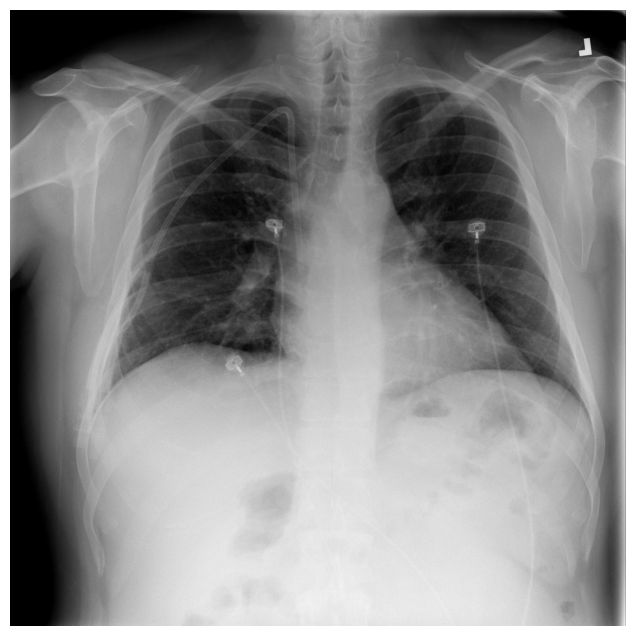

### Pneumonia Cases (Label 1) ###
Total Predictions: 2
Scores: tensor([0.6389, 0.0924], device='cuda:0')


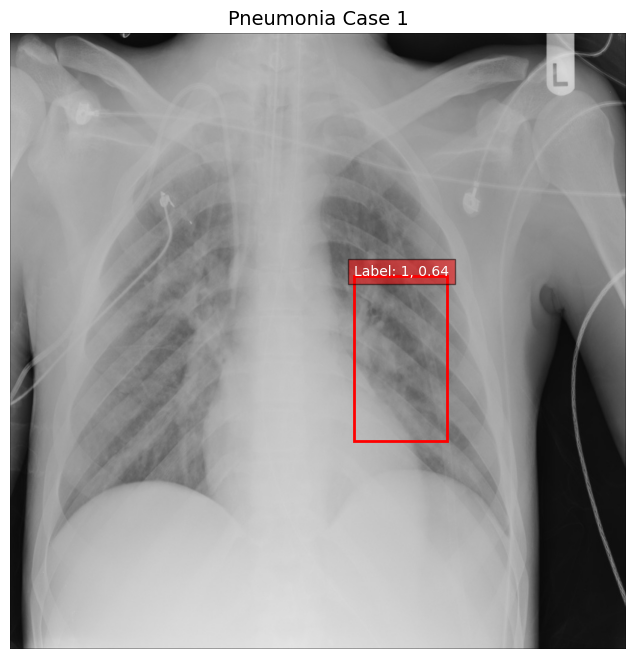

Total Predictions: 2
Scores: tensor([0.5818, 0.0938], device='cuda:0')


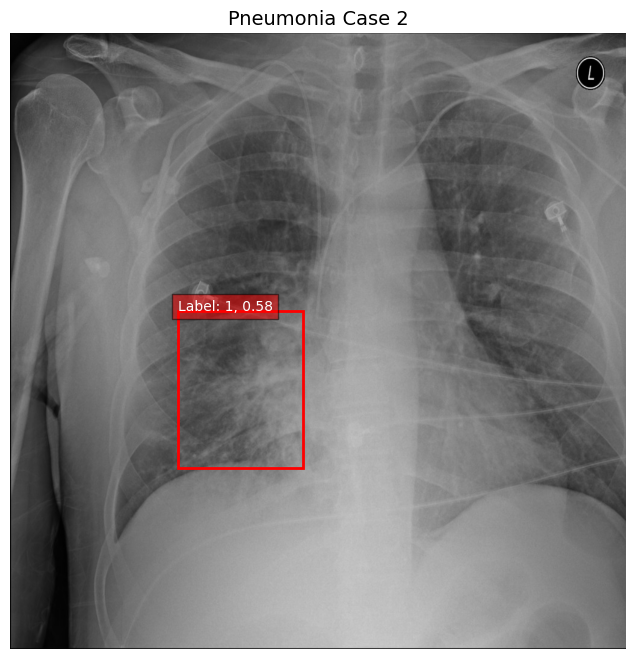

Total Predictions: 8
Scores: tensor([0.9474, 0.8223, 0.7334, 0.6141, 0.4236, 0.2165, 0.0977, 0.0799],
       device='cuda:0')


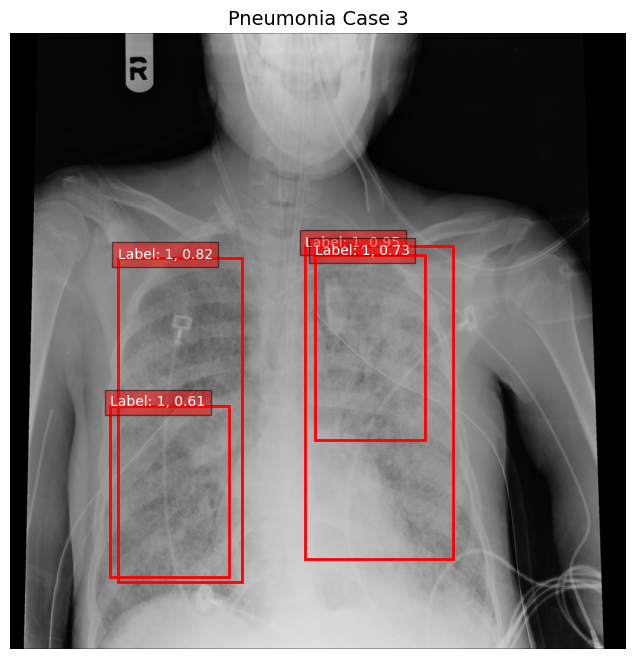

Total Predictions: 2
Scores: tensor([0.9429, 0.0596], device='cuda:0')


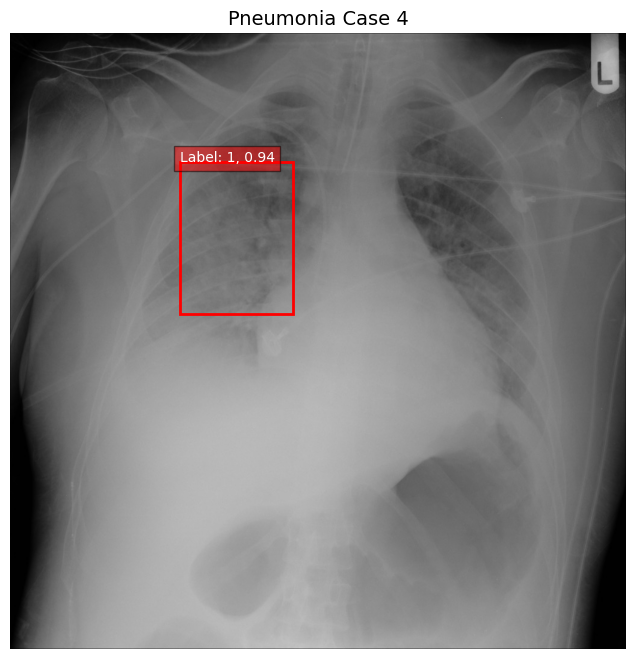

Total Predictions: 4
Scores: tensor([0.8228, 0.8159, 0.1279, 0.0965], device='cuda:0')


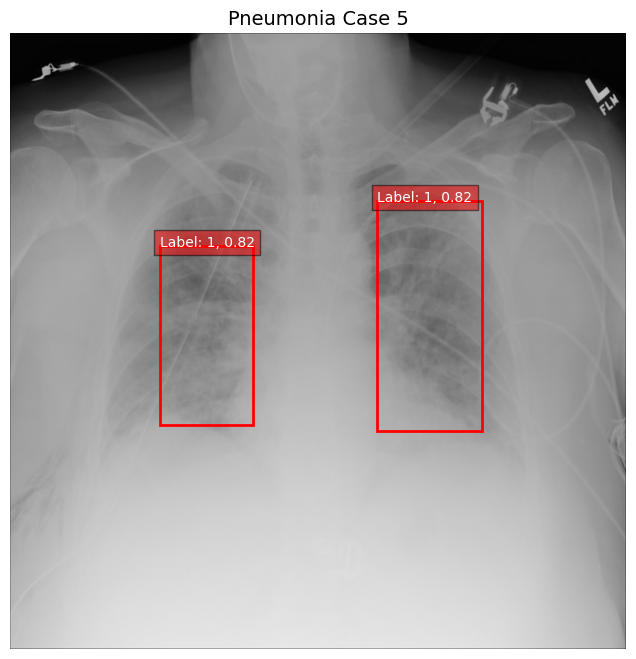

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch

def plot_image_with_predictions(image, predictions, conf_threshold=0.7, title="", figsize=(8, 8)):
    """
    Plots the image with predicted bounding boxes that have scores above conf_threshold.
    """
    if isinstance(image, torch.Tensor):
        image_np = image.permute(1, 2, 0).cpu().numpy()
    else:
        image_np = image

    fig, ax = plt.subplots(1, figsize=figsize)
    ax.imshow(image_np)

    boxes = predictions.get("boxes", [])
    labels = predictions.get("labels", None)  # Ensure labels are properly extracted
    scores = predictions.get("scores", [])

    if not (len(boxes) and len(scores)):
        print("Warning: No valid bounding boxes detected.")
        plt.axis('off')
        plt.show()
        return

    # Debugging prints
    print(f"Total Predictions: {len(boxes)}")
    print(f"Scores: {scores}")

    # Ensure labels exist and match boxes
    if labels is None or len(labels) != len(boxes):
        print(f"Warning: Labels missing or misaligned. Expected {len(boxes)}, got {len(labels) if labels else 0}")
        labels = torch.ones(len(boxes))  # Default pneumonia label (1) for all boxes

    filtered_boxes, filtered_labels, filtered_scores = [], [], []

    for i, box in enumerate(boxes):
        score = scores[i].item() if isinstance(scores[i], torch.Tensor) else scores[i]
        if score >= conf_threshold:
            filtered_boxes.append(box)

            # Ensure valid label
            if labels is not None and i < len(labels):
                label = labels[i]
                if isinstance(label, torch.Tensor):
                    label = label.item()
            else:
                label = 1  # Default pneumonia label if missing

            filtered_labels.append(label)
            filtered_scores.append(score)

    if not filtered_boxes:
        print(f"No bounding boxes meet the confidence threshold ({conf_threshold}).")
        plt.axis('off')
        plt.show()
        return

    # Plot filtered boxes
    for i, box in enumerate(filtered_boxes):
        if isinstance(box, torch.Tensor):
            box = box.cpu().numpy()
        xmin, ymin, xmax, ymax = box
        width, height = xmax - xmin, ymax - ymin

        rect = patches.Rectangle((xmin, ymin), width, height, linewidth=2, edgecolor='r', facecolor='none')
        ax.add_patch(rect)

        label_text = f"Label: {filtered_labels[i]}, {filtered_scores[i]:.2f}"
        ax.text(xmin, ymin, label_text, fontsize=10, color='white',
                bbox=dict(facecolor='red', alpha=0.5))

    ax.set_title(title, fontsize=14)
    plt.axis('off')
    plt.show()

# --- Collect images with label 0 (normal) and label 1 (pneumonia) ---
normal_cases, pneumonia_cases = [], []

for i, (image, annotation) in enumerate(val_dataset):
    if len(normal_cases) >= 5 and len(pneumonia_cases) >= 5:
        break  # Stop when we have 5 cases for each class

    labels = annotation.get("labels", torch.tensor([]))

    if torch.any(labels == 1) and len(pneumonia_cases) < 5:
        pneumonia_cases.append((image, annotation, all_predictions[i]))
    elif torch.all(labels == 0) and len(normal_cases) < 5:
        normal_cases.append((image, annotation, all_predictions[i]))

# --- Plot the images with a defined confidence threshold ---
confidence_threshold = 0.5  # Adjust as needed

print("### Normal Cases (Label 0) ###")
for i, (image, annotation, prediction) in enumerate(normal_cases):
    plot_image_with_predictions(image, prediction, conf_threshold=confidence_threshold, title=f"Normal Case {i+1}")

print("### Pneumonia Cases (Label 1) ###")
for i, (image, annotation, prediction) in enumerate(pneumonia_cases):
    plot_image_with_predictions(image, prediction, conf_threshold=confidence_threshold, title=f"Pneumonia Case {i+1}")

#### <b> Predictions done for 5 images in each class, however, it can be seen that some of the normal images having bounding box with threshold more than 0.5, and vice versa.

In [ ]:
print(all_predictions[5])

{'boxes': tensor([], device='cuda:0', size=(0, 4)), 'labels': tensor([], device='cuda:0', dtype=torch.int64), 'scores': tensor([], device='cuda:0')}


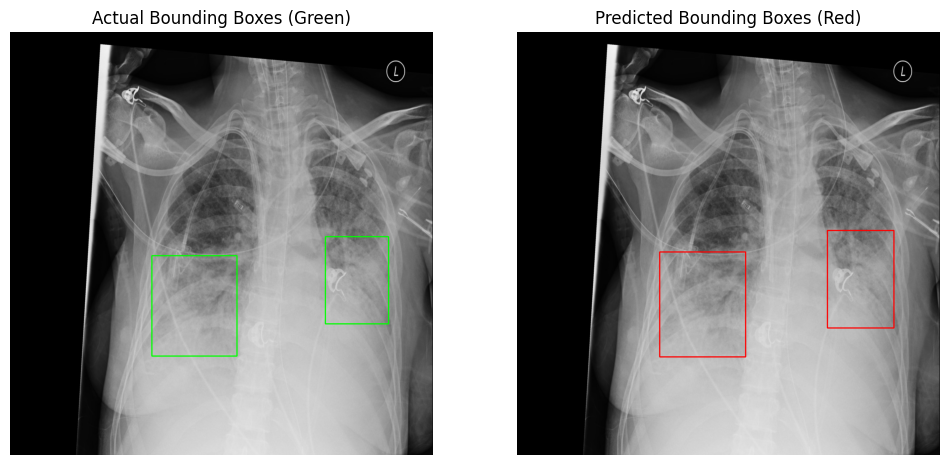

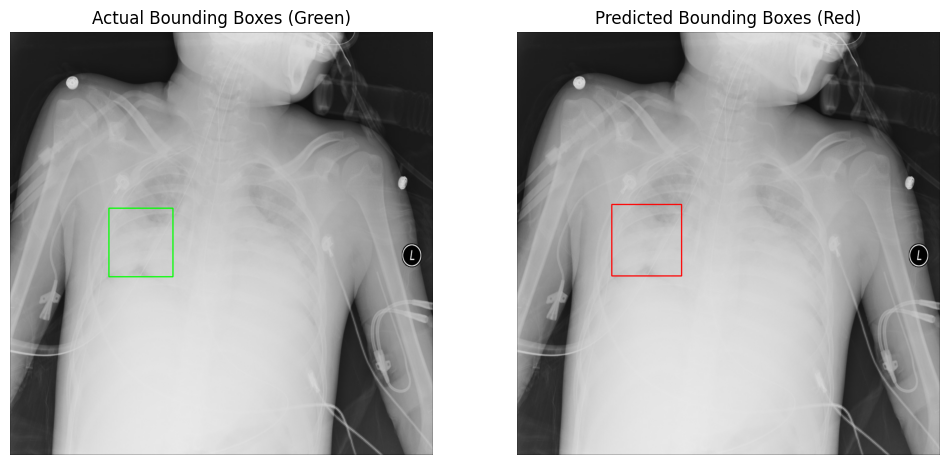

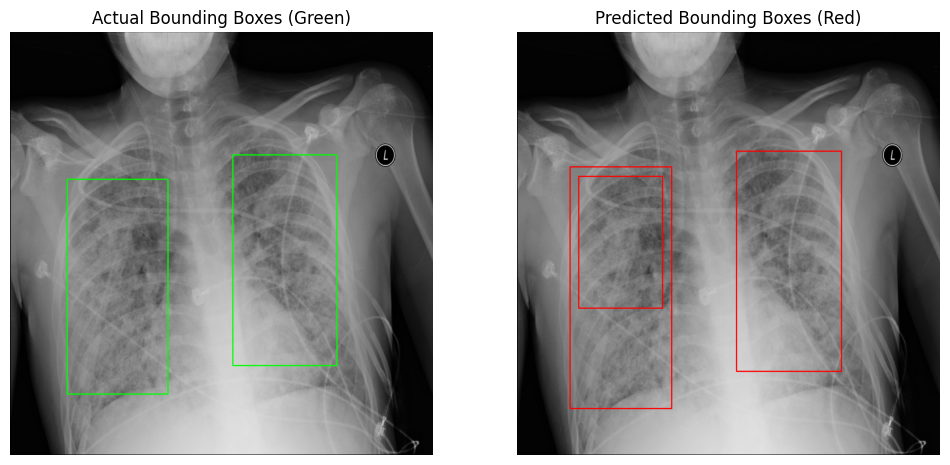

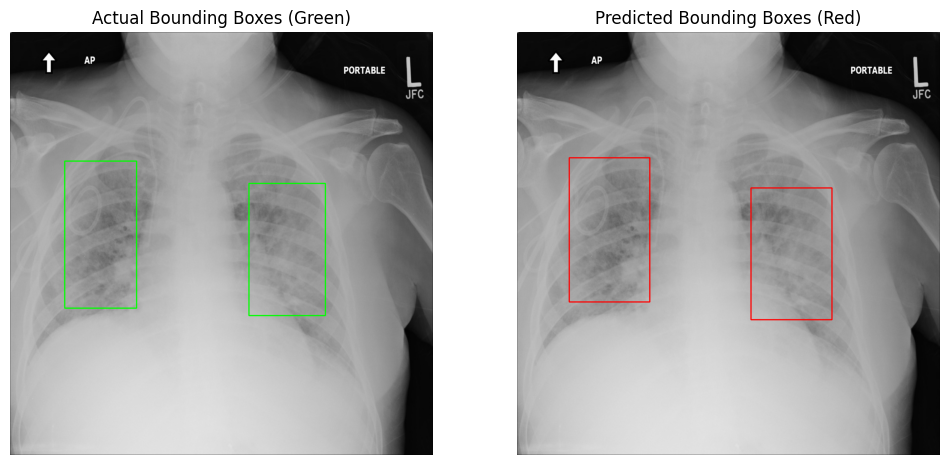

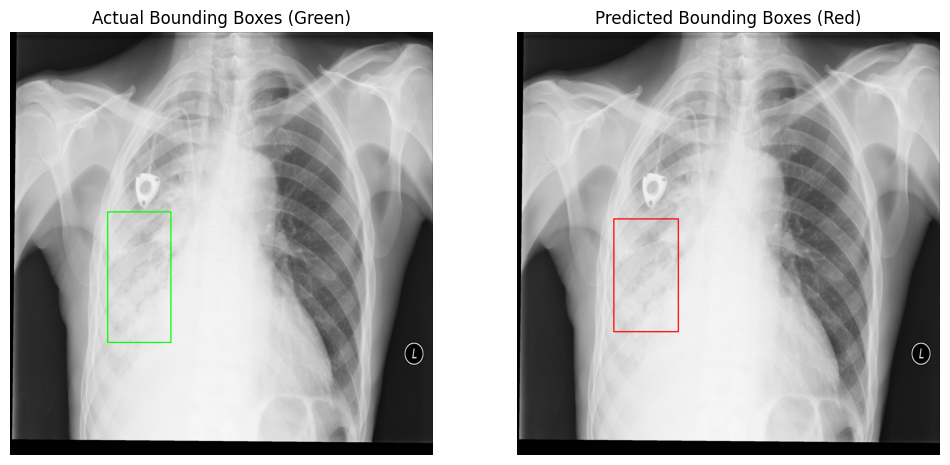

...

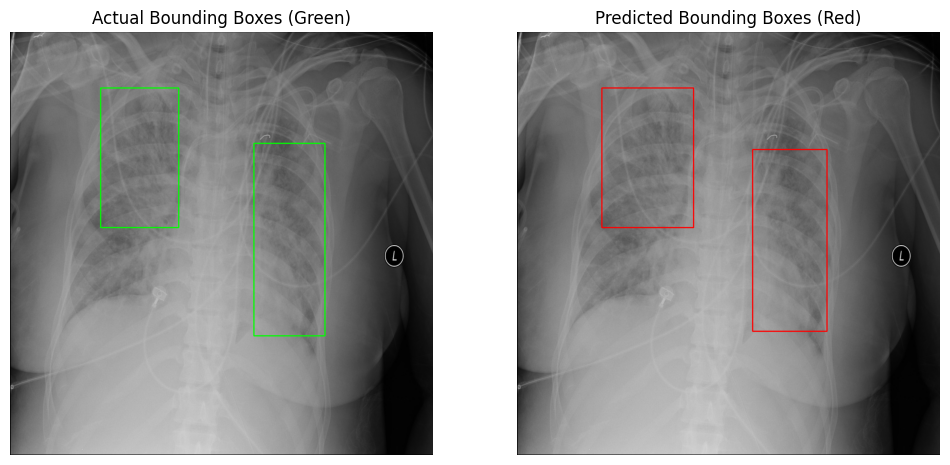

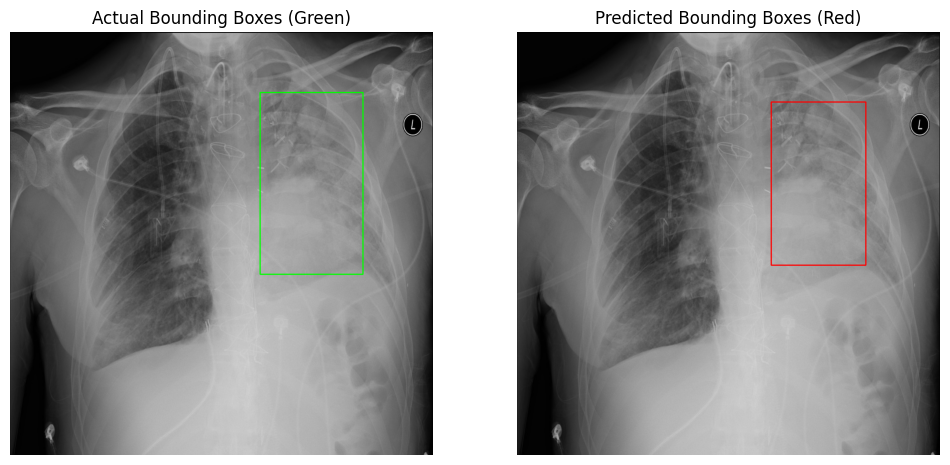

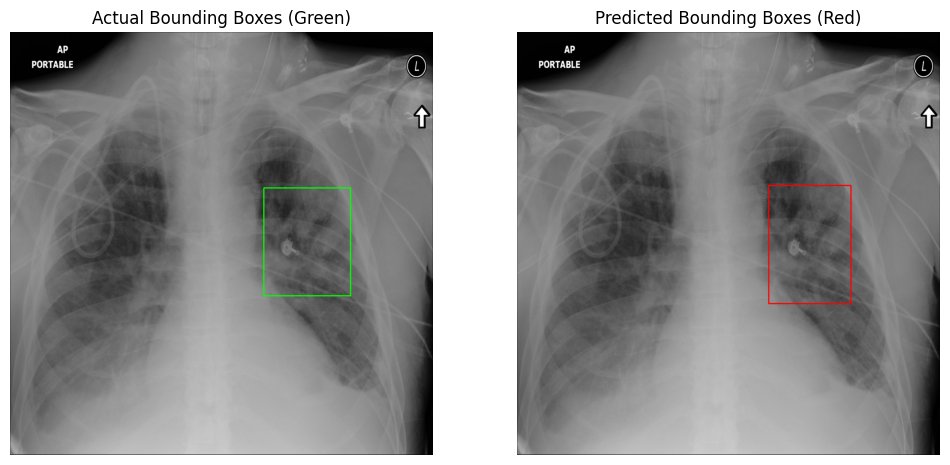

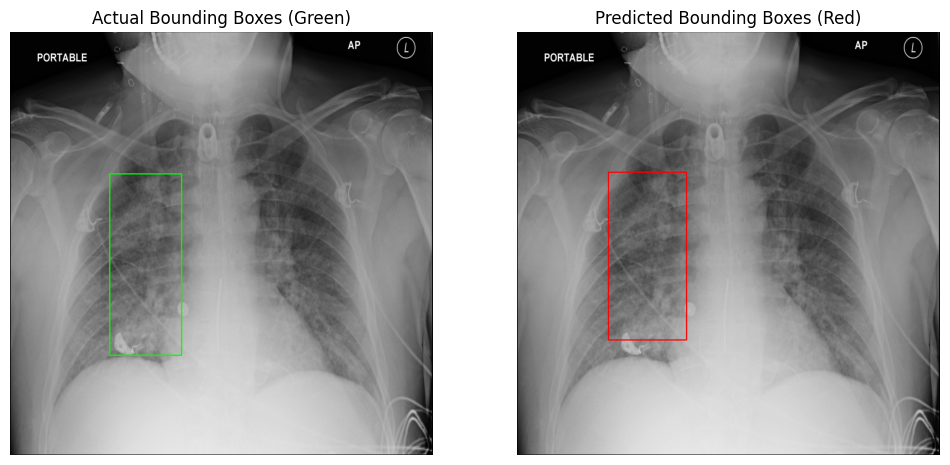

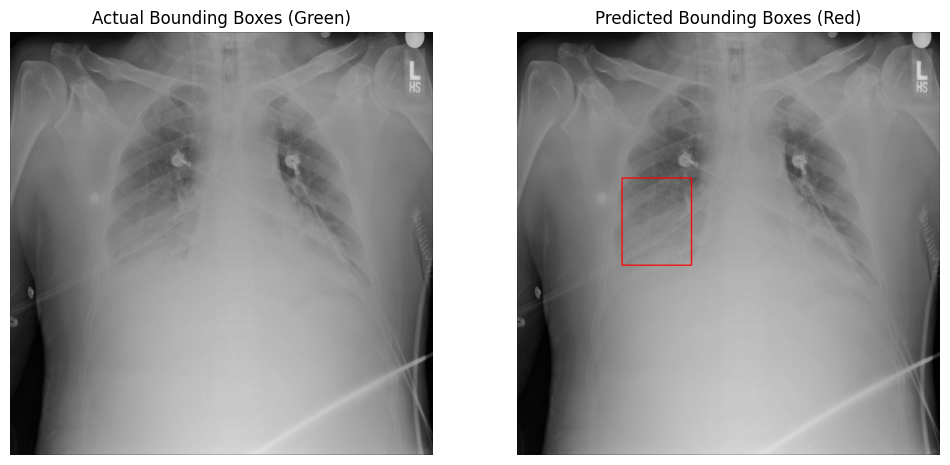

In [ ]:
import matplotlib.pyplot as plt

# Function to draw bounding boxes
def draw_boxes(image, boxes, color):
    # Ensure image is a NumPy array; if it's a PyTorch tensor, move it to CPU and convert
    if isinstance(image, torch.Tensor):
        image = image.cpu().numpy()

    # Ensure image is in uint8 format
    if image.dtype != np.uint8:
        image = (image * 255).astype(np.uint8)

    # Convert from CHW (if necessary) to HWC format
    if image.shape[0] in [1, 3]:
        image = np.transpose(image, (1, 2, 0))

    # Convert grayscale to BGR if needed
    if len(image.shape) == 2:
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

    height, width = image.shape[:2]

    # Only scale if boxes is non-empty
    if boxes.size > 0:
        # If boxes are normalized (max value <= 1), scale them to pixel coordinates
        if np.max(boxes) <= 1.0:
            boxes = boxes.copy()  # Work on a copy so we don't modify the original array
            boxes[:, [0, 2]] *= width
            boxes[:, [1, 3]] *= height

    # Draw each bounding box
    for box in boxes:
        x_min, y_min, x_max, y_max = map(int, box)
        # Optionally, ensure box coordinates are within the image boundaries
        x_min, x_max = max(0, x_min), min(width, x_max)
        y_min, y_max = max(0, y_min), min(height, y_max)
        if x_min >= x_max or y_min >= y_max:
            continue  # Skip invalid boxes
        cv2.rectangle(image, (x_min, y_min), (x_max, y_max), color, 2)

    return image


# Load training dataset for visualization
train_loader = DataLoader(train_dataset, batch_size=1, shuffle=True, collate_fn=lambda x: tuple(zip(*x)))

# Evaluate model on multiple training samples
model.eval()  # Set model to evaluation mode
num_images_to_show = 15
displayed_images = 0

with torch.no_grad():
    for images, targets in train_loader:
        if displayed_images >= num_images_to_show:
            break  # Stop once we have displayed enough images

        image = images[0].to(device)
        gt_boxes = targets[0]['boxes'].cpu().numpy()  # Ground truth boxes
        gt_labels = targets[0]['labels'].cpu().numpy()  # Ground truth labels

        # Get model predictions
        predictions = model([image])
        pred_boxes = predictions[0]['boxes'].cpu().numpy()  # Predicted boxes
        pred_scores = predictions[0]['scores'].cpu().numpy()  # Confidence scores
        pred_labels = predictions[0]['labels'].cpu().numpy()  # Predicted labels

        # Filter predictions with high confidence
        threshold = 0.5  # Adjust if necessary
        high_confidence_idx = pred_scores > threshold
        pred_boxes = pred_boxes[high_confidence_idx]
        pred_labels = pred_labels[high_confidence_idx]

        # Ensure the case has pneumonia (label 1)
        if 1 not in gt_labels and 1 not in pred_labels:
            continue  # Skip images without pneumonia

        # Convert PyTorch image tensor to NumPy for visualization
        image_np = image.cpu().numpy()

        # Convert CHW (3, H, W) to HWC (H, W, 3)
        image_np = np.transpose(image_np, (1, 2, 0))

        # Draw actual and predicted bounding boxes
        image_actual = draw_boxes(image_np.copy(), gt_boxes, color=(0, 255, 0))  # Green for actual boxes
        image_pred = draw_boxes(image_np.copy(), pred_boxes, color=(255, 0, 0))  # Red for predicted boxes

        # Now display the images
        fig, ax = plt.subplots(1, 2, figsize=(12, 6))
        ax[0].imshow(image_actual, cmap="gray")  # Ensure grayscale images render correctly
        ax[0].set_title("Actual Bounding Boxes (Green)")
        ax[0].axis("off")

        ax[1].imshow(image_pred, cmap="gray")
        ax[1].set_title("Predicted Bounding Boxes (Red)")
        ax[1].axis("off")

        plt.show()

        # ✅ Increment displayed_images count
        displayed_images += 1


#### <b> This code shows ground truth and predicted bounding boxes side by size for a better comparison. In some cases, as seen the bounding boxes are really similar qualitatively to ground truth whereas for some bounding boxes are present while ground truth  being a normal case, and vice versa.

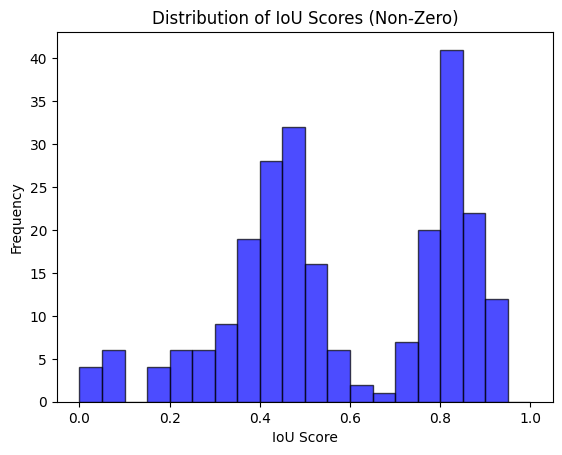

In [ ]:
import torch
import matplotlib.pyplot as plt

def compute_iou(box1, box2):
    """
    Compute Intersection over Union (IoU) between two bounding boxes.

    box1, box2: [x_min, y_min, x_max, y_max]
    """
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    # Compute intersection area
    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    # Compute union area
    box1_area = (box1[2] - box1[0]) * (box1[3] - box1[1])
    box2_area = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = box1_area + box2_area - intersection

    if union == 0:
        return 0.0

    return intersection / union

# --- Compute IoU for all predictions ---
iou_values = []

all_predictions = []
all_targets = []

with torch.no_grad():
    for images, targets in train_loader:
        image = images[0].to(device)
        gt_boxes = targets[0]['boxes'].cpu().numpy()  # Ground truth boxes
        gt_labels = targets[0]['labels'].cpu().numpy()  # Ground truth labels

        # Store ground truths
        all_targets.append({"boxes": gt_boxes, "labels": gt_labels})

        # Get model predictions
        predictions = model([image])
        pred_boxes = predictions[0]['boxes'].cpu().numpy()  # Predicted boxes
        pred_scores = predictions[0]['scores'].cpu().numpy()  # Confidence scores
        pred_labels = predictions[0]['labels'].cpu().numpy()  # Predicted labels

        # Store predictions
        all_predictions.append({"boxes": pred_boxes, "scores": pred_scores, "labels": pred_labels})


iou_values = []

for pred, target in zip(all_predictions, all_targets):
    pred_boxes = pred["boxes"]
    target_boxes = target["boxes"]

    for p_box in pred_boxes:
        best_iou = 0.0  # Track the highest IoU for this predicted box

        for t_box in target_boxes:
            iou = compute_iou(p_box, t_box)
            best_iou = max(best_iou, iou)

        # ✅ Only store nonzero IoU values
        if best_iou > 0:
            iou_values.append(best_iou)

# Plot IoU distribution without zero values
plt.hist(iou_values, bins=20, range=(0,1), color='blue', alpha=0.7, edgecolor='black')
plt.xlabel("IoU Score")
plt.ylabel("Frequency")
plt.title("Distribution of IoU Scores (Non-Zero)")
plt.show()

#### <b> IOU value distribution and its frequency. Looks like a bi-modal histogram with first mode being around 0.5, and other at 0.8.<br></b>
This suggests that the model's bounding box predictions tend to fall into two categories:
1. Poor IoU scores (0.4 - 0.5): These indicate weakly overlapping or misaligned predictions.

2. High IoU scores (0.8 - 0.9): These indicate well-aligned predictions with ground truth.

The presence of two peaks may indicate two groups of test cases, where the model performs well on some images but poorly on others. This could be due to:

* Differences in image quality.

* Variability in pneumonia severity.

* Certain lung regions being harder to detect.

* Biases in the dataset (e.g., some subtypes of pneumonia being easier to identify).



In [ ]:
pneumonia_iou_sum = 0
pneumonia_count = 0

for pred, (image, target) in zip(all_predictions, val_dataset):
    # Check if the image has pneumonia (ground truth boxes exist)
    if "boxes" in target and target["boxes"].numel() > 0:
        # Convert predictions to tensor if needed
        pred_boxes = torch.tensor(pred["boxes"]).cpu().numpy() if len(pred["boxes"]) > 0 else []
        target_boxes = target["boxes"].detach().cpu().numpy()

        for p_box in pred_boxes:
            best_iou = 0.0
            for t_box in target_boxes:
                iou = compute_iou(p_box, t_box)
                best_iou = max(best_iou, iou)
            # Only consider nonzero best IoU values
            if best_iou > 0:
                pneumonia_iou_sum += best_iou
                pneumonia_count += 1

# Compute the average only for pneumonia cases (nonzero best IoU per predicted box)
if pneumonia_count > 0:
    avg_pneumonia_iou = pneumonia_iou_sum / pneumonia_count
    print(f"Average IoU for Pneumonia Cases (Best Matches, Excluding Zero IoUs): {avg_pneumonia_iou:.4f}")
else:
    print("No valid pneumonia cases found in validation set.")

Average IoU for Pneumonia Cases (Best Matches, Excluding Zero IoUs): 0.2454


In [ ]:
from collections import defaultdict
import numpy as np

def compute_map(predictions, ground_truths, iou_threshold=0.5):
    """
    Compute Mean Average Precision (mAP) for object detection.

    predictions: List of predicted boxes and scores for each image
                 Format: [{ "boxes": [[x_min, y_min, x_max, y_max], ...], "scores": [conf1, conf2, ...] }]
    ground_truths: List of ground-truth boxes for each image
                 Format: [{ "boxes": [[x_min, y_min, x_max, y_max], ...] }]
    iou_threshold: Minimum IoU for a detection to be considered a True Positive (TP)
    """
    all_detections = []  # Store all predictions
    all_ground_truths = defaultdict(int)  # Count of ground truth boxes per image

    for image_id, (pred, gt) in enumerate(zip(predictions, ground_truths)):
        pred_boxes = pred["boxes"]
        pred_scores = pred["scores"]
        gt_boxes = gt["boxes"]

        all_ground_truths[image_id] = len(gt_boxes)

        for box, score in zip(pred_boxes, pred_scores):
            all_detections.append((image_id, box, score))

    # Sort predictions by confidence score (Descending order)
    all_detections.sort(key=lambda x: x[2], reverse=True)

    tp = np.zeros(len(all_detections))
    fp = np.zeros(len(all_detections))
    matched_gt_boxes = {key: [] for key in all_ground_truths.keys()}  # Track matched ground truth boxes

    for i, (image_id, pred_box, score) in enumerate(all_detections):
        gt_boxes = ground_truths[image_id]["boxes"]
        best_iou = 0
        best_gt_idx = -1

        for idx, gt_box in enumerate(gt_boxes):
            iou = compute_iou(pred_box, gt_box)
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = idx

        if best_iou >= iou_threshold and best_gt_idx not in matched_gt_boxes[image_id]:
            tp[i] = 1  # True Positive
            matched_gt_boxes[image_id].append(best_gt_idx)
        else:
            fp[i] = 1  # False Positive

    # Compute Precision-Recall Curve
    tp_cumsum = np.cumsum(tp)
    fp_cumsum = np.cumsum(fp)
    precisions = tp_cumsum / (tp_cumsum + fp_cumsum + 1e-7)  # Precision
    recalls = tp_cumsum / (sum(all_ground_truths.values()) + 1e-7)  # Recall

    # Compute Average Precision (AP)
    ap = np.trapz(precisions, recalls)
    return ap

In [ ]:
# Convert predictions and ground truths to the required format
def format_predictions_and_ground_truths(preds, targets):
    formatted_preds = []
    formatted_targets = []

    for pred, target in zip(preds, targets):
        pred_boxes = pred["boxes"].detach().cpu().numpy().tolist()
        pred_scores = pred["scores"].detach().cpu().numpy().tolist()
        gt_boxes = target["boxes"].detach().cpu().numpy().tolist()

        formatted_preds.append({"boxes": pred_boxes, "scores": pred_scores})
        formatted_targets.append({"boxes": gt_boxes})

    return formatted_preds, formatted_targets

# Run evaluation
model.eval()
all_predictions = []
all_targets = []

with torch.no_grad():
    for images, targets in val_loader:
        images = [img.to(device) for img in images]
        preds = model(images)  # Model predictions

        formatted_preds, formatted_targets = format_predictions_and_ground_truths(preds, targets)
        all_predictions.extend(formatted_preds)
        all_targets.extend(formatted_targets)

# Compute mAP
map_score = compute_map(all_predictions, all_targets, iou_threshold=0.5)
print(f"mAP@0.5: {map_score:.4f}")

mAP@0.5: 0.3033


<ipython-input-41-2759aa37b7e2>:58: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap = np.trapz(precisions, recalls)


#### <b> The Mean Average Precision comes out to be 0.303.<br></b>
<b>NOTE:</b> More training data can be used to improve the model. Also, Fine-tuning hyperparameters, dataset quality, and model architecture should improve performance.

#### <b>MODEL LOADING : MobileNetV3

<b> 2. Faster R-CNN MobileNetV3 Large 320 FPN: A lightweight Faster R-CNN with MobileNetV3-Large and FPN, optimized for low-resolution inputs, sacrificing accuracy for better speed.

In [ ]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn

In [ ]:
# Loading pre-trained Faster R-CNN
model_2 = fasterrcnn_mobilenet_v3_large_320_fpn(pretrained=True)

# Modify the classification head for pneumonia detection
num_classes = 2  # Background (0) + Pneumonia (1)
in_features = model_2.roi_heads.box_predictor.cls_score.in_features
model_2.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(in_features, num_classes)

# Move to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_2.to(device)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth
100%|██████████| 74.2M/74.2M [00:01<00:00, 49.1MB/s]


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(320,), max_size=640, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): FrozenBatchNorm2d(16, eps=1e-05)
        (2): Hardswish()
      )
      (1): InvertedResidual(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
            (1): FrozenBatchNorm2d(16, eps=1e-05)
            (2): ReLU(inplace=True)
          )
          (1): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (1): FrozenBatchNorm2d(16, eps=1e-05)
          )
        )
      )
      (2): InvertedResidual(
        (block): 

Epoch [1/5] - Total Loss: 0.2023 | Cls Loss: 0.1526 | Box Reg Loss: 0.0276 | Obj Loss: 0.0208 | RPN Box Reg Loss: 0.0012
Epoch [2/5] - Total Loss: 0.3761 | Cls Loss: 0.1914 | Box Reg Loss: 0.1752 | Obj Loss: 0.0085 | RPN Box Reg Loss: 0.0009
Epoch [3/5] - Total Loss: 0.4789 | Cls Loss: 0.2307 | Box Reg Loss: 0.2408 | Obj Loss: 0.0066 | RPN Box Reg Loss: 0.0008
Epoch [4/5] - Total Loss: 0.5505 | Cls Loss: 0.2548 | Box Reg Loss: 0.2902 | Obj Loss: 0.0048 | RPN Box Reg Loss: 0.0007
Epoch [5/5] - Total Loss: 0.6535 | Cls Loss: 0.2857 | Box Reg Loss: 0.3634 | Obj Loss: 0.0037 | RPN Box Reg Loss: 0.0007
Training complete!


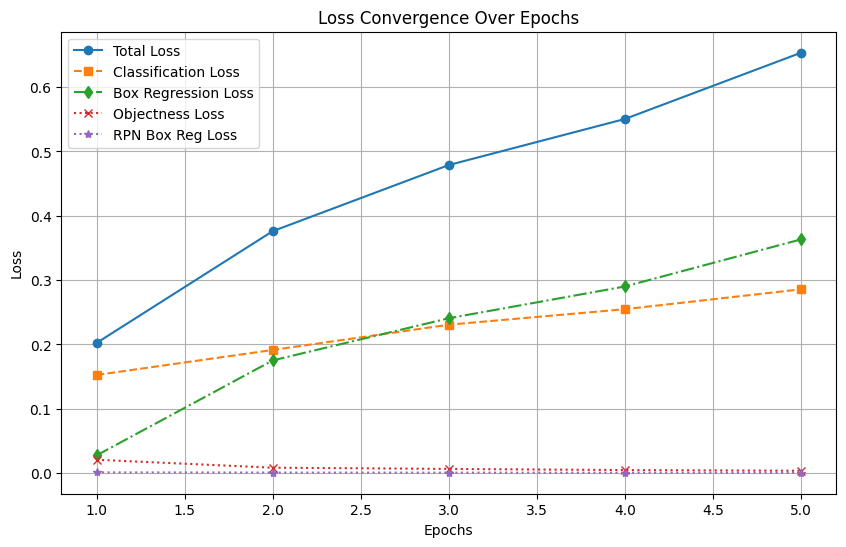

In [ ]:
# Define optimizer & learning rate scheduler
params = [p for p in model_2.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(params, lr=0.0001)

# Lists to store loss values for visualization
total_losses = []
cls_losses = []
box_reg_losses = []
obj_losses = []
rpn_box_reg_losses = []

# Training Loop
num_epochs = 5  # Set number of epochs

for epoch in range(num_epochs):
    model_2.train()  # Set model to training mode
    total_loss = 0  # Initialize total loss for this epoch
    total_cls_loss = 0
    total_box_reg_loss = 0
    total_obj_loss = 0
    total_rpn_box_reg_loss = 0

    num_batches = len(train_loader)  # Track number of batches

    for images, targets in train_loader:
        # Move images and targets to the device (GPU/CPU)
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        optimizer.zero_grad()  # Zero the gradients before backpropagation

        # Forward pass through the model; it returns a dictionary of losses
        loss_dict = model_2(images, targets)

        # Extract individual losses
        loss_classifier = loss_dict.get("loss_classifier", torch.tensor(0.0))
        loss_box_reg = loss_dict.get("loss_box_reg", torch.tensor(0.0))
        loss_objectness = loss_dict.get("loss_objectness", torch.tensor(0.0))
        loss_rpn_box_reg = loss_dict.get("loss_rpn_box_reg", torch.tensor(0.0))

        # Sum all losses
        loss = loss_classifier + loss_box_reg + loss_objectness + loss_rpn_box_reg

        loss.backward()  # Backpropagate to compute gradients
        optimizer.step()  # Update the model's weights

        # Accumulate the losses for reporting
        total_loss += loss.item()
        total_cls_loss += loss_classifier.item()
        total_box_reg_loss += loss_box_reg.item()
        total_obj_loss += loss_objectness.item()
        total_rpn_box_reg_loss += loss_rpn_box_reg.item()

    # Store average losses for this epoch
    avg_total_loss = total_loss / num_batches
    avg_cls_loss = total_cls_loss / num_batches
    avg_box_reg_loss = total_box_reg_loss / num_batches
    avg_obj_loss = total_obj_loss / num_batches
    avg_rpn_box_reg_loss = total_rpn_box_reg_loss / num_batches

    total_losses.append(avg_total_loss)
    cls_losses.append(avg_cls_loss)
    box_reg_losses.append(avg_box_reg_loss)
    obj_losses.append(avg_obj_loss)
    rpn_box_reg_losses.append(avg_rpn_box_reg_loss)

    # Print the average losses for the epoch
    print(f"Epoch [{epoch+1}/{num_epochs}] - Total Loss: {avg_total_loss:.4f} | "
          f"Cls Loss: {avg_cls_loss:.4f} | "
          f"Box Reg Loss: {avg_box_reg_loss:.4f} | "
          f"Obj Loss: {avg_obj_loss:.4f} | "
          f"RPN Box Reg Loss: {avg_rpn_box_reg_loss:.4f}")

print("Training complete!")
import matplotlib.pyplot as plt
# ✅ Plot Loss Curves
plt.figure(figsize=(10, 6))
plt.plot(range(1, num_epochs+1), total_losses, label="Total Loss", marker="o", linestyle="-")
plt.plot(range(1, num_epochs+1), cls_losses, label="Classification Loss", marker="s", linestyle="--")
plt.plot(range(1, num_epochs+1), box_reg_losses, label="Box Regression Loss", marker="d", linestyle="-.")
plt.plot(range(1, num_epochs+1), obj_losses, label="Objectness Loss", marker="x", linestyle=":")
plt.plot(range(1, num_epochs+1), rpn_box_reg_losses, label="RPN Box Reg Loss", marker="*", linestyle=":")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Convergence Over Epochs")
plt.legend()
plt.grid(True)
plt.show()

<b>3.Faster R-CNN MobileNetV3 Large FPN: Similar to the previous model but works with higher-resolution inputs, providing a balance between efficiency and detection accuracy.

In [ ]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn

In [ ]:
# Loading pre-trained Faster R-CNN
model_3 = fasterrcnn_mobilenet_v3_large_fpn(pretrained=True)

# Modify the classification head for pneumonia detection
num_classes = 2  # Background (0) + Pneumonia (1)
in_features = model_3.roi_heads.box_predictor.cls_score.in_features
model_3.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(in_features, num_classes)

# Move to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_3.to(device)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_MobileNet_V3_Large_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth
100%|██████████| 74.2M/74.2M [00:00<00:00, 80.3MB/s]


FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): FrozenBatchNorm2d(16, eps=1e-05)
        (2): Hardswish()
      )
      (1): InvertedResidual(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
            (1): FrozenBatchNorm2d(16, eps=1e-05)
            (2): ReLU(inplace=True)
          )
          (1): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (1): FrozenBatchNorm2d(16, eps=1e-05)
          )
        )
      )
      (2): InvertedResidual(
        (block):

Epoch [1/5] - Total Loss: 0.2897 | Cls Loss: 0.1707 | Box Reg Loss: 0.0893 | Obj Loss: 0.0279 | RPN Box Reg Loss: 0.0018
Epoch [2/5] - Total Loss: 0.4813 | Cls Loss: 0.2245 | Box Reg Loss: 0.2478 | Obj Loss: 0.0077 | RPN Box Reg Loss: 0.0012
Epoch [3/5] - Total Loss: 0.4502 | Cls Loss: 0.2126 | Box Reg Loss: 0.2296 | Obj Loss: 0.0068 | RPN Box Reg Loss: 0.0012
Epoch [4/5] - Total Loss: 0.6094 | Cls Loss: 0.2763 | Box Reg Loss: 0.3279 | Obj Loss: 0.0040 | RPN Box Reg Loss: 0.0011
Epoch [5/5] - Total Loss: 0.6007 | Cls Loss: 0.2574 | Box Reg Loss: 0.3394 | Obj Loss: 0.0029 | RPN Box Reg Loss: 0.0010
Training complete!


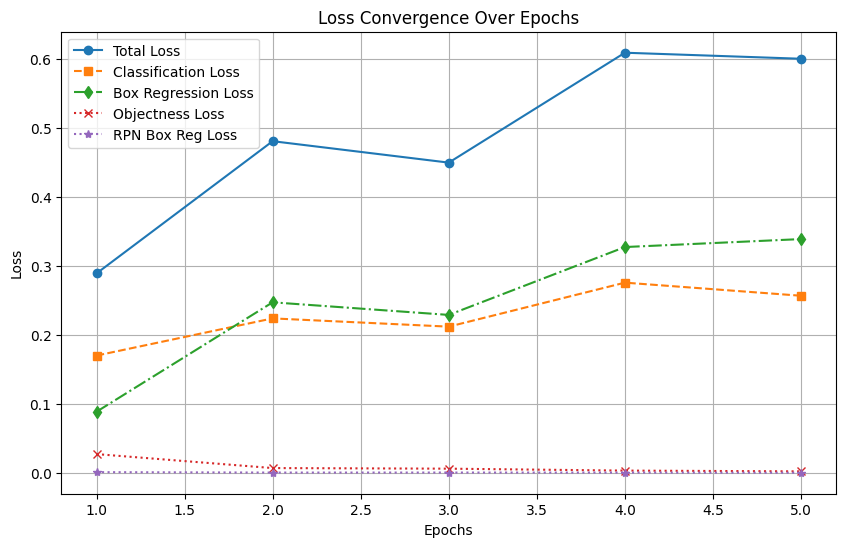

In [ ]:
# Define optimizer & learning rate scheduler
params = [p for p in model_3.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(params, lr=0.0001)

# Lists to store loss values for visualization
total_losses = []
cls_losses = []
box_reg_losses = []
obj_losses = []
rpn_box_reg_losses = []

# Training Loop
num_epochs = 5  # Set number of epochs

for epoch in range(num_epochs):
    model_3.train()  # Set model to training mode
    total_loss = 0  # Initialize total loss for this epoch
    total_cls_loss = 0
    total_box_reg_loss = 0
    total_obj_loss = 0
    total_rpn_box_reg_loss = 0

    num_batches = len(train_loader)  # Track number of batches

    for images, targets in train_loader:
        # Move images and targets to the device (GPU/CPU)
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        optimizer.zero_grad()  # Zero the gradients before backpropagation

        # Forward pass through the model; it returns a dictionary of losses
        loss_dict = model_3(images, targets)

        # Extract individual losses
        loss_classifier = loss_dict.get("loss_classifier", torch.tensor(0.0))
        loss_box_reg = loss_dict.get("loss_box_reg", torch.tensor(0.0))
        loss_objectness = loss_dict.get("loss_objectness", torch.tensor(0.0))
        loss_rpn_box_reg = loss_dict.get("loss_rpn_box_reg", torch.tensor(0.0))

        # Sum all losses
        loss = loss_classifier + loss_box_reg + loss_objectness + loss_rpn_box_reg

        loss.backward()  # Backpropagate to compute gradients
        optimizer.step()  # Update the model's weights

        # Accumulate the losses for reporting
        total_loss += loss.item()
        total_cls_loss += loss_classifier.item()
        total_box_reg_loss += loss_box_reg.item()
        total_obj_loss += loss_objectness.item()
        total_rpn_box_reg_loss += loss_rpn_box_reg.item()

    # Store average losses for this epoch
    avg_total_loss = total_loss / num_batches
    avg_cls_loss = total_cls_loss / num_batches
    avg_box_reg_loss = total_box_reg_loss / num_batches
    avg_obj_loss = total_obj_loss / num_batches
    avg_rpn_box_reg_loss = total_rpn_box_reg_loss / num_batches

    total_losses.append(avg_total_loss)
    cls_losses.append(avg_cls_loss)
    box_reg_losses.append(avg_box_reg_loss)
    obj_losses.append(avg_obj_loss)
    rpn_box_reg_losses.append(avg_rpn_box_reg_loss)

    # Print the average losses for the epoch
    print(f"Epoch [{epoch+1}/{num_epochs}] - Total Loss: {avg_total_loss:.4f} | "
          f"Cls Loss: {avg_cls_loss:.4f} | "
          f"Box Reg Loss: {avg_box_reg_loss:.4f} | "
          f"Obj Loss: {avg_obj_loss:.4f} | "
          f"RPN Box Reg Loss: {avg_rpn_box_reg_loss:.4f}")

print("Training complete!")
import matplotlib.pyplot as plt
# ✅ Plot Loss Curves
plt.figure(figsize=(10, 6))
plt.plot(range(1, num_epochs+1), total_losses, label="Total Loss", marker="o", linestyle="-")
plt.plot(range(1, num_epochs+1), cls_losses, label="Classification Loss", marker="s", linestyle="--")
plt.plot(range(1, num_epochs+1), box_reg_losses, label="Box Regression Loss", marker="d", linestyle="-.")
plt.plot(range(1, num_epochs+1), obj_losses, label="Objectness Loss", marker="x", linestyle=":")
plt.plot(range(1, num_epochs+1), rpn_box_reg_losses, label="RPN Box Reg Loss", marker="*", linestyle=":")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Convergence Over Epochs")
plt.legend()
plt.grid(True)
plt.show()

<br><h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Observations:</b></font></h3>

Selecting Model 3 for predictions out of the MobileNetV3 models due to the following:

1. It has a lower final classification loss, meaning it classifies pneumonia cases more accurately.
2. It has a lower final box regression loss, meaning it localizes pneumonia areas more precisely.
3. Its total loss is slightly lower than Model 2 at the end.

In [ ]:
model_3.eval()  # Set model to evaluation mode
all_predictions = []  # To store predictions for all images

with torch.no_grad():
    for images, targets in val_loader:
        images = [img.to(device) for img in images]
        preds = model_3(images)  # In eval mode, model returns predictions per image
        all_predictions.extend(preds)

print(f"Obtained predictions for {len(all_predictions)} images.")

Obtained predictions for 125 images.


### Normal Cases (Label 0) ###


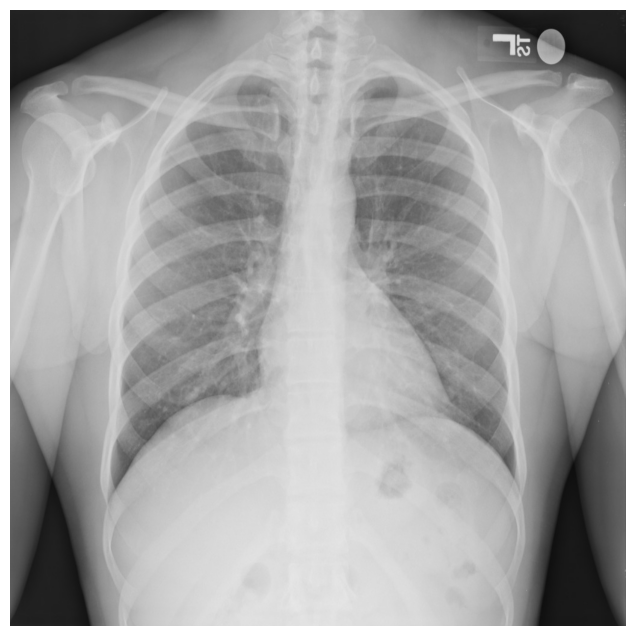

Total Predictions: 4
Scores: tensor([0.4370, 0.0781, 0.0589, 0.0551], device='cuda:0')


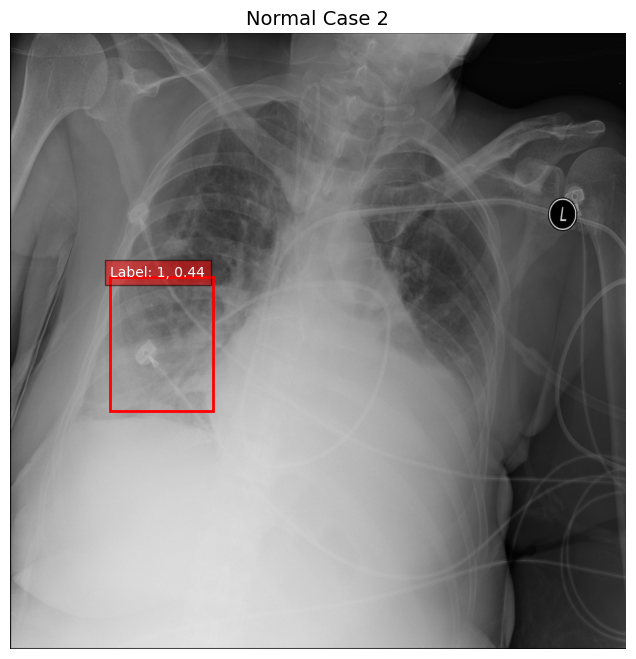

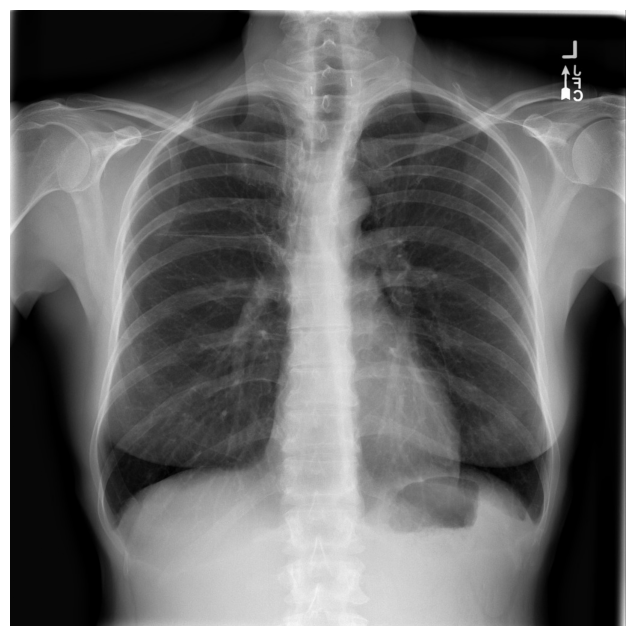

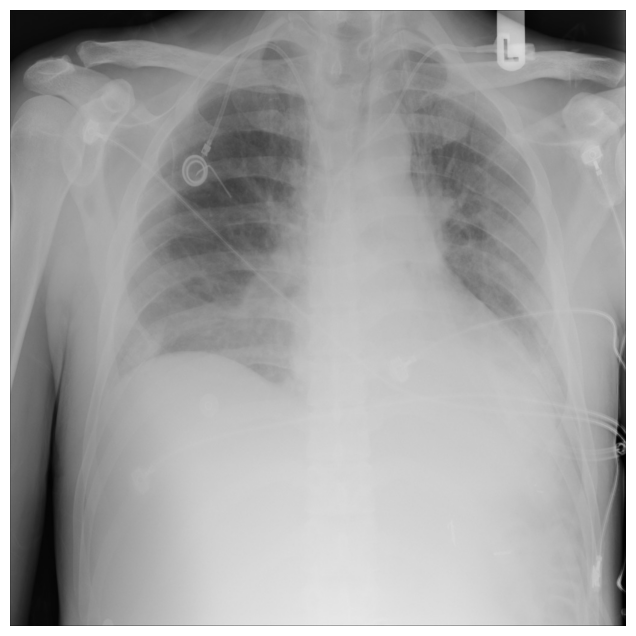

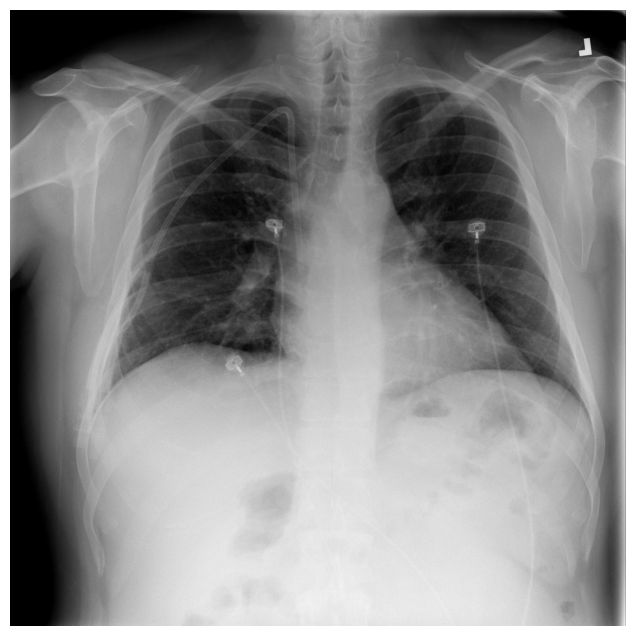

### Pneumonia Cases (Label 1) ###
Total Predictions: 4
Scores: tensor([0.2596, 0.0941, 0.0883, 0.0611], device='cuda:0')
No bounding boxes meet the confidence threshold (0.4).


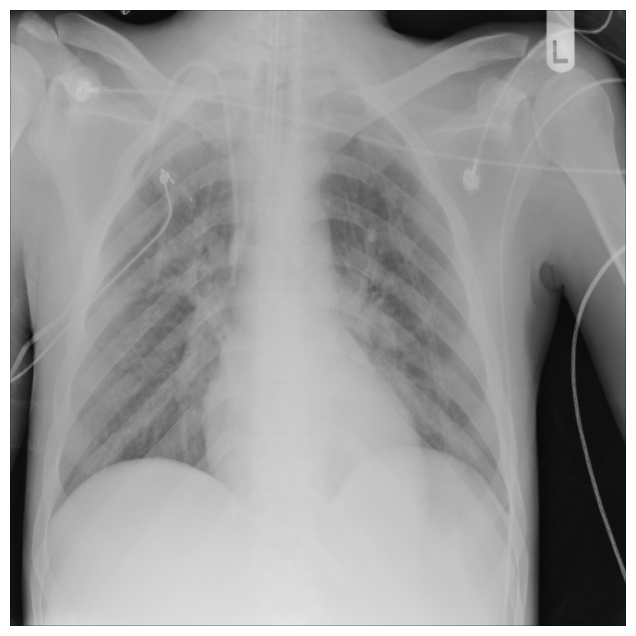

Total Predictions: 4
Scores: tensor([0.6667, 0.1094, 0.0878, 0.0699], device='cuda:0')


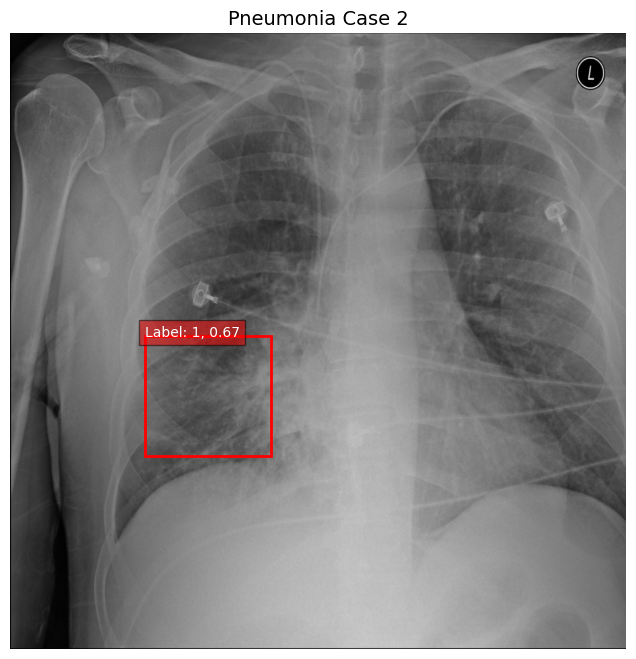

Total Predictions: 8
Scores: tensor([0.7722, 0.7166, 0.3289, 0.1333, 0.1332, 0.1039, 0.0770, 0.0756],
       device='cuda:0')


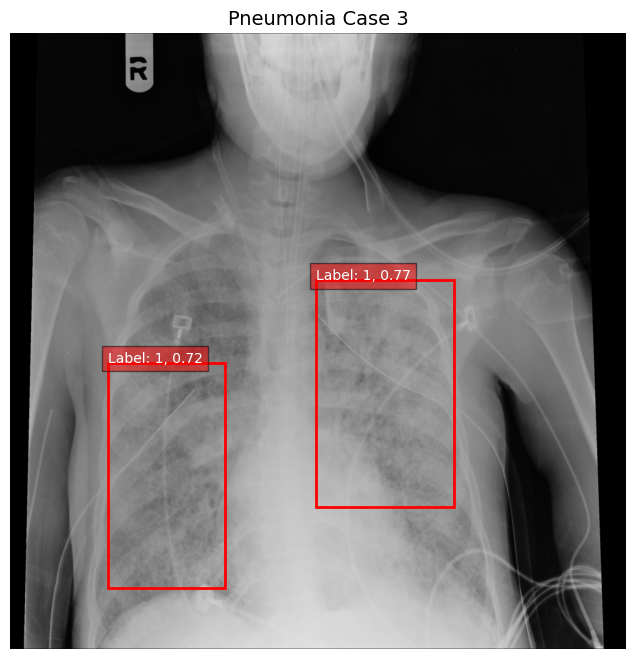

Total Predictions: 1
Scores: tensor([0.6995], device='cuda:0')


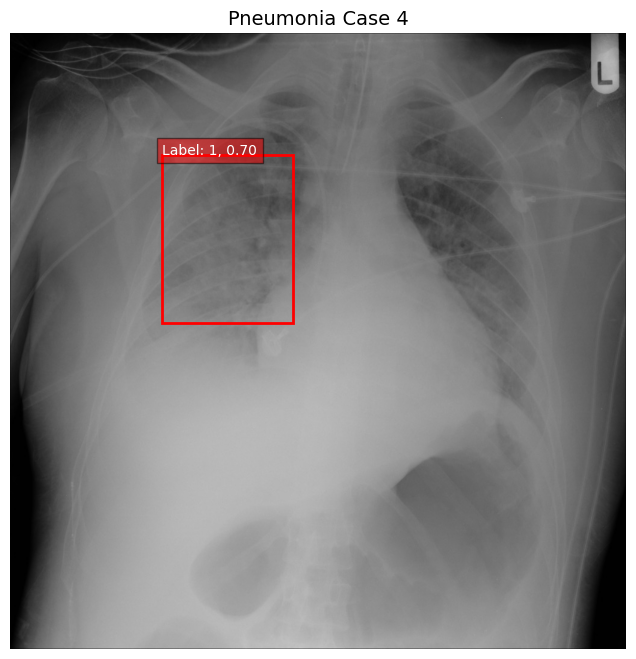

Total Predictions: 2
Scores: tensor([0.1086, 0.0591], device='cuda:0')
No bounding boxes meet the confidence threshold (0.4).


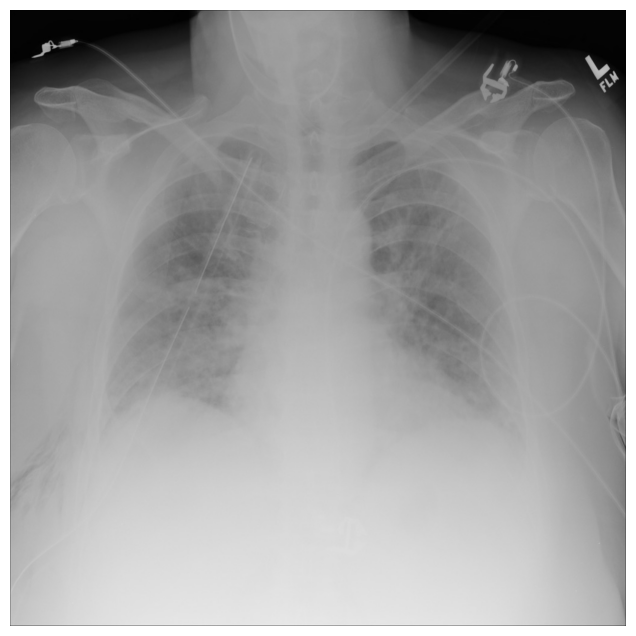

In [ ]:
normal_cases, pneumonia_cases = [], []

for i, (image, annotation) in enumerate(val_dataset):
    if len(normal_cases) >= 5 and len(pneumonia_cases) >= 5:
        break  # Stop when we have 5 cases for each class

    labels = annotation.get("labels", torch.tensor([]))

    if torch.any(labels == 1) and len(pneumonia_cases) < 5:
        pneumonia_cases.append((image, annotation, all_predictions[i]))
    elif torch.all(labels == 0) and len(normal_cases) < 5:
        normal_cases.append((image, annotation, all_predictions[i]))

# --- Plot the images with a defined confidence threshold ---
confidence_threshold = 0.4

print("### Normal Cases (Label 0) ###")
for i, (image, annotation, prediction) in enumerate(normal_cases):
    plot_image_with_predictions(image, prediction, conf_threshold=confidence_threshold, title=f"Normal Case {i+1}")

print("### Pneumonia Cases (Label 1) ###")
for i, (image, annotation, prediction) in enumerate(pneumonia_cases):
    plot_image_with_predictions(image, prediction, conf_threshold=confidence_threshold, title=f"Pneumonia Case {i+1}")

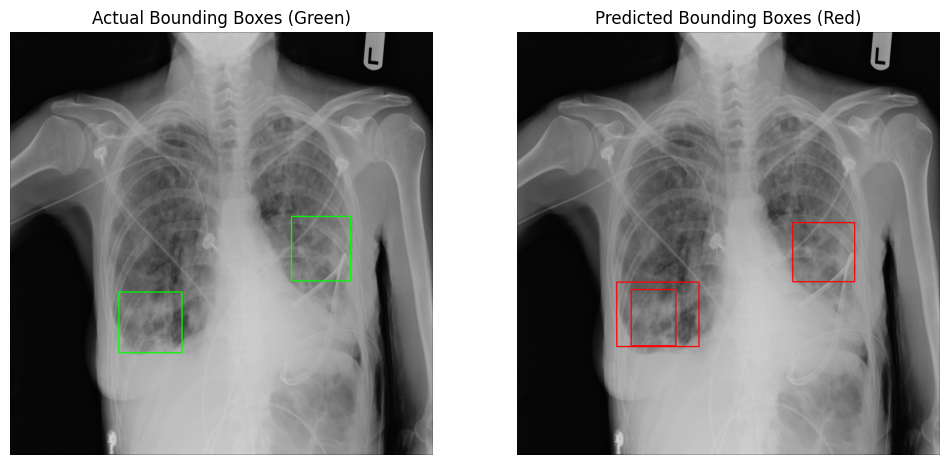

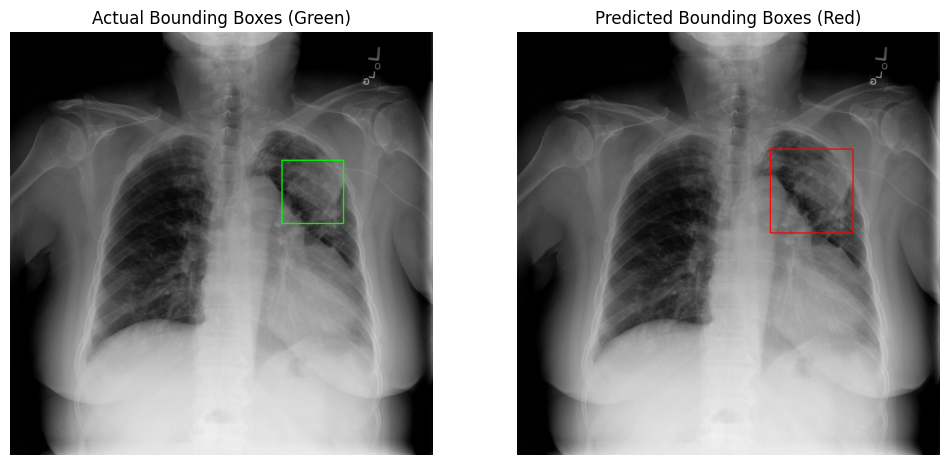

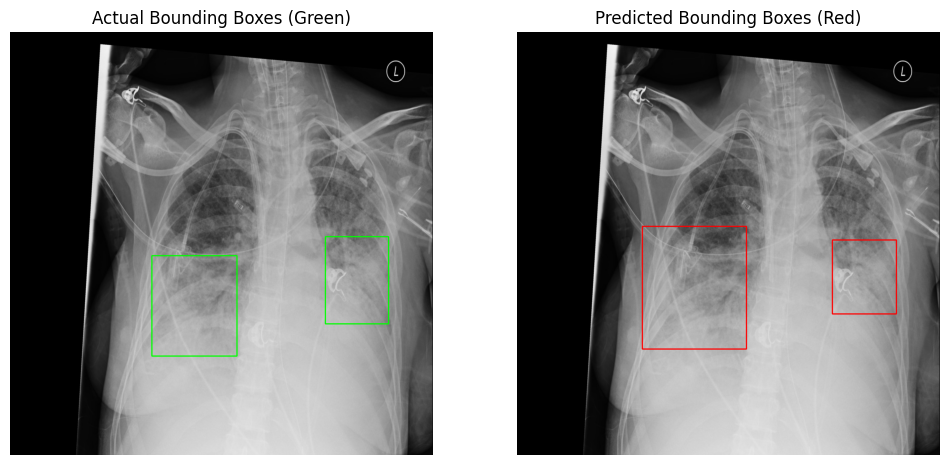

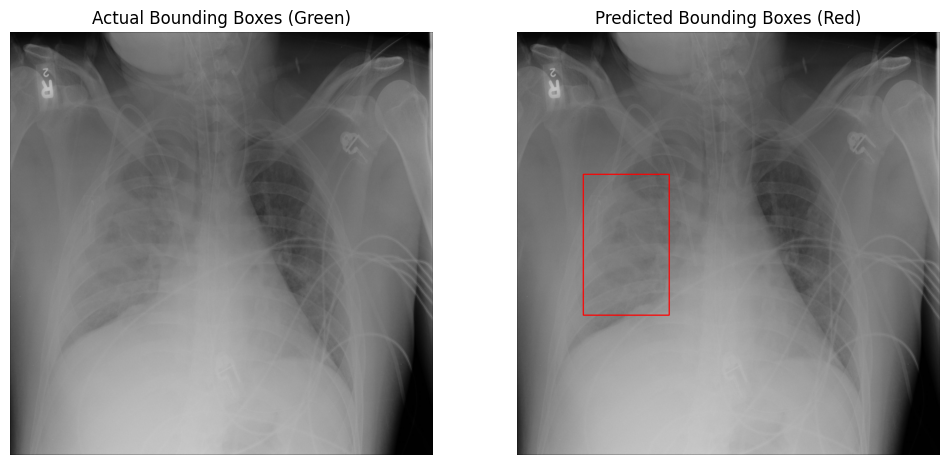

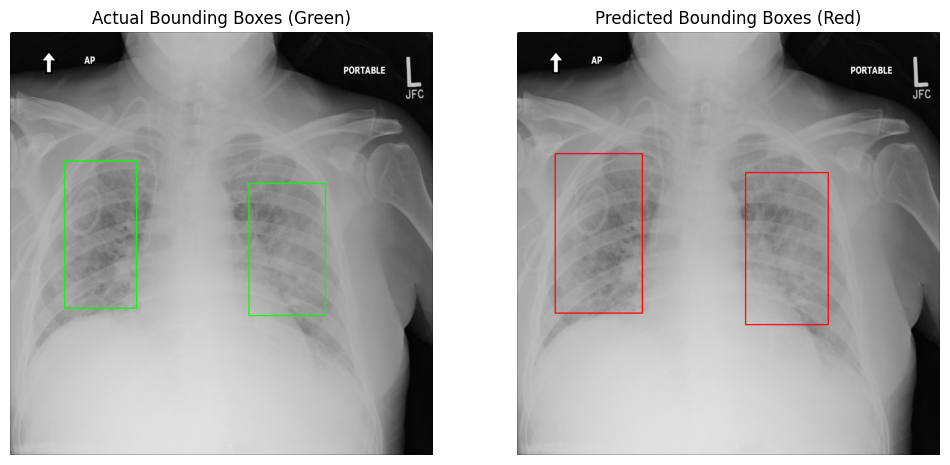

...

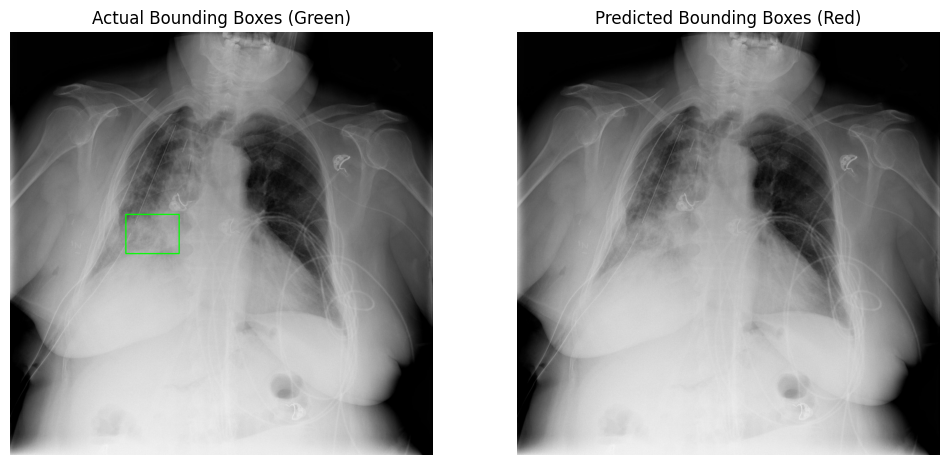

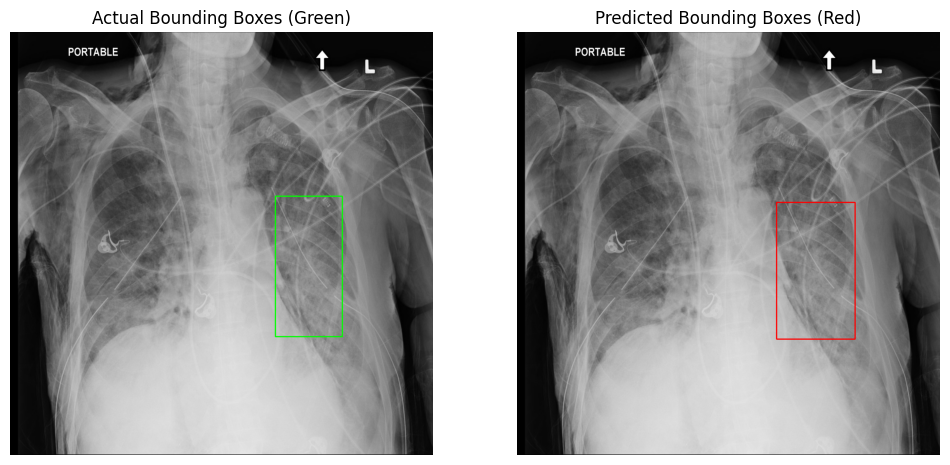

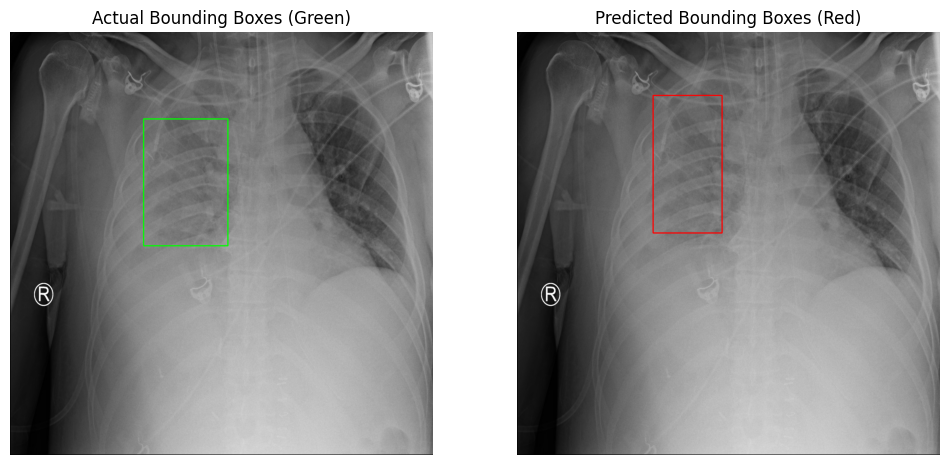

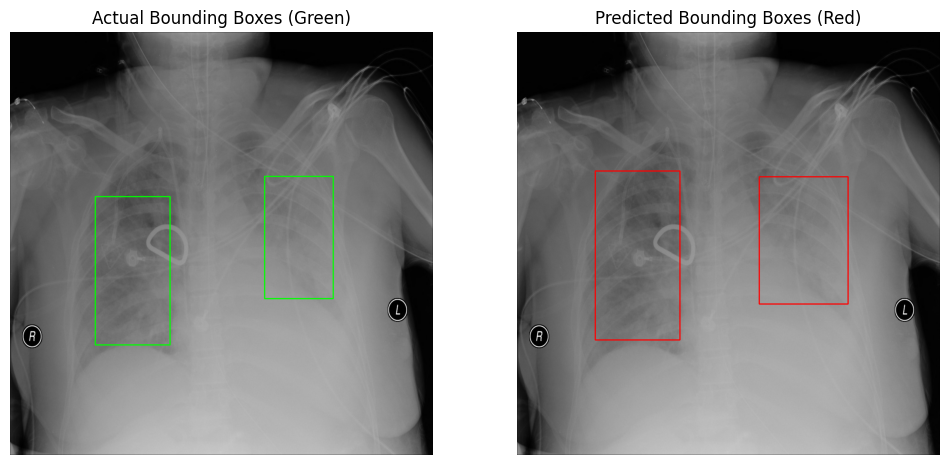

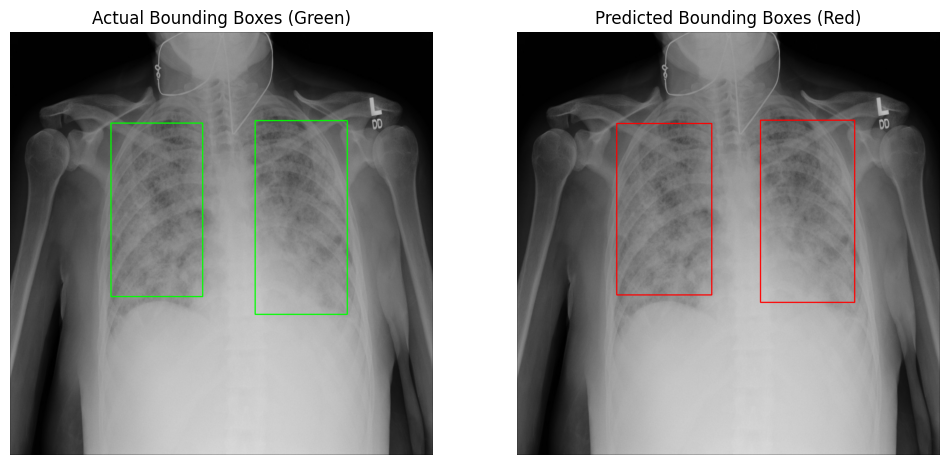

In [ ]:
# Function to draw bounding boxes
def draw_boxes(image, boxes, color):
    # Ensuring image is a NumPy array; if it's a PyTorch tensor, move it to CPU and convert
    if isinstance(image, torch.Tensor):
        image = image.cpu().numpy()

    # Ensuring image is in uint8 format
    if image.dtype != np.uint8:
        image = (image * 255).astype(np.uint8)

    # Convert from CHW (if necessary) to HWC format
    if image.shape[0] in [1, 3]:
        image = np.transpose(image, (1, 2, 0))

    # Convert grayscale to BGR if needed
    if len(image.shape) == 2:
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

    height, width = image.shape[:2]

    # Only scale if boxes is non-empty
    if boxes.size > 0:
        # If boxes are normalized (max value <= 1), scale them to pixel coordinates
        if np.max(boxes) <= 1.0:
            boxes = boxes.copy()  # Work on a copy so we don't modify the original array
            boxes[:, [0, 2]] *= width
            boxes[:, [1, 3]] *= height

    # Draw each bounding box
    for box in boxes:
        x_min, y_min, x_max, y_max = map(int, box)
        # Optionally, ensuring box coordinates are within the image boundaries
        x_min, x_max = max(0, x_min), min(width, x_max)
        y_min, y_max = max(0, y_min), min(height, y_max)
        if x_min >= x_max or y_min >= y_max:
            continue  # Skip invalid boxes
        cv2.rectangle(image, (x_min, y_min), (x_max, y_max), color, 2)

    return image


# Load training dataset for visualization
train_loader = DataLoader(train_dataset, batch_size=1, shuffle=True, collate_fn=lambda x: tuple(zip(*x)))

# Evaluate model on multiple training samples
model_3.eval()  # Set model to evaluation mode
num_images_to_show = 15
displayed_images = 0

with torch.no_grad():
    for images, targets in train_loader:
        if displayed_images >= num_images_to_show:
            break  # Stop once we have displayed enough images

        image = images[0].to(device)
        gt_boxes = targets[0]['boxes'].cpu().numpy()  # Ground truth boxes
        gt_labels = targets[0]['labels'].cpu().numpy()  # Ground truth labels

        # Get model predictions
        predictions = model_3([image])
        pred_boxes = predictions[0]['boxes'].cpu().numpy()  # Predicted boxes
        pred_scores = predictions[0]['scores'].cpu().numpy()  # Confidence scores
        pred_labels = predictions[0]['labels'].cpu().numpy()  # Predicted labels

        # Filter predictions with high confidence
        threshold = 0.4  # Adjust if necessary
        high_confidence_idx = pred_scores > threshold
        pred_boxes = pred_boxes[high_confidence_idx]
        pred_labels = pred_labels[high_confidence_idx]

        # Ensure the case has pneumonia (label 1)
        if 1 not in gt_labels and 1 not in pred_labels:
            continue  # Skip images without pneumonia

        # Convert PyTorch image tensor to NumPy for visualization
        image_np = image.cpu().numpy()

        # Convert CHW (3, H, W) to HWC (H, W, 3)
        image_np = np.transpose(image_np, (1, 2, 0))

        # Draw actual and predicted bounding boxes
        image_actual = draw_boxes(image_np.copy(), gt_boxes, color=(0, 255, 0))  # Green for actual boxes
        image_pred = draw_boxes(image_np.copy(), pred_boxes, color=(255, 0, 0))  # Red for predicted boxes

        # Now display the images
        fig, ax = plt.subplots(1, 2, figsize=(12, 6))
        ax[0].imshow(image_actual, cmap="gray")  # Ensure grayscale images render correctly
        ax[0].set_title("Actual Bounding Boxes (Green)")
        ax[0].axis("off")

        ax[1].imshow(image_pred, cmap="gray")
        ax[1].set_title("Predicted Bounding Boxes (Red)")
        ax[1].axis("off")

        plt.show()

        # ✅ Increment displayed_images count
        displayed_images += 1

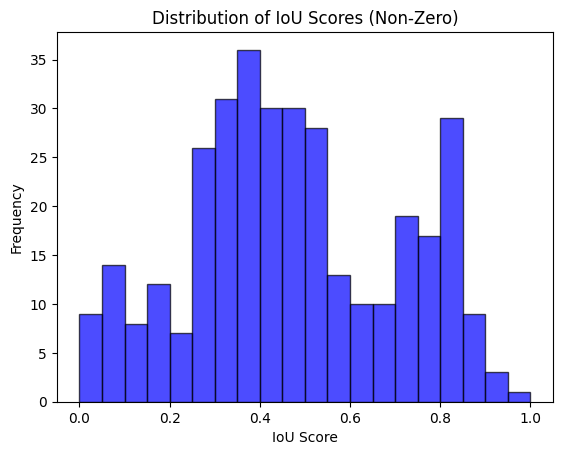

In [ ]:
# --- Compute IoU for all predictions ---
iou_values = []

all_predictions = []
all_targets = []

with torch.no_grad():
    for images, targets in train_loader:
        image = images[0].to(device)
        gt_boxes = targets[0]['boxes'].cpu().numpy()  # Ground truth boxes
        gt_labels = targets[0]['labels'].cpu().numpy()  # Ground truth labels

        # Store ground truths
        all_targets.append({"boxes": gt_boxes, "labels": gt_labels})

        # Get model predictions
        predictions = model_3([image])
        pred_boxes = predictions[0]['boxes'].cpu().numpy()  # Predicted boxes
        pred_scores = predictions[0]['scores'].cpu().numpy()  # Confidence scores
        pred_labels = predictions[0]['labels'].cpu().numpy()  # Predicted labels

        # Store predictions
        all_predictions.append({"boxes": pred_boxes, "scores": pred_scores, "labels": pred_labels})


iou_values = []

for pred, target in zip(all_predictions, all_targets):
    pred_boxes = pred["boxes"]
    target_boxes = target["boxes"]

    for p_box in pred_boxes:
        best_iou = 0.0  # Track the highest IoU for this predicted box

        for t_box in target_boxes:
            iou = compute_iou(p_box, t_box)
            best_iou = max(best_iou, iou)

        # ✅ Only store nonzero IoU values
        if best_iou > 0:
            iou_values.append(best_iou)

# Plot IoU distribution without zero values
plt.hist(iou_values, bins=20, range=(0,1), color='blue', alpha=0.7, edgecolor='black')
plt.xlabel("IoU Score")
plt.ylabel("Frequency")
plt.title("Distribution of IoU Scores (Non-Zero)")
plt.show()

In [ ]:
pneumonia_iou_sum = 0
pneumonia_count = 0

for pred, (image, target) in zip(all_predictions, val_dataset):
    # Check if the image has pneumonia (ground truth boxes exist)
    if "boxes" in target and target["boxes"].numel() > 0:
        # Convert predictions to tensor if needed
        pred_boxes = torch.tensor(pred["boxes"]).cpu().numpy() if len(pred["boxes"]) > 0 else []
        target_boxes = target["boxes"].detach().cpu().numpy()

        for p_box in pred_boxes:
            best_iou = 0.0
            for t_box in target_boxes:
                iou = compute_iou(p_box, t_box)
                best_iou = max(best_iou, iou)
            # Only consider nonzero best IoU values
            if best_iou > 0:
                pneumonia_iou_sum += best_iou
                pneumonia_count += 1

# Compute the average only for pneumonia cases (nonzero best IoU per predicted box)
if pneumonia_count > 0:
    avg_pneumonia_iou = pneumonia_iou_sum / pneumonia_count
    print(f"Average IoU for Pneumonia Cases (Best Matches, Excluding Zero IoUs): {avg_pneumonia_iou:.4f}")
else:
    print("No valid pneumonia cases found in validation set.")

Average IoU for Pneumonia Cases (Best Matches, Excluding Zero IoUs): 0.4615


<b>This model has better Average IoU for Pneumonia Cases (Best Matches, Excluding Zero IoUs) than the Faster R-CNN ResNet-50 FPN model with IoU of 0.2454.

mAP@0.5: 0.2666


<ipython-input-39-2759aa37b7e2>:58: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap = np.trapz(precisions, recalls)


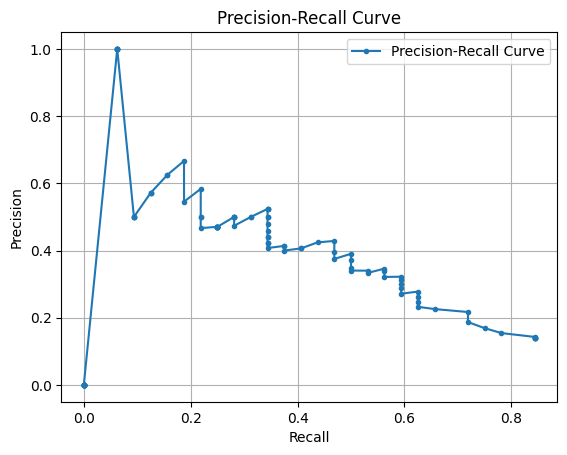

In [ ]:
# based on above results , we plot a PRC Precision recall curve

from collections import defaultdict
# Convert predictions and ground truths to the required format

map_score = compute_map(all_predictions, all_targets, iou_threshold=0.5)
print(f"mAP@0.5: {map_score:.4f}")

# Now compute precision and recall for the PRC curve
precisions = []
recalls = []

for threshold in np.linspace(0, 1, 100): # Varying thresholds to generate curve
  tp = 0
  fp = 0
  fn = 0
  for pred, gt in zip(all_predictions, all_targets):
    pred_boxes = pred['boxes']
    pred_scores = pred['scores']

    gt_boxes = gt['boxes']

    for i in range(len(pred_boxes)):
        if pred_scores[i] > threshold:
            best_iou = 0
            for gt_box in gt_boxes:
                iou = compute_iou(pred_boxes[i], gt_box)
                best_iou = max(best_iou,iou)
            if best_iou > 0.5:
                tp += 1
            else:
                fp += 1

  fn = sum([len(gt['boxes']) for gt in all_targets]) - tp

  if (tp + fp) > 0:
      precision = tp / (tp + fp)
      precisions.append(precision)
  else:
      precisions.append(0)  # Handle the case where no predictions are above the threshold

  if (tp + fn) > 0:
      recall = tp / (tp + fn)
      recalls.append(recall)
  else:
      recalls.append(0) # Handle the case where no ground truth boxes exist

# Plot the Precision-Recall Curve
plt.plot(recalls, precisions, marker='.', label='Precision-Recall Curve')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(True)
plt.legend()
plt.show()

#### <b> The Mean Average Precision comes out to be 0.266 which is less than the Faster R-CNN ResNet50 FPN model.<br></b>
<b>NOTE:</b> More training data can be used to improve the model. Also, Fine-tuning hyperparameters, dataset quality, and model architecture should improve performance.

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>CONCLUSION:</b></font></h3>


#### <b> For Pneumonia Detection mAP is generally more important because missing a pneumonia case (false negatives) is worse than slightly misplacing the bounding box.<br>However, if precise localization is needed for automated segmentation or severity grading, then IoU is crucial.

<h3 style="font-family:'Times New Roman';font-size:25px;"><font color='purple'><b>Step 4: Pickle the model for future prediction.</b></font></h3>

#### <b>Pickling a model allows for easy saving and loading, enabling reuse without retraining the model.

<b>1. Faster R-CNN ResNet50 FPN model

In [ ]:
import os
import pickle

model_dir = "/content/drive/MyDrive/AIML/capstoneproject"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)  # Creating the directory if it doesn't exist

model_path = os.path.join(model_dir, "rcnn_model.pkl")
with open(model_path, "wb") as f:
    pickle.dump(model, f)

print(f"Model saved at: {model_path}")

Model saved at: /content/drive/MyDrive/AIML/capstoneproject/rcnn_model.pkl


<b>2.Faster R-CNN MobileNetV3 Large FPN

In [ ]:
model_dir = "/content/drive/MyDrive/AIML/capstoneproject"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)  # Creating the directory if it doesn't exist

model_path = os.path.join(model_dir, "fasterrcnn_mobilenet_v3_large_fpn_model.pkl")
with open(model_path, "wb") as f:
    pickle.dump(model_3, f)

print(f"Model saved at: {model_path}")

Model saved at: /content/drive/MyDrive/AIML/capstoneproject/fasterrcnn_mobilenet_v3_large_fpn_model.pkl


#### <b> Pickled two models (Faster R-CNN ResNet50 FPN model and Faster R-CNN MobileNetV3 Large FPN) for future predictions, comparison and fine tuning.